# B5.0 — OmniCount-191 region tests (exploratory, development data only)

Step-by-step tests before building the multi-label pipeline (`candidates_v2`). Each part is decided after reviewing the previous one.

- **Part 1 (this run, CPU):** query inventory on OmniCount val minus the 62 test-overlapping images — queries under both protocols (standard = whole domain vocabulary; OmniCount-code = GT-present classes), classes per image, class-name risks for the semantic gate, and the stratified sample for Part 2.
- **Part 2 (after review, GPU):** semantic evidence only (SAN expanded tiled + two-class) — presence discrimination, gate failure rate, region recall, overlap behaviour.
- **Part 3 (after review, GPU):** end-to-end on a small subset.

Test split: only image counts and domain vocabularies are read (for compute planning); no test annotations, no predictions.

In [1]:
# Step 0.1 — Mount Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# ============================================================
# Step 0.2 — Paths, repo, modules
# ============================================================
import importlib, json, re, subprocess, sys
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path
import numpy as np, pandas as pd

PROJECT_ROOT = Path("/content/drive/MyDrive/MSc_Project_ZeroShot_Counting")
RESULTS_ROOT = PROJECT_ROOT / "results"
OMNICOUNT_ROOT = PROJECT_ROOT / "datasets" / "OmniCount-191"
OUT_DIR = RESULTS_ROOT / "B5_0_OmniCount_Region_Tests"
P1_DIR = OUT_DIR / "part1_inventory"
P1_DIR.mkdir(parents=True, exist_ok=True)

REPO_URL = "https://github.com/paulmcchan/Surrey-MScProject-Zero-Shot-Object-Counting.git"
REPO_DIR = Path("/content/Surrey-MScProject-Zero-Shot-Object-Counting")
!rm -rf "{REPO_DIR}"
!git clone -q "{REPO_URL}" "{REPO_DIR}"
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))
REPO_COMMIT = subprocess.check_output(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], text=True).strip()

import src.datasets as datasets_mod
import src.pipeline.semantic as semantic
for m in (datasets_mod, semantic):
    importlib.reload(m)
assert OMNICOUNT_ROOT.exists(), OMNICOUNT_ROOT
print("Repo:", REPO_COMMIT[:10], "| OmniCount root:", OMNICOUNT_ROOT)

Repo: 84da2741b2 | OmniCount root: /content/drive/MyDrive/MSc_Project_ZeroShot_Counting/datasets/OmniCount-191


In [3]:
# ============================================================
# Step 1.1 — Val clean subset (exclude val images sharing a source stem with test; B3R Step 5.3 rule)
# ============================================================
def source_stem(file_name):
    return re.split(r"\.rf\.", file_name)[0]

val_ds = datasets_mod.OmniCount191Dataset(OMNICOUNT_ROOT, split="val", load_images=False)
test_ds = datasets_mod.OmniCount191Dataset(OMNICOUNT_ROOT, split="test", load_images=False)   # names + vocab only

test_stems = defaultdict(set)
for rec in test_ds.index:
    test_stems[rec["domain"]].add(source_stem(rec["image_info"]["file_name"]))

rows = []
for i, rec in enumerate(val_ds.index):
    s = val_ds[i]
    fn = rec["image_info"]["file_name"]
    rows.append({"idx": i, "image_id": s["image_id"], "domain": s["domain"], "file_name": fn,
                 "image_path": s["image_path"], "width": s["width"], "height": s["height"],
                 "stem": source_stem(fn), "leaky": source_stem(fn) in test_stems[s["domain"]],
                 "gt": {c: v["count"] for c, v in s["categories"].items()}})
val_df = pd.DataFrame(rows)
leak = val_df[val_df["leaky"]]
print("Val images:", len(val_df), "| leaky images:", len(leak),
      "| leaky stems by domain:", leak.groupby("domain")["stem"].nunique().to_dict())
EXPECTED_STEMS = {"Fruits": 45, "Supermarket": 15, "Wild": 2}       # B3R Section 5
assert leak.groupby("domain")["stem"].nunique().to_dict() == EXPECTED_STEMS, "differs from B3R audit"
clean = val_df[~val_df["leaky"]].reset_index(drop=True)
print("Val clean images:", len(clean))

Val images: 3578 | leaky images: 64 | leaky stems by domain: {'Fruits': 45, 'Supermarket': 15, 'Wild': 2}
Val clean images: 3514


In [4]:
# ============================================================
# Step 1.2 — Query inventory under both protocols
# ============================================================
VOCAB = val_ds.domain_vocabulary
clean["n_present"] = clean["gt"].apply(len)
clean["objects"] = clean["gt"].apply(lambda g: sum(g.values()))
inv = []
for d, g in clean.groupby("domain"):
    V = len(VOCAB[d]); n = len(g); present = int(g["n_present"].sum())
    inv.append({"domain": d, "images": n, "vocab_size": V,
                "standard_queries": n * V, "present_queries (OmniCount-code)": present,
                "absent_queries": n * V - present, "present_share": present / (n * V),
                "classes/img mean": g["n_present"].mean(), "classes/img median": g["n_present"].median(),
                "classes/img max": g["n_present"].max(), "images with 0 GT": int((g["n_present"] == 0).sum()),
                "objects/img mean": g["objects"].mean()})
inv = pd.DataFrame(inv)
tot = inv[["images", "standard_queries", "present_queries (OmniCount-code)", "absent_queries"]].sum()
display(inv.round(2)); print("TOTAL (val clean):", tot.to_dict())

test_inv = pd.DataFrame([{"domain": d, "images": sum(r["domain"] == d for r in test_ds.index),
                          "vocab_size": len(test_ds.domain_vocabulary[d])} for d in test_ds.domain_vocabulary])
test_inv["standard_queries"] = test_inv["images"] * test_inv["vocab_size"]
print("\nTest split (images x vocabulary only):"); display(test_inv)
print("TOTAL (test) standard queries:", int(test_inv["standard_queries"].sum()))

,domain,images,vocab_size,standard_queries,present_queries (OmniCount-code),absent_queries,present_share,classes/img mean,classes/img median,classes/img max,images with 0 GT,objects/img mean
0,Birds,5,3,15,15,0,1.00,3.00,3.0,3,0,15.20
1,Fruits,256,8,2048,1009,1039,0.49,3.94,4.0,5,0,4.70
2,Pets,15,18,270,62,208,0.23,4.13,5.0,8,0,8.47
3,Satellite,254,23,5842,257,5585,0.04,1.01,1.0,3,2,2.08
4,Supermarket,477,52,24804,566,24238,0.02,1.19,1.0,5,0,14.42
5,Urban,2000,12,24000,3485,20515,0.15,1.74,1.0,6,0,5.44
6,Vegetables,2,13,26,8,18,0.31,4.00,4.0,4,0,21.00
7,Wild,505,4,2020,528,1492,0.26,1.05,1.0,3,0,3.47


TOTAL (val clean): {'images': 3514, 'standard_queries': 59025, 'present_queries (OmniCount-code)': 5930, 'absent_queries': 53095}

Test split (images x vocabulary only):


,domain,images,vocab_size,standard_queries
0,Birds,10,3,30
1,Fruits,303,8,2424
2,Pets,11,18,198
3,Satellite,127,23,2921
4,Supermarket,251,52,13052
5,Urban,1000,12,12000
6,Wild,255,4,1020


TOTAL (test) standard queries: 31645


In [5]:
# ============================================================
# Step 1.3 — Per-class table and class-name risks for the semantic gate
# ============================================================
STUFF = semantic.STUFF_BACKGROUND_VOCAB
cls_rows = []
for d in VOCAB:
    g = clean[clean["domain"] == d]
    for c in VOCAB[d]:
        p = datasets_mod.omnicount_prompt_name(c)
        counts = [gt[c] for gt in g["gt"] if c in gt]
        removed = [s for s in STUFF if s not in semantic.expanded_vocabulary(p)]
        cls_rows.append({"domain": d, "class": c, "prompt": p, "images_present": len(counts),
                         "total_objects": int(sum(counts)), "count_median": float(np.median(counts)) if counts else np.nan,
                         "count_max": max(counts) if counts else 0,
                         "stuff_terms_removed": ", ".join(removed),
                         "stuff_word_in_prompt": ", ".join(s for s in STUFF if re.search(rf"\b{re.escape(s)}\b", p))})
cls_df = pd.DataFrame(cls_rows)
print("Classes never present in val clean:", int((cls_df["images_present"] == 0).sum()), "of", len(cls_df))
print("\nClasses whose prompt overlaps a stuff term (expanded vocabulary drops that term):")
display(cls_df[cls_df["stuff_terms_removed"] != ""][["domain", "class", "prompt", "stuff_terms_removed", "images_present"]])

# Prompted-class pairs within a domain whose prompts share a word (overlap-resolution risk)
pair_rows = []
for d in VOCAB:
    ps = {c: set(datasets_mod.omnicount_prompt_name(c).split()) for c in VOCAB[d]}
    cs = list(ps)
    for i in range(len(cs)):
        for j in range(i + 1, len(cs)):
            shared = ps[cs[i]] & ps[cs[j]]
            if shared:
                co = int(sum((cs[i] in gt) and (cs[j] in gt) for gt in clean[clean["domain"] == d]["gt"]))
                pair_rows.append({"domain": d, "class_a": cs[i], "class_b": cs[j],
                                  "shared_words": ", ".join(sorted(shared)), "co_occur_images": co})
pair_df = pd.DataFrame(pair_rows, columns=["domain", "class_a", "class_b", "shared_words", "co_occur_images"])
print(f"\nWord-sharing class pairs within a domain: {len(pair_df)}")
display(pair_df.sort_values("co_occur_images", ascending=False).head(25))

# Co-occurrence of prompted classes (all pairs) — how often overlap resolution could matter
co = Counter()
for gt in clean["gt"]:
    k = sorted(gt)
    for i in range(len(k)):
        for j in range(i + 1, len(k)):
            co[(k[i], k[j])] += 1
print("Images with >= 2 present classes:", int((clean["n_present"] >= 2).sum()), "of", len(clean))
print("Most frequent co-occurring class pairs:", co.most_common(10))

Classes never present in val clean: 22 of 133

Classes whose prompt overlaps a stuff term (expanded vocabulary drops that term):


,domain,class,prompt,stuff_terms_removed,images_present
33,Satellite,Mountains,mountains,mountain,11
44,Satellite,houses,houses,house,21
46,Satellite,playground,playground,ground,24
51,Satellite,triangular building,triangular building,building,1
93,Supermarket,Watermelon,watermelon,water,7
103,Supermarket,tomato,tomato,mat,8
106,Urban,bus,bus,building,103
107,Urban,car,car,carpet,1908
128,Vegetables,tomato,tomato,mat,0
129,Wild,car,car,carpet,11



Word-sharing class pairs within a domain: 9


,domain,class_a,class_b,shared_words,co_occur_images
3,Urban,trafficlight,trafficlight_red,"light, traffic",78
2,Urban,trafficlight,trafficlight_green,"light, traffic",24
5,Urban,trafficlight_green,trafficlight_red,"light, traffic",14
8,Vegetables,Orange green,Orange ripe,orange,2
4,Urban,trafficlight,trafficlight_yellow,"light, traffic",2
7,Urban,trafficlight_red,trafficlight_yellow,"light, traffic",2
6,Urban,trafficlight_green,trafficlight_yellow,"light, traffic",1
0,Satellite,building,triangular building,building,0
1,Supermarket,Milk,planet-oat-original,milk,0


Images with >= 2 present classes: 1307 of 3514
Most frequent co-occurring class pairs: [(('car', 'pedestrian'), 352), (('car', 'truck'), 214), (('car', 'trafficlight_green'), 198), (('banana', 'sugar apple'), 168), (('car', 'trafficlight'), 156), (('apples', 'banana'), 143), (('car', 'trafficlight_red'), 135), (('banana', 'dragon fruit'), 121), (('apples', 'sugar apple'), 119), (('bike', 'pedestrian'), 110)]


In [6]:
# ============================================================
# Step 1.4 — Stratified sample for Part 2 (seed 0; up to 40 images per domain)
# ============================================================
CAP = 40
sample = pd.concat([g.sample(n=min(CAP, len(g)), random_state=0)
                    for _, g in clean.groupby("domain")], ignore_index=True)
s_inv = sample.groupby("domain").agg(images=("image_id", "size"), present_queries=("n_present", "sum"))
s_inv["standard_queries"] = [len(sample[sample["domain"] == d]) * len(VOCAB[d]) for d in s_inv.index]
display(s_inv); print("Sample totals:", s_inv.sum().to_dict())
print("Sample: images with >= 2 present classes:", int((sample["n_present"] >= 2).sum()))

,images,present_queries,standard_queries
domain,,,
Birds,5,15,15
Fruits,40,154,320
Pets,15,62,270
Satellite,40,41,920
Supermarket,40,41,2080
Urban,40,62,480
Vegetables,2,8,26
Wild,40,40,160


Sample totals: {'images': 222, 'present_queries': 423, 'standard_queries': 4271}
Sample: images with >= 2 present classes: 78


In [7]:
# ============================================================
# Step 1.5 — Save
# ============================================================
clean.assign(gt=clean["gt"].apply(json.dumps)).to_csv(P1_DIR / "B5_0_val_clean_images.csv", index=False)
sample.assign(gt=sample["gt"].apply(json.dumps)).to_csv(P1_DIR / "B5_0_part2_sample.csv", index=False)
inv.to_csv(P1_DIR / "B5_0_query_inventory_val_clean.csv", index=False)
test_inv.to_csv(P1_DIR / "B5_0_query_inventory_test.csv", index=False)
cls_df.to_csv(P1_DIR / "B5_0_class_table.csv", index=False)
pair_df.to_csv(P1_DIR / "B5_0_word_sharing_pairs.csv", index=False)
with open(P1_DIR / "B5_0_part1_metadata.json", "w") as f:
    json.dump({"notebook": "B5_0_OmniCount_Region_Tests (Part 1)", "repo_commit": REPO_COMMIT,
               "date_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
               "val_images": len(val_df), "val_clean_images": len(clean), "leaky_images": len(leak),
               "sample_cap_per_domain": CAP, "sample_seed": 0, "sample_images": len(sample),
               "test_annotations_used": False, "models_run": False}, f, indent=2)
print("Saved to:", P1_DIR)

Saved to: /content/drive/MyDrive/MSc_Project_ZeroShot_Counting/results/B5_0_OmniCount_Region_Tests/part1_inventory


# Part 2 — Semantic evidence only (SAN), sample + targeted overlap set

Development data only (OmniCount val clean). No SAM2; "empty region" stands in for "empty mask set".

| Step | Content | Runtime |
|---|---|---|
| 2.0 | Class-name check: substring rule (v1) vs word-level rule — FSC-147 and OmniCount | CPU |
| 2.1 | Image sets: Part 1 sample (representative) + targeted overlap set (Urban traffic-light variants / car+truck) | CPU |
| 2.2 | Install SAN + detectron2 (as B4b) | GPU |
| 2.3 | Build SAN; single-pass subset SAN; **equivalence test** vs per-class `run_san_vocab` / `run_san` | GPU |
| 2.4 | SAN evidence per image (all domain classes): R0 (tiled expanded), S2 (two-class), overlap resolution (open / present-only), L1/L2, recall at GT points (resumable) | GPU |
| 2.5 | Analyses: presence discrimination, gate failure, region recall, overlap, SAM2 workload, timing | CPU |
| 2.6 | Visual panels | CPU |
| 2.7 | Save summary | CPU |

Run order in a fresh **GPU** session (Part 1 need not be re-run): 0.1, **0.2b**, 2.0, 2.1, 2.2 → (restart only if 2.3 reports a protobuf mismatch; then 0.1, 0.2b, 2.0, 2.1) → 2.3 → 2.4 → 2.5–2.7. Steps 2.5–2.7 can also run later on CPU after 0.1, 0.2b, 2.0, 2.1.

In [8]:
# ============================================================
# Step 0.2b — Paths, repo, modules (Part 2)
# ============================================================
import importlib, json, re, shutil, subprocess, sys, time
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path
import numpy as np, pandas as pd
from tqdm.auto import tqdm

PROJECT_ROOT = Path("/content/drive/MyDrive/MSc_Project_ZeroShot_Counting")
RESULTS_ROOT = PROJECT_ROOT / "results"
OMNICOUNT_ROOT = PROJECT_ROOT / "datasets" / "OmniCount-191"
FSC147_RAW = PROJECT_ROOT / "datasets" / "FSC147" / "raw"
OUT_DIR = RESULTS_ROOT / "B5_0_OmniCount_Region_Tests"
P1_DIR = OUT_DIR / "part1_inventory"
P2_DIR = OUT_DIR / "part2_semantic"
for d in [P2_DIR, P2_DIR / "rows", P2_DIR / "maps", P2_DIR / "panels"]:
    d.mkdir(parents=True, exist_ok=True)

REPO_URL = "https://github.com/paulmcchan/Surrey-MScProject-Zero-Shot-Object-Counting.git"
REPO_DIR = Path("/content/Surrey-MScProject-Zero-Shot-Object-Counting")
if not REPO_DIR.exists():
    !git clone -q "{REPO_URL}" "{REPO_DIR}"
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))
REPO_COMMIT = subprocess.check_output(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], text=True).strip()

import src.datasets as datasets_mod
import src.pipeline.semantic as semantic
for m in (datasets_mod, semantic):
    importlib.reload(m)
STUFF = semantic.STUFF_BACKGROUND_VOCAB
print("Repo:", REPO_COMMIT[:10], "| Part 2 output:", P2_DIR)

Repo: 84da2741b2 | Part 2 output: /content/drive/MyDrive/MSc_Project_ZeroShot_Counting/results/B5_0_OmniCount_Region_Tests/part2_semantic


In [9]:
# ============================================================
# Step 2.0 — Class-name check: v1 substring rule vs a word-level rule (report only)
# ============================================================
def _sing(w):
    if len(w) > 3 and w.endswith("ies"):
        return w[:-3] + "y"
    if len(w) > 3 and w.endswith("es") and re.search(r"(s|x|ch|sh|o)es$", w):
        return w[:-2]
    if len(w) > 2 and w.endswith("s") and not w.endswith("ss"):
        return w[:-1]
    return w

def _tokens(text):
    return {_sing(w) for w in re.findall(r"[a-z]+", text.lower())}

def word_level_vocabulary(class_name, stuff=STUFF):
    ct = _tokens(class_name)
    kept = [s for s in stuff if not (_tokens(s) <= ct or ct <= _tokens(s))]
    return [class_name, "background"] + kept

fsc_classes = sorted({line.strip().split("\t")[1]
                      for line in open(FSC147_RAW / "ImageClasses_FSC147.txt") if len(line.strip().split("\t")) >= 2})
omni_ds = datasets_mod.OmniCount191Dataset(OMNICOUNT_ROOT, split="val", load_images=False)
omni_prompts = sorted({datasets_mod.omnicount_prompt_name(c) for v in omni_ds.domain_vocabulary.values() for c in v})

rule_rows = []
for src_name, names in [("FSC-147", fsc_classes), ("OmniCount", omni_prompts)]:
    for c in names:
        a = set(semantic.expanded_vocabulary(c)[2:]); b = set(word_level_vocabulary(c)[2:])
        if a != b:
            rule_rows.append({"dataset": src_name, "class": c,
                              "dropped_by_v1_only": ", ".join(sorted(b - a)),
                              "dropped_by_word_rule_only": ", ".join(sorted(a - b))})
rule_df = pd.DataFrame(rule_rows, columns=["dataset", "class", "dropped_by_v1_only", "dropped_by_word_rule_only"])
print(f"FSC-147 classes: {len(fsc_classes)} | OmniCount prompts: {len(omni_prompts)}")
print("Classes whose competitor set differs between the two rules:")
display(rule_df)
print("FSC-147 classes affected:", int((rule_df["dataset"] == "FSC-147").sum()),
      "(0 = a word-level rule in v2 would leave every FSC v1 result unchanged)")

FSC-147 classes: 147 | OmniCount prompts: 122
Classes whose competitor set differs between the two rules:


,dataset,class,dropped_by_v1_only,dropped_by_word_rule_only
0,FSC-147,cars,carpet,
1,FSC-147,cups,cupboard,
2,FSC-147,matches,mat,
3,FSC-147,seagulls,sea,
4,FSC-147,tomatoes,mat,
5,FSC-147,watermelon,water,
6,OmniCount,bus,building,
7,OmniCount,car,carpet,
8,OmniCount,houses,house,
9,OmniCount,playground,ground,


FSC-147 classes affected: 6 (0 = a word-level rule in v2 would leave every FSC v1 result unchanged)


In [10]:
# ============================================================
# Step 2.1 — Image sets: representative sample (Part 1) + targeted overlap set
# ============================================================
VOCAB = omni_ds.domain_vocabulary
clean = pd.read_csv(P1_DIR / "B5_0_val_clean_images.csv")
sample = pd.read_csv(P1_DIR / "B5_0_part2_sample.csv")
for df in (clean, sample):
    df["gt"] = df["gt"].apply(json.loads)

TL = {"trafficlight", "trafficlight_red", "trafficlight_green", "trafficlight_yellow"}
def overlap_candidate(gt):
    return len(TL & set(gt)) >= 2 or {"car", "truck"} <= set(gt)
pool = clean[(clean["domain"] == "Urban") & (~clean["image_id"].isin(sample["image_id"]))
             & clean["gt"].apply(overlap_candidate)]
overlap_set = pool.sample(n=min(40, len(pool)), random_state=0)
images = pd.concat([sample.assign(set="sample"), overlap_set.assign(set="overlap")], ignore_index=True)
images["key"] = images["image_id"].str.replace("/", "__")
assert images["image_id"].is_unique
print(f"Representative sample: {len(sample)} images | overlap set: {len(overlap_set)} (pool {len(pool)})")
print("Overlap set: traffic-light pairs", int(overlap_set["gt"].apply(lambda g: len(TL & set(g)) >= 2).sum()),
      "| car+truck", int(overlap_set["gt"].apply(lambda g: {"car", "truck"} <= set(g)).sum()))
dup = {d: [p for p, n in Counter(datasets_mod.omnicount_prompt_name(c) for c in VOCAB[d]).items() if n > 1] for d in VOCAB}
print("Duplicate prompts within a domain (identical maps):", {d: v for d, v in dup.items() if v} or "none")

Representative sample: 222 images | overlap set: 40 (pool 307)
Overlap set: traffic-light pairs 10 | car+truck 31
Duplicate prompts within a domain (identical maps): none


In [11]:
# ============================================================
# Step 2.2 — Install SAN + detectron2 (as B4b JOB A, without diffusers)
# ============================================================
import torch
assert torch.cuda.is_available(), "Switch the runtime to a GPU (T4 or L4)."
DETECTRON2_COMMIT = "1e3e13bbf607b54f62205c4c33922521822fb298"
%cd /content
if not Path("/content/SAN").exists():
    !git clone -q https://github.com/MendelXu/SAN.git /content/SAN
!pip install -q cython scipy shapely timm h5py submitit scikit-image wandb setuptools fvcore tabulate regex opencv-python "open_clip_torch==2.16.0"
!pip uninstall -y -q detectron2
!python -m pip install -q "git+https://github.com/facebookresearch/detectron2.git@{DETECTRON2_COMMIT}"
!pip install -q "accelerate==1.14.0" "diffusers==0.40.0" "transformers==5.16.1"
!pip install -q "protobuf==3.20.3" "iopath==0.1.10"
r = subprocess.run([sys.executable, "-c",
    "import sys; sys.path[:0]=['/content/SAN']; import google.protobuf, detectron2, san; print('IMPORTS OK', google.protobuf.__version__)"],
    cwd="/content", capture_output=True, text=True)
print(r.stdout.strip() or r.stderr[-2000:])
assert r.returncode == 0
print("If 2.3 reports a protobuf mismatch: restart the session, re-run 0.1, 0.2, 2.1, then 2.3.")



/content
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 5.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.8/42.8 kB 5.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 5.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 92.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.0/76.0 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.3/25.3 MB 107.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 231.5/231.5 kB 25.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.1/162.1 kB 23.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.8/62.8 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.7/129.7 kB 8.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver doe

In [12]:
# ============================================================
# Step 2.3 — Build SAN; single-pass subset SAN; equivalence test
# ============================================================
# SAN's vocabulary enters only at the classifier: per-query logits = mask_emb . text_emb (+ a learned
# void column); semantic map = softmax over [vocabulary, void] (void dropped) einsum sigmoid(mask_pred).
# One forward with the union vocabulary therefore gives every class's map exactly: softmax over the
# class's own subset of columns (+ void). Verified here against the per-class functions before use.
import google.protobuf, importlib.metadata as md_meta
assert md_meta.version("protobuf") == "3.20.3" and google.protobuf.__version__ == "3.20.3", \
    "protobuf mismatch — restart, re-run 0.1, 0.2, 2.1, then 2.3."
if "/content/SAN" not in sys.path:
    sys.path.insert(0, "/content/SAN")
import torch, torch.nn.functional as F
from PIL import Image
DEVICE = "cuda"
SAN_ROOT = Path("/content/SAN")
SAN_CKPT = SAN_ROOT / "output" / "san_vit_b_16.pth"
SAN_CKPT.parent.mkdir(parents=True, exist_ok=True)
if not SAN_CKPT.exists():
    shutil.copy2(PROJECT_ROOT / "Checkpoints" / "SAN" / "san_vit_b_16.pth", SAN_CKPT)
san_model = semantic.build_san(SAN_ROOT, SAN_CKPT, device=DEVICE)
assert san_model.sem_seg_postprocess_before_inference, "capture assumes post-processing before inference"
TILE_FRAC = 0.60

def san_capture(img, vocab):
    """One SAN forward; returns (mask_cls logits (Q, V+1), sigmoid(mask_pred) (Q, H, W)) at output size."""
    tensor, h, w = semantic.prepare_san_input(img)
    cap = {}
    def grab(mask_cls, mask_pred):
        cap["cls"] = mask_cls.float(); cap["sig"] = mask_pred.float().sigmoid()
        return torch.zeros((1,) + tuple(mask_pred.shape[1:]), device=mask_pred.device)
    san_model.semantic_inference = grab
    try:
        with torch.no_grad():
            san_model([{"image": tensor.to(DEVICE), "height": h, "width": w, "vocabulary": list(vocab)}])
    finally:
        del san_model.semantic_inference            # restore the class method
    return cap["cls"], cap["sig"]

def subset_maps(cls, sig, idx):
    cols = torch.tensor(list(idx) + [cls.shape[-1] - 1], device=cls.device)
    return torch.einsum("qc,qhw->chw", F.softmax(cls[:, cols], dim=-1)[:, :-1], sig)

def tiled_capture(img, vocab):
    w, h = img.size
    th, tw = int(np.ceil(TILE_FRAC * h)), int(np.ceil(TILE_FRAC * w))
    caps = [(y0, x0) + san_capture(img.crop((x0, y0, x0 + tw, y0 + th)), vocab)
            for y0 in (0, h - th) for x0 in (0, w - tw)]
    return caps, (h, w, th, tw)

def tiled_subset(caps, shape, idx):
    h, w, th, tw = shape
    acc = torch.zeros((len(idx), h, w), device=DEVICE); cnt = torch.zeros((h, w), device=DEVICE)
    for y0, x0, cls, sig in caps:
        acc[:, y0:y0 + th, x0:x0 + tw] += subset_maps(cls, sig, idx); cnt[y0:y0 + th, x0:x0 + tw] += 1.0
    return acc / cnt[None]

def union_vocabulary(prompts):
    return list(dict.fromkeys(list(prompts) + ["background"] + list(STUFF)))

def tiled_scores_reference(img, vocab):          # B4b JOB A, verbatim logic
    w, h = img.size
    th, tw = int(np.ceil(TILE_FRAC * h)), int(np.ceil(TILE_FRAC * w))
    acc = np.zeros((len(vocab), h, w), np.float32); cnt = np.zeros((h, w), np.float32)
    for y0 in (0, h - th):
        for x0 in (0, w - tw):
            seg = semantic.run_san_vocab(san_model, img.crop((x0, y0, x0 + tw, y0 + th)), vocab, DEVICE)
            acc[:, y0:y0 + th, x0:x0 + tw] += seg; cnt[y0:y0 + th, x0:x0 + tw] += 1.0
    return acc / cnt[None]

# ---- Equivalence test: 3 images (Supermarket, Urban, Fruits), one present + one absent class each
eq_rows = []
for dom in ["Supermarket", "Urban", "Fruits"]:
    r = sample[sample["domain"] == dom].iloc[0]
    img = Image.open(r["image_path"]).convert("RGB")
    gt = r["gt"]
    prompts = [datasets_mod.omnicount_prompt_name(c) for c in VOCAB[dom]]
    U = union_vocabulary(prompts)
    caps, shape = tiled_capture(img, U); cls_u, sig_u = san_capture(img, U)
    present = list(gt)[0]; absent = next(c for c in VOCAB[dom] if c not in gt)
    for c, kind in [(present, "present"), (absent, "absent")]:
        p = datasets_mod.omnicount_prompt_name(c)
        ev = semantic.expanded_vocabulary(p)
        ref = tiled_scores_reference(img, ev)
        new = tiled_subset(caps, shape, [U.index(x) for x in ev]).cpu().numpy()
        t_ref, b_ref = semantic.run_san(san_model, img, p, DEVICE)
        m2 = subset_maps(cls_u, sig_u, [U.index(p), U.index("background")]).cpu().numpy()
        eq_rows.append({"domain": dom, "class": c, "kind": kind, "union_size": len(U),
                        "tiled max|diff|": float(np.abs(ref - new).max()),
                        "tiled argmax agree": float((ref.argmax(0) == new.argmax(0)).mean()),
                        "two-class max|diff|": float(max(np.abs(t_ref - m2[0]).max(), np.abs(b_ref - m2[1]).max())),
                        "two-class region agree": float(((t_ref > b_ref) == (m2[0] > m2[1])).mean())})
    del caps, cls_u, sig_u; torch.cuda.empty_cache()
eq_df = pd.DataFrame(eq_rows)
display(eq_df)
EQUIV_PASS = bool((eq_df["tiled max|diff|"] < 1e-4).all() and (eq_df["two-class max|diff|"] < 1e-4).all()
                  and (eq_df["tiled argmax agree"] > 0.9999).all() and (eq_df["two-class region agree"] > 0.9999).all())
print("EQUIVALENCE:", "PASS — single-pass subset SAN reproduces the per-class functions" if EQUIV_PASS
      else "FAIL — do not run 2.4; send this table")

/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
100%|████████████████████████████████████████| 351M/351M [00:01<00:00, 233MiB/s]
/content/SAN/san/model/side_adapter/timm_wrapper.py:24: UserWarning: Unused kwargs are provided:{'dynamic_img_pad': False, 'device': None, 'dtype': None}.
  warnings.warn(f"Unused kwargs are provided:{kwargs}.")


,domain,class,kind,union_size,tiled max|diff|,tiled argmax agree,two-class max|diff|,two-class region agree
0,Supermarket,apples,present,96,0.000000,1.0,1.668930e-06,1.0
1,Supermarket,Artichoke,absent,96,0.000000,1.0,4.172325e-07,1.0
2,Urban,biker,present,56,0.000002,1.0,5.960464e-07,1.0
3,Urban,bike,absent,56,0.000002,1.0,3.695488e-06,1.0
4,Fruits,guava,present,52,0.000002,1.0,8.940697e-07,1.0
5,Fruits,dragon fruit,absent,52,0.000002,1.0,8.642673e-07,1.0


EQUIVALENCE: PASS — single-pass subset SAN reproduces the per-class functions


In [13]:
# ============================================================
# Step 2.4 — SAN evidence per image, all domain classes (resumable)
# ============================================================
assert EQUIV_PASS
ROWS, MAPS = P2_DIR / "rows", P2_DIR / "maps"

def points_in(region, pts, sx, sy):
    if not pts:
        return np.nan
    h, w = region.shape
    xs = np.clip(np.round(np.array([p[0] for p in pts]) * sx).astype(int), 0, w - 1)
    ys = np.clip(np.round(np.array([p[1] for p in pts]) * sy).astype(int), 0, h - 1)
    return float(region[ys, xs].mean())

def resolve(R, T, members):
    """Score-based overlap resolution among `members` (non-empty R0): pixel -> class with highest T0."""
    out = {c: R[c] for c in R}
    if len(members) >= 2:
        stack = torch.stack([torch.where(R[c], T[c], torch.full_like(T[c], -1.0)) for c in members])
        win = stack.argmax(0)
        for i, c in enumerate(members):
            out[c] = R[c] & (win == i)
    return out

def free_space(res, members, c, shape):
    others = [res[k] for k in members if k != c]
    return ~torch.stack(others).any(0) if others else torch.ones(shape, dtype=torch.bool, device=DEVICE)

todo = [r for r in images.itertuples(index=False) if not (ROWS / f"{r.key}.json").exists()]
print(f"Done: {len(images) - len(todo)} | to process: {len(todo)}")
t_start = time.time()
for r in tqdm(todo, desc="SAN evidence"):
    t0 = time.time()
    img = Image.open(r.image_path).convert("RGB")
    W, H = img.size
    sx, sy = W / r.width, H / r.height                       # annotation -> image scale (normally 1)
    cats = omni_ds[int(r.idx)]["categories"]
    classes = VOCAB[r.domain]
    prompt = {c: datasets_mod.omnicount_prompt_name(c) for c in classes}
    U = union_vocabulary(prompt.values())
    caps, shape = tiled_capture(img, U); cls_u, sig_u = san_capture(img, U)
    t_san = time.time() - t0
    R0, T0, S2, T2, feat = {}, {}, {}, {}, {}
    for c in classes:
        p = prompt[c]
        T = tiled_subset(caps, shape, [U.index(x) for x in semantic.expanded_vocabulary(p)])
        R0[c] = T.argmax(0) == 0; T0[c] = T[0]
        comp = T[1:].max(0).values
        m2 = subset_maps(cls_u, sig_u, [U.index(p), U.index("background")])
        S2[c] = m2[0] > m2[1]; T2[c] = m2[0]
        feat[c] = {"t0_peak": float(T[0].max()), "t0_margin_peak": float((T[0] - comp).max()),
                   "t2_peak": float(m2[0].max()), "t2_margin_peak": float((m2[0] - m2[1]).max())}
        del T, comp, m2
    nonempty = [c for c in classes if bool(R0[c].any())]
    present = [c for c in classes if c in r.gt]
    res = {"open": resolve(R0, T0, nonempty),
           "present_only": resolve(R0, T0, [c for c in nonempty if c in present])}
    mem = {"open": nonempty, "present_only": [c for c in nonempty if c in present]}
    rows = []
    for c in classes:
        is_p = c in present
        pts = cats[c]["points"] if is_p else []
        row = {"set": r.set, "image_id": r.image_id, "domain": r.domain, "class": c, "prompt": prompt[c],
               "present": is_p, "gt_count": int(r.gt.get(c, 0)),
               "r0_frac": float(R0[c].float().mean()), "s2_frac": float(S2[c].float().mean()),
               "recall_r0": points_in(R0[c].cpu().numpy(), pts, sx, sy),
               "recall_s2": points_in(S2[c].cpu().numpy(), pts, sx, sy), **feat[c]}
        for mode in ("open", "present_only"):
            if mode == "present_only" and not is_p:
                continue
            Rr = res[mode][c]; Fc = free_space(res[mode], mem[mode], c, R0[c].shape)
            L1 = S2[c] & Fc
            level = 0 if bool(Rr.any()) else 1 if bool(L1.any()) else 2
            final = Rr if level == 0 else L1 if level == 1 else Fc
            row.update({f"{mode}_r0res_frac": float(Rr.float().mean()),
                        f"{mode}_l1_frac": float(L1.float().mean()), f"{mode}_l2_frac": float(Fc.float().mean()),
                        f"{mode}_level": level, f"{mode}_final_frac": float(final.float().mean()),
                        f"{mode}_recall_r0res": points_in(Rr.cpu().numpy(), pts, sx, sy),
                        f"{mode}_recall_final": points_in(final.cpu().numpy(), pts, sx, sy)})
        rows.append(row)
    pairs = []
    for i in range(len(nonempty)):
        for j in range(i + 1, len(nonempty)):
            a, b = nonempty[i], nonempty[j]
            inter = float((R0[a] & R0[b]).float().sum())
            if inter > 0:
                small = float(min(R0[a].float().sum(), R0[b].float().sum()))
                pairs.append({"a": a, "b": b, "a_present": a in present, "b_present": b in present,
                              "inter_over_smaller": inter / small})
    save = {}
    for c in classes:
        if c in present or bool(R0[c].any()):
            save[f"R0__{c}"] = np.packbits(R0[c].cpu().numpy())
        if c in present:
            save[f"R0open__{c}"] = np.packbits(res["open"][c].cpu().numpy())
            save[f"S2__{c}"] = np.packbits(S2[c].cpu().numpy())
            save[f"T0__{c}"] = T0[c].cpu().numpy().astype(np.float16)
    np.savez_compressed(MAPS / f"{r.key}.npz", shape=np.array([H, W]), **save)
    with open(ROWS / f"{r.key}.json", "w") as f:
        json.dump({"image_id": r.image_id, "set": r.set, "domain": r.domain, "H": H, "W": W,
                   "n_classes": len(classes), "t_san_s": t_san, "t_total_s": time.time() - t0,
                   "rows": rows, "pairs": pairs},
                  f, default=lambda o: None if isinstance(o, float) and np.isnan(o) else o)
    del caps, cls_u, sig_u, R0, T0, S2, T2, res
    torch.cuda.empty_cache()
print(f"Elapsed: {(time.time() - t_start) / 60:.1f} min")

Done: 262 | to process: 0


SAN evidence: 0it [00:00, ?it/s]

Elapsed: 0.0 min


In [14]:
# ============================================================
# Step 2.5a — Load rows (local copy first) and presence discrimination
# ============================================================
from sklearn.metrics import roc_auc_score
MAPS = P2_DIR / "maps"
LOCAL = Path("/content/B5_0_rows_local")
if LOCAL.exists():
    shutil.rmtree(LOCAL)
shutil.copytree(P2_DIR / "rows", LOCAL)
recs = [json.load(open(p)) for p in sorted(LOCAL.glob("*.json"))]
assert len(recs) == len(images), (len(recs), len(images))
q = pd.DataFrame([row for rec in recs for row in rec["rows"]])
pairs = pd.DataFrame([{"image_id": rec["image_id"], "set": rec["set"], "domain": rec["domain"], **p}
                      for rec in recs for p in rec["pairs"]])
img_t = pd.DataFrame([{k: rec[k] for k in ["image_id", "set", "domain", "H", "W", "n_classes", "t_san_s", "t_total_s"]}
                      for rec in recs])
qs = q[q["set"] == "sample"]                                  # representative statistics: sample only
print(f"Queries: {len(q)} (sample {len(qs)}: present {int(qs['present'].sum())}, absent {int((~qs['present']).sum())})")

def rate(x):
    return f"{x.mean():.2f}" if len(x) else "-"
pres_rows = []
for d, g in list(qs.groupby("domain")) + [("ALL", qs)]:
    P, A = g[g["present"]], g[~g["present"]]
    row = {"domain": d, "present": len(P), "absent": len(A),
           "R0≠∅ | present": rate(P["r0_frac"] > 0), "R0≠∅ | absent": rate(A["r0_frac"] > 0),
           "R0res≠∅ | present (open)": rate(P["open_r0res_frac"] > 0), "R0res≠∅ | absent (open)": rate(A["open_r0res_frac"] > 0),
           "S2≠∅ | present": rate(P["s2_frac"] > 0), "S2≠∅ | absent": rate(A["s2_frac"] > 0)}
    for s in ["r0_frac", "t0_peak", "t0_margin_peak", "s2_frac", "t2_peak", "t2_margin_peak"]:
        row[f"AUC {s}"] = (round(roc_auc_score(g["present"], g[s]), 3)
                           if g["present"].nunique() == 2 else np.nan)
    pres_rows.append(row)
pres_df = pd.DataFrame(pres_rows)
print("Presence discrimination (sample; AUC: 0.5 = chance, 1.0 = perfect):")
display(pres_df)

Queries: 4751 (sample 4271: present 423, absent 3848)
Presence discrimination (sample; AUC: 0.5 = chance, 1.0 = perfect):


,domain,present,absent,R0≠∅ | present,R0≠∅ | absent,R0res≠∅ | present (open),R0res≠∅ | absent (open),S2≠∅ | present,S2≠∅ | absent,AUC r0_frac,AUC t0_peak,AUC t0_margin_peak,AUC s2_frac,AUC t2_peak,AUC t2_margin_peak
0,Birds,15,0,1.00,-,0.67,-,1.00,-,NaN,NaN,NaN,NaN,NaN,NaN
1,Fruits,154,166,0.99,0.87,0.84,0.27,0.99,0.99,0.663,0.819,0.809,0.610,0.829,0.830
2,Pets,62,208,0.90,0.40,0.63,0.02,0.84,0.16,0.809,0.883,0.864,0.864,0.903,0.873
3,Satellite,41,879,0.51,0.17,0.44,0.12,0.95,0.62,0.686,0.763,0.696,0.761,0.807,0.796
4,Supermarket,41,2039,0.66,0.18,0.51,0.04,0.71,0.33,0.772,0.835,0.721,0.748,0.860,0.760
5,Urban,62,418,1.00,0.72,0.94,0.32,1.00,0.96,0.808,0.906,0.902,0.626,0.887,0.884
6,Vegetables,8,18,1.00,0.94,0.75,0.17,1.00,1.00,0.882,0.972,0.972,0.618,0.931,0.931
7,Wild,40,120,0.90,0.50,0.90,0.44,0.97,0.77,0.702,0.731,0.711,0.451,0.713,0.736
8,ALL,423,3848,0.89,0.29,0.75,0.11,0.94,0.50,0.844,0.890,0.877,0.718,0.877,0.870


In [15]:
# ============================================================
# Step 2.5b — Gate failure and region recall for present classes
# ============================================================
P = qs[qs["present"]]
fail_rows = []
for d, g in list(P.groupby("domain")) + [("ALL", P)]:
    fail_rows.append({"domain": d, "present_queries": len(g),
                      "R0 empty": int((g["r0_frac"] == 0).sum()),
                      "R0res empty (open)": int((g["open_r0res_frac"] == 0).sum()),
                      "R0res empty (present-only)": int((g["present_only_r0res_frac"] == 0).sum()),
                      "S2 empty": int((g["s2_frac"] == 0).sum()),
                      "ladder→L1 (present-only)": int((g["present_only_level"] == 1).sum()),
                      "ladder→L2 (present-only)": int((g["present_only_level"] == 2).sum())})
fail_df = pd.DataFrame(fail_rows)
print("Gate failure for present classes (sample):"); display(fail_df)
print("\nClasses with R0 empty while present (sample):")
display(P[P["r0_frac"] == 0].groupby(["domain", "class"]).size().sort_values(ascending=False).head(20).to_frame("n"))

rec_cols = {"R0": "recall_r0", "R0res open": "open_recall_r0res", "R0res present-only": "present_only_recall_r0res",
            "S2": "recall_s2", "ladder final (present-only)": "present_only_recall_final"}
rec_rows = []
for d, g in list(P.groupby("domain")) + [("ALL", P)]:
    row = {"domain": d}
    for k, col in rec_cols.items():
        row[f"{k} mean"] = g[col].mean()
        row[f"{k} <0.5"] = (g[col] < 0.5).mean()
    rec_rows.append(row)
rec_df = pd.DataFrame(rec_rows)
print("\nRegion recall at GT points (share of a present class's GT points inside its region; sample):")
display(rec_df.round(2))

Gate failure for present classes (sample):


,domain,present_queries,R0 empty,R0res empty (open),R0res empty (present-only),S2 empty,ladder→L1 (present-only),ladder→L2 (present-only)
0,Birds,15,0,5,5,0,5,0
1,Fruits,154,2,24,13,1,12,1
2,Pets,62,6,23,22,10,12,10
3,Satellite,41,20,23,20,2,19,1
4,Supermarket,41,14,20,14,12,2,12
5,Urban,62,0,4,1,0,1,0
6,Vegetables,8,0,2,2,0,2,0
7,Wild,40,4,4,4,1,3,1
8,ALL,423,46,105,81,26,56,25



Classes with R0 empty while present (sample):


n
domain      class          
Supermarket Coffee       11
Satellite   playground    5
            bareland      4
Wild        wildboar      4
Satellite   Forest        3
            desert        3
Fruits      sugar apple   2
Pets        Turtles       2
Satellite   Mountains     2
            Church        2
Supermarket eggs          2
Pets        Rabbit        1
            Snake         1
            Chicken       1
            Fish          1
Satellite   building      1
Supermarket Drinks        1


Region recall at GT points (share of a present class's GT points inside its region; sample):


,domain,R0 mean,R0 <0.5,R0res open mean,R0res open <0.5,R0res present-only mean,R0res present-only <0.5,S2 mean,S2 <0.5,ladder final (present-only) mean,ladder final (present-only) <0.5
0,Birds,1.00,0.00,0.36,0.67,0.36,0.67,1.00,0.00,0.36,0.67
1,Fruits,0.85,0.13,0.68,0.29,0.79,0.19,0.94,0.05,0.82,0.16
2,Pets,0.73,0.24,0.48,0.47,0.50,0.45,0.70,0.27,0.52,0.42
3,Satellite,0.20,0.78,0.18,0.80,0.20,0.78,0.93,0.07,0.68,0.32
4,Supermarket,0.50,0.51,0.24,0.80,0.50,0.51,0.68,0.29,0.83,0.17
5,Urban,0.80,0.13,0.54,0.39,0.72,0.23,0.87,0.10,0.73,0.21
6,Vegetables,0.99,0.00,0.45,0.50,0.52,0.38,1.00,0.00,0.52,0.38
7,Wild,0.86,0.10,0.83,0.12,0.86,0.10,0.95,0.02,0.95,0.00
8,ALL,0.74,0.24,0.54,0.43,0.64,0.34,0.87,0.11,0.74,0.23


In [16]:
# ============================================================
# Step 2.5c — Overlap behaviour and resolution damage (sample and overlap set)
# ============================================================
if len(pairs):
    pairs["type"] = np.where(pairs["a_present"] & pairs["b_present"], "present-present",
                     np.where(pairs["a_present"] | pairs["b_present"], "present-absent", "absent-absent"))
    print("Overlapping R0 pairs (inter / smaller region):")
    display(pairs.groupby(["set", "type"])["inter_over_smaller"].describe()[["count", "mean", "50%", "max"]].round(2))
    print("Most frequent overlapping class pairs (overlap > 0.2):")
    display(pairs[pairs["inter_over_smaller"] > 0.2].groupby(["set", "a", "b", "type"]).size()
            .sort_values(ascending=False).head(20).to_frame("images"))
for mode in ("open", "present_only"):
    g = q[q["present"] & (q["r0_frac"] > 0)].copy()
    g["kept"] = g[f"{mode}_r0res_frac"] / g["r0_frac"]
    g["recall_change"] = g[f"{mode}_recall_r0res"] - g["recall_r0"]
    print(f"\nResolution damage to present classes — {mode}:")
    display(g.groupby("set").agg(n=("kept", "size"), emptied=("kept", lambda x: int((x == 0).sum())),
                                 shrunk_over_half=("kept", lambda x: int((x < 0.5).sum())),
                                 mean_recall_change=("recall_change", "mean")).round(3))
ov = q[(q["set"] == "overlap") & q["present"]]
print("\nOverlap set — present traffic-light / car / truck classes:")
display(ov[ov["class"].isin(list(TL) + ["car", "truck"])].groupby("class")[
    ["recall_r0", "open_recall_r0res", "present_only_recall_r0res", "recall_s2"]].mean().round(2))

Overlapping R0 pairs (inter / smaller region):


count  mean   50%  max
set     type                                    
overlap absent-absent     463.0  0.63  0.86  1.0
        present-absent    595.0  0.63  0.81  1.0
        present-present   109.0  0.58  0.66  1.0
sample  absent-absent    4981.0  0.81  1.00  1.0
        present-absent   1641.0  0.81  0.98  1.0
        present-present   358.0  0.73  0.88  1.0

Most frequent overlapping class pairs (overlap > 0.2):


images
set     a          b           type                   
sample  apples     guava       present-absent       34
        car        truck       present-absent       33
overlap bus        car         present-absent       33
sample  bus        car         present-absent       32
overlap car        truck       present-present      31
sample  bus        truck       absent-absent        29
        pineapple  sugar apple present-absent       29
        banana     pear        present-absent       28
        car        pedestrian  present-absent       28
        motorbiker pedestrian  absent-absent        28
        motorbike  pedestrian  absent-absent        27
        pedestrian truck       absent-absent        27
        apples     pineapple   present-absent       27
overlap bus        truck       present-absent       26
sample  guava      oren        present-absent       26
        people     wildboar    present-absent       26
        car        motorbiker  present-absent       25
        apples     pear        present-absent       25
overlap car        motorbiker  present-absent       25
        biker      motorbiker  absent-absent        25


Resolution damage to present classes — open:


,n,emptied,shrunk_over_half,mean_recall_change
set,,,,
overlap,116,12,61,-0.177
sample,377,59,176,-0.223



Resolution damage to present classes — present_only:


,n,emptied,shrunk_over_half,mean_recall_change
set,,,,
overlap,116,7,48,-0.109
sample,377,35,129,-0.113



Overlap set — present traffic-light / car / truck classes:


,recall_r0,open_recall_r0res,present_only_recall_r0res,recall_s2
class,,,,
car,0.89,0.61,0.68,0.99
trafficlight,0.00,0.00,0.00,0.33
trafficlight_green,0.21,0.15,0.21,0.74
trafficlight_red,0.06,0.00,0.00,0.15
truck,0.84,0.69,0.77,0.94


In [17]:
# ============================================================
# Step 2.5d — SAM2 workload implied by the gate, and timing
# ============================================================
work = qs.assign(run_open=qs["open_r0res_frac"] > 0).groupby("domain").agg(
    queries=("run_open", "size"), sam2_runs_open=("run_open", "sum"),
    present=("present", "sum"),
    present_missed=("run_open", lambda x: int((~x & qs.loc[x.index, "present"]).sum())),
    absent_kept=("run_open", lambda x: int((x & ~qs.loc[x.index, "present"]).sum())))
work["share_run"] = work["sam2_runs_open"] / work["queries"]
print("Open-query mode: SAM2 runs only where the resolved R0 is non-empty (sample):")
display(work.round(3)); print("ALL:", work[["queries", "sam2_runs_open", "present", "present_missed", "absent_kept"]].sum().to_dict())

ts = img_t[img_t["set"] == "sample"]
print(f"\nSAN time per image (sample): mean {ts['t_san_s'].mean():.2f} s, total per image incl. analysis {ts['t_total_s'].mean():.2f} s")
inv = pd.read_csv(P1_DIR / "B5_0_query_inventory_val_clean.csv")
per_dom = ts.groupby("domain")["t_san_s"].mean()
est = (inv.set_index("domain")["images"] * per_dom.reindex(inv["domain"]).values).sum() / 3600
print(f"Estimated SAN time, full val clean (single-pass): {est:.1f} h")

Open-query mode: SAM2 runs only where the resolved R0 is non-empty (sample):


,queries,sam2_runs_open,present,present_missed,absent_kept,share_run
domain,,,,,,
Birds,15,10,15,5,0,0.667
Fruits,320,174,154,24,44,0.544
Pets,270,44,62,23,5,0.163
Satellite,920,121,41,23,103,0.132
Supermarket,2080,100,41,20,79,0.048
Urban,480,190,62,4,132,0.396
Vegetables,26,9,8,2,3,0.346
Wild,160,89,40,4,53,0.556


ALL: {'queries': 4271, 'sam2_runs_open': 737, 'present': 423, 'present_missed': 105, 'absent_kept': 419}

SAN time per image (sample): mean 0.65 s, total per image incl. analysis 0.92 s
Estimated SAN time, full val clean (single-pass): 0.6 h


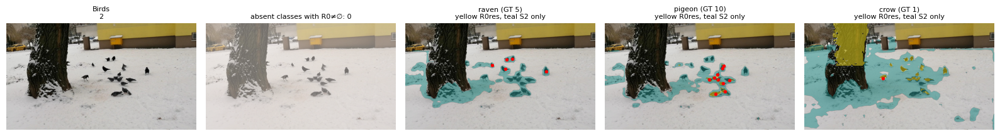

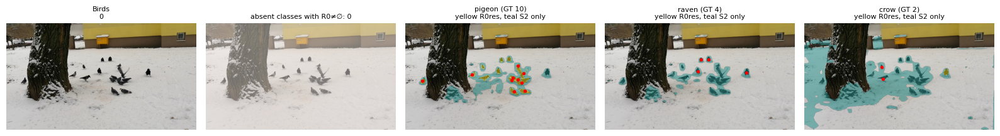

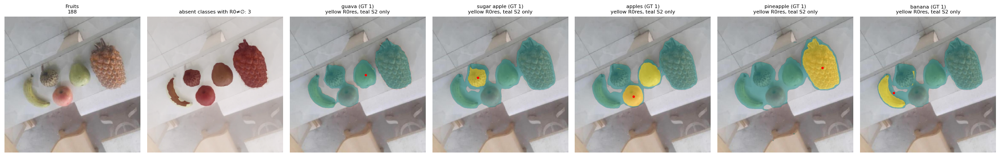

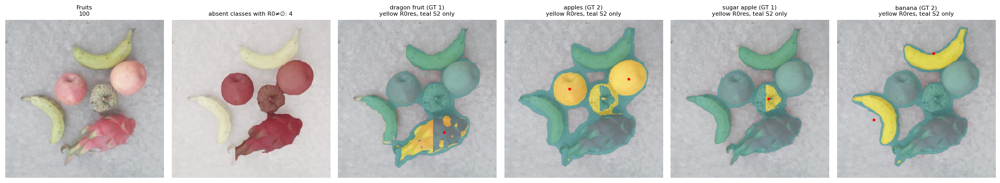

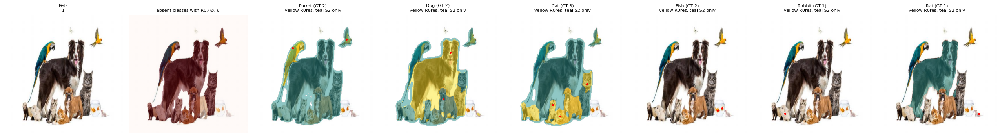

...

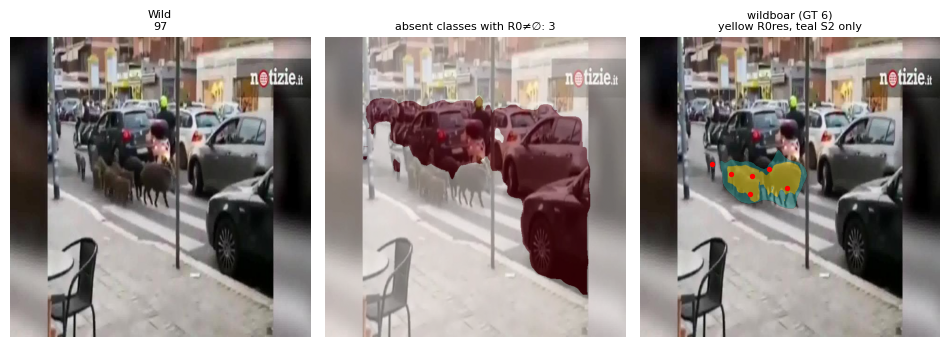

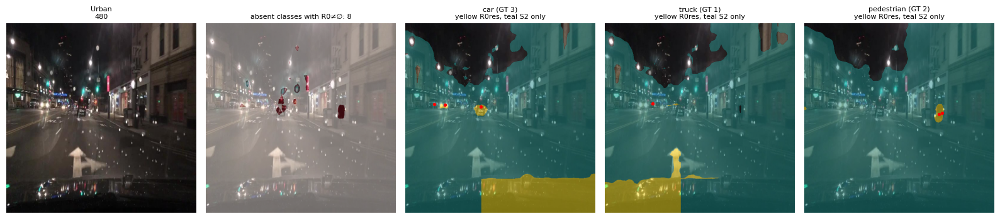

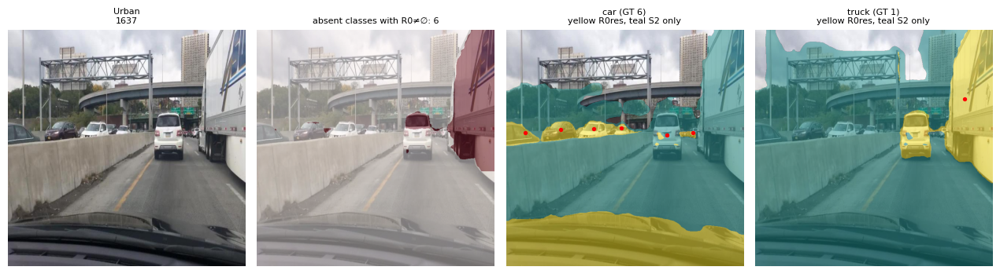

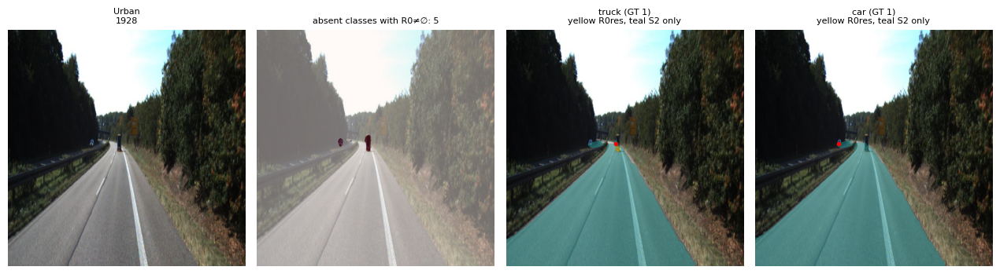

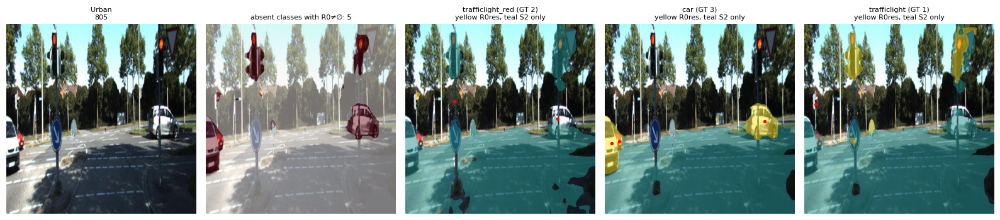

In [18]:
# ============================================================
# Step 2.6 — Visual panels (2 per domain from the sample + 4 from the overlap set)
# ============================================================
import matplotlib.pyplot as plt
from PIL import Image
def unpack(npz, key, H, W):
    return np.unpackbits(npz[key])[:H * W].reshape(H, W).astype(bool)

pick = pd.concat([images[images["set"] == "sample"].groupby("domain").head(2),
                  images[images["set"] == "overlap"].head(4)])
for r in pick.itertuples(index=False):
    npz = np.load(MAPS / f"{r.key}.npz"); H, W = npz["shape"]
    img = np.asarray(Image.open(r.image_path).convert("RGB"))
    cats = omni_ds[int(r.idx)]["categories"]; present = list(r.gt)
    absent_nonempty = [k[4:] for k in npz.files if k.startswith("R0__") and k[4:] not in present]
    n = 2 + len(present)
    fig, ax = plt.subplots(1, n, figsize=(3.2 * n, 3.4))
    ax[0].imshow(img); ax[0].set_title(f"{r.domain}\n{r.image_id.split('/')[-1]}", fontsize=8)
    union_abs = np.zeros((H, W), bool)
    for c in absent_nonempty:
        union_abs |= unpack(npz, f"R0__{c}", H, W)
    ax[1].imshow(img); ax[1].imshow(union_abs, alpha=0.45, cmap="Reds")
    ax[1].set_title(f"absent classes with R0≠∅: {len(absent_nonempty)}", fontsize=8)
    for i, c in enumerate(present):
        a = ax[2 + i]; a.imshow(img)
        r0o = unpack(npz, f"R0open__{c}", H, W); s2 = unpack(npz, f"S2__{c}", H, W)
        a.imshow(np.where(r0o, 1.0, np.where(s2, 0.5, np.nan)), alpha=0.5, cmap="viridis", vmin=0, vmax=1)
        pts = np.array(cats[c]["points"])
        if len(pts):
            a.scatter(pts[:, 0] * W / r.width, pts[:, 1] * H / r.height, s=8, c="red")
        a.set_title(f"{c} (GT {r.gt[c]})\nyellow R0res, teal S2 only", fontsize=8)
    for a in ax:
        a.axis("off")
    plt.tight_layout(); plt.savefig(P2_DIR / "panels" / f"{r.key}.png", dpi=90); plt.show()

In [19]:
# ============================================================
# Step 2.7 — Save summary
# ============================================================
q.to_csv(P2_DIR / "B5_0_p2_queries.csv", index=False)
pairs.to_csv(P2_DIR / "B5_0_p2_overlap_pairs.csv", index=False)
img_t.to_csv(P2_DIR / "B5_0_p2_images.csv", index=False)
for name, df in [("presence", pres_df), ("gate_failure", fail_df), ("recall", rec_df), ("workload", work),
                 ("equivalence", eq_df if "eq_df" in globals() else pd.DataFrame()), ("name_rules", rule_df)]:
    df.to_csv(P2_DIR / f"B5_0_p2_{name}.csv", index=("workload" == name))
with open(P2_DIR / "B5_0_part2_metadata.json", "w") as f:
    json.dump({"notebook": "B5_0_OmniCount_Region_Tests (Part 2)", "repo_commit": REPO_COMMIT,
               "date_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
               "images_sample": int((images["set"] == "sample").sum()),
               "images_overlap": int((images["set"] == "overlap").sum()),
               "equivalence_pass": bool(globals().get("EQUIV_PASS", False)),
               "sam2_run": False, "test_split_used": False}, f, indent=2)
print("Saved to:", P2_DIR)

Saved to: /content/drive/MyDrive/MSc_Project_ZeroShot_Counting/results/B5_0_OmniCount_Region_Tests/part2_semantic


# Part 2b — Region variants, tiling, annotation audit, presence trade-off

Same images as Part 2 (sample = representative statistics; overlap set = fine-grained / overlap cases). All variants come from the **same two SAN forward passes per image** (tiled and untiled, union vocabulary), via subset softmax (verified exact in 2.3).

| Variant | Regions | Mode |
|---|---|---|
| `A_raw` | per-class tiled expanded (v1 region), no resolution | open |
| `A_open` / `A_pres` | `A_raw` + score-based overlap resolution among all / GT-present classes | open / presence-asserted |
| `D_raw`, `D_open`, `D_pres` | as A but **untiled** (tiling-seam check) | open / presence-asserted |
| `B_joint` | **joint** argmax over all domain classes + background + stuff (tiled) | open |
| `E_joint_untiled` | as B, untiled | open |
| `C_joint_pres` | joint argmax over GT-present classes + background + stuff (tiled) | presence-asserted |

With a single class every variant except D/E reduces to the v1 region (stuff terms overlapping any prompted class are dropped, using the v1 rule).

Run order (GPU): 0.1, 0.2b, 2.1, 2.2, 2.3 (equivalence must PASS), then 2b.1 → 2b.4. Steps 2b.2–2b.4 can run later on CPU after 0.1, 0.2b, 2.1.

In [20]:
# ============================================================
# Step 2b.1 — Region variants per image (resumable)
# ============================================================
assert EQUIV_PASS
from scipy import ndimage as ndi
P2B_DIR = OUT_DIR / "part2b_variants"
for d in [P2B_DIR, P2B_DIR / "rows", P2B_DIR / "maps", P2B_DIR / "panels"]:
    d.mkdir(parents=True, exist_ok=True)
AUDIT_DOMAINS = {"Wild", "Urban"}
_pick = pd.concat([images[images["set"] == "sample"].groupby("domain").head(1),
                   images[images["set"] == "overlap"].head(2)])
PANEL_KEYS = set(_pick[_pick["domain"].isin(["Birds", "Fruits", "Vegetables", "Pets", "Supermarket", "Urban"])]["key"])

def points_in(region, pts, sx, sy):
    if not pts:
        return np.nan
    h, w = region.shape
    xs = np.clip(np.round(np.array([p[0] for p in pts]) * sx).astype(int), 0, w - 1)
    ys = np.clip(np.round(np.array([p[1] for p in pts]) * sy).astype(int), 0, h - 1)
    return float(region[ys, xs].mean())

def resolve(R, T, members):
    out = dict(R)
    if len(members) >= 2:
        stack = torch.stack([torch.where(R[c], T[c], torch.full_like(T[c], -1.0)) for c in members])
        win = stack.argmax(0)
        for i, c in enumerate(members):
            out[c] = R[c] & (win == i)
    return out

def stuff_kept(prompts):
    """Stuff terms kept for every prompt under the v1 rule (N = 1 -> exactly v1)."""
    return [s for s in STUFF if all(s in semantic.expanded_vocabulary(p) for p in prompts)]

def joint_regions(maps_fn, prompts_by_class, U):
    """Joint argmax over the given classes' prompts + background + kept stuff."""
    plist = list(dict.fromkeys(prompts_by_class.values()))
    words = plist + ["background"] + stuff_kept(plist)
    M = maps_fn([U.index(w) for w in words])
    am = M.argmax(0)
    reg, peak, margin = {}, {}, {}
    for c, p in prompts_by_class.items():
        j = plist.index(p)
        reg[c] = am == j
        others = torch.cat([M[:j], M[j + 1:]]).max(0).values
        peak[c] = float(M[j].max()); margin[c] = float((M[j] - others).max())
    return reg, peak, margin

ROWS2B, MAPS2B = P2B_DIR / "rows", P2B_DIR / "maps"
todo = [r for r in images.itertuples(index=False) if not (ROWS2B / f"{r.key}.json").exists()]
print(f"Done: {len(images) - len(todo)} | to process: {len(todo)}")
t_start = time.time()
for r in tqdm(todo, desc="Region variants"):
    t0 = time.time()
    img = Image.open(r.image_path).convert("RGB")
    W, H = img.size
    sx, sy = W / r.width, H / r.height
    cats = omni_ds[int(r.idx)]["categories"]
    classes = VOCAB[r.domain]
    prompt = {c: datasets_mod.omnicount_prompt_name(c) for c in classes}
    present = [c for c in classes if c in r.gt]
    U = union_vocabulary(prompt.values())
    caps, shape = tiled_capture(img, U); cls_u, sig_u = san_capture(img, U)
    tiled_fn = lambda idx: tiled_subset(caps, shape, idx)
    untiled_fn = lambda idx: subset_maps(cls_u, sig_u, idx)

    REG, feat = {}, defaultdict(dict)
    for v, fn in [("A_raw", tiled_fn), ("D_raw", untiled_fn)]:
        R, T = {}, {}
        for c in classes:
            M = fn([U.index(x) for x in semantic.expanded_vocabulary(prompt[c])])
            R[c] = M.argmax(0) == 0; T[c] = M[0]
            feat[c][f"{v}_peak"] = float(M[0].max())
            feat[c][f"{v}_margin"] = float((M[0] - M[1:].max(0).values).max())
            del M
        ne = [c for c in classes if bool(R[c].any())]
        REG[v] = R
        REG[v[0] + "_open"] = resolve(R, T, ne)
        REG[v[0] + "_pres"] = resolve(R, T, [c for c in ne if c in present])
        del T
    for v, fn in [("B_joint", tiled_fn), ("E_joint_untiled", untiled_fn)]:
        REG[v], pk, mg = joint_regions(fn, prompt, U)
        for c in classes:
            feat[c][f"{v}_peak"] = pk[c]; feat[c][f"{v}_margin"] = mg[c]
    if present:
        REG["C_joint_pres"], _, _ = joint_regions(tiled_fn, {c: prompt[c] for c in present}, U)

    boxmask = np.zeros((H, W), bool)
    for c in present:
        for (x1, y1, x2, y2) in cats[c]["boxes"]:
            boxmask[int(y1 * sy):int(np.ceil(y2 * sy)), int(x1 * sx):int(np.ceil(x2 * sx))] = True

    rows, audit = [], []
    for c in classes:
        is_p = c in present
        pts = cats[c]["points"] if is_p else []
        row = {"set": r.set, "image_id": r.image_id, "domain": r.domain, "class": c, "prompt": prompt[c],
               "present": is_p, "gt_count": int(r.gt.get(c, 0)), **feat[c]}
        for v, R in REG.items():
            if v.endswith("_pres") and not is_p:
                continue
            if c not in R:
                continue
            reg = R[c].cpu().numpy()
            row[f"{v}_frac"] = float(reg.mean())
            if is_p:
                row[f"{v}_recall"] = points_in(reg, pts, sx, sy)
            elif v in ("A_raw", "B_joint") and reg.any():
                row[f"{v}_in_present_boxes"] = float(boxmask[reg].mean())
                if v == "A_raw" and r.domain in AUDIT_DOMAINS:
                    out = reg & ~boxmask
                    lab, n = ndi.label(out)
                    if n:
                        sizes = ndi.sum(out, lab, range(1, n + 1)); k = int(np.argmax(sizes)) + 1
                        if sizes[k - 1] > 0.002 * H * W:
                            ys, xs = np.where(lab == k)
                            audit.append({"class": c, "area_frac": float(sizes[k - 1] / (H * W)),
                                          "bbox": [int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())]})
        rows.append(row)
    if r.key in PANEL_KEYS:
        np.savez_compressed(MAPS2B / f"{r.key}.npz", shape=np.array([H, W]),
                            **{f"{v}__{c}": np.packbits(R[c].cpu().numpy())
                               for v, R in REG.items() if v in ("A_open", "A_pres", "B_joint", "C_joint_pres", "E_joint_untiled")
                               for c in present if c in R})
    with open(ROWS2B / f"{r.key}.json", "w") as f:
        json.dump({"image_id": r.image_id, "set": r.set, "domain": r.domain, "H": H, "W": W,
                   "t_total_s": time.time() - t0, "rows": rows, "audit": audit}, f)
    del caps, cls_u, sig_u, REG
    torch.cuda.empty_cache()
print(f"Elapsed: {(time.time() - t_start) / 60:.1f} min")

Done: 262 | to process: 0


Region variants: 0it [00:00, ?it/s]

Elapsed: 0.0 min


In [21]:
# ============================================================
# Step 2b.2a — Variant comparison (sample = representative)
# ============================================================
from sklearn.metrics import roc_auc_score, roc_curve
P2B_DIR = OUT_DIR / "part2b_variants"
LOCAL = Path("/content/B5_0_rows2b_local")
if LOCAL.exists():
    shutil.rmtree(LOCAL)
shutil.copytree(P2B_DIR / "rows", LOCAL)
recs2 = [json.load(open(p)) for p in sorted(LOCAL.glob("*.json"))]
assert len(recs2) == len(images), (len(recs2), len(images))
qb = pd.DataFrame([row for rec in recs2 for row in rec["rows"]])
qbs = qb[qb["set"] == "sample"]
P, A = qbs[qbs["present"]], qbs[~qbs["present"]]

OPEN = ["A_raw", "A_open", "D_raw", "D_open", "B_joint", "E_joint_untiled"]
PRES = ["A_pres", "D_pres", "C_joint_pres"]
var_rows = []
for v in OPEN + PRES:
    pf = P[f"{v}_frac"]; row = {"variant": v, "mode": "open" if v in OPEN else "presence-asserted",
                                "present ≠∅": (pf > 0).mean(), "present empty (n)": int((pf == 0).sum()),
                                "recall mean": P[f"{v}_recall"].mean(), "recall <0.5": (P[f"{v}_recall"] < 0.5).mean()}
    if v in OPEN:
        af = A[f"{v}_frac"]
        row.update({"absent ≠∅": (af > 0).mean(), "SAM2 runs (n)": int((qbs[f"{v}_frac"] > 0).sum()),
                    "absent kept (n)": int((af > 0).sum())})
    var_rows.append(row)
var_df = pd.DataFrame(var_rows)
print(f"Sample: {len(P)} present, {len(A)} absent queries")
display(var_df.round(3))

dom_rows = []
for d, g in P.groupby("domain"):
    row = {"domain": d, "present": len(g)}
    for v in ["A_open", "B_joint", "E_joint_untiled", "A_pres", "C_joint_pres", "D_raw", "A_raw"]:
        row[f"{v} recall"] = g[f"{v}_recall"].mean(); row[f"{v} empty"] = int((g[f"{v}_frac"] == 0).sum())
    dom_rows.append(row)
dom_df = pd.DataFrame(dom_rows)
print("\nPer domain (present classes):"); display(dom_df.round(2))

Sample: 423 present, 3848 absent queries


,variant,mode,present ≠∅,present empty (n),recall mean,recall <0.5,absent ≠∅,SAM2 runs (n),absent kept (n)
0,A_raw,open,0.891,46,0.736,0.236,0.290,1492.0,1115.0
1,A_open,open,0.752,105,0.537,0.433,0.109,737.0,419.0
2,D_raw,open,0.861,59,0.715,0.253,0.221,1215.0,851.0
3,D_open,open,0.662,143,0.480,0.494,0.070,551.0,271.0
4,B_joint,open,0.738,111,0.540,0.428,0.100,698.0,386.0
5,E_joint_untiled,open,0.636,154,0.475,0.499,0.067,525.0,256.0
6,A_pres,presence-asserted,0.809,81,0.636,0.336,NaN,NaN,NaN
7,D_pres,presence-asserted,0.745,108,0.574,0.392,NaN,NaN,NaN
8,C_joint_pres,presence-asserted,0.804,83,0.630,0.343,NaN,NaN,NaN



Per domain (present classes):


,domain,present,A_open recall,A_open empty,B_joint recall,B_joint empty,E_joint_untiled recall,E_joint_untiled empty,A_pres recall,A_pres empty,C_joint_pres recall,C_joint_pres empty,D_raw recall,D_raw empty,A_raw recall,A_raw empty
0,Birds,15,0.36,5,0.32,5,0.33,8,0.36,5,0.32,5,1.00,0,1.00,0
1,Fruits,154,0.68,24,0.69,27,0.57,45,0.79,13,0.78,14,0.81,9,0.85,2
2,Pets,62,0.48,23,0.46,22,0.31,33,0.50,22,0.47,22,0.65,11,0.73,6
3,Satellite,41,0.18,23,0.18,23,0.28,25,0.20,20,0.20,20,0.36,21,0.20,20
4,Supermarket,41,0.24,20,0.23,20,0.32,20,0.50,14,0.50,14,0.54,14,0.50,14
5,Urban,62,0.54,4,0.54,8,0.45,16,0.72,1,0.72,2,0.72,2,0.80,0
6,Vegetables,8,0.45,2,0.55,2,0.35,4,0.52,2,0.58,2,0.97,0,0.99,0
7,Wild,40,0.83,4,0.83,4,0.82,3,0.86,4,0.86,4,0.86,2,0.86,4


In [22]:
# ============================================================
# Step 2b.2b — Fine-grained groups, absent-region confusion, tiling, presence trade-off
# ============================================================
FG = {"birds": {"raven", "pigeon", "crow"}, "citrus": {"Orange green", "Orange ripe", "Lemon"},
      "traffic lights": {"trafficlight", "trafficlight_red", "trafficlight_green", "trafficlight_yellow"},
      "car/truck/bus": {"car", "truck", "bus"}, "riders": {"biker", "motorbiker", "pedestrian"}}
qp = qb[qb["present"]]                                        # sample + overlap set
fg_rows = []
for g, cs in FG.items():
    s = qp[qp["class"].isin(cs)]
    if len(s):
        fg_rows.append({"group": g, "present queries": len(s),
                        **{f"{v} recall": s[f"{v}_recall"].mean() for v in ["A_raw", "A_open", "B_joint", "A_pres", "C_joint_pres"]}})
print("Fine-grained groups (sample + overlap set), mean recall at GT points:")
display(pd.DataFrame(fg_rows).round(2))

conf = A[[c for c in ["A_raw_in_present_boxes", "B_joint_in_present_boxes"] if c in A]].describe().T
print("\nAbsent-class regions: share of region area inside present-class GT boxes (sample):")
display(conf[["count", "mean", "50%"]].round(2))

print("\nTiling: tiled (A_raw) vs untiled (D_raw) recall for present classes, by domain:")
display(P.groupby("domain")[["A_raw_recall", "D_raw_recall"]].mean().round(2))

def at_tpr(y, s, tpr_t):
    fpr, tpr, thr = roc_curve(y, s)
    i = int(np.argmax(tpr >= tpr_t))
    return fpr[i], thr[i]
tr_rows = []
for s in ["A_raw_peak", "A_raw_margin", "B_joint_peak", "B_joint_margin", "E_joint_untiled_peak"]:
    row = {"score": s, "AUC": roc_auc_score(qbs["present"], qbs[s])}
    for t in (0.95, 0.90, 0.80):
        f, th = at_tpr(qbs["present"], qbs[s], t)
        row[f"FPR @TPR{t}"] = f; row[f"thr @TPR{t}"] = th
    tr_rows.append(row)
print("\nPresence score trade-off (sample; information only, no threshold chosen):")
display(pd.DataFrame(tr_rows).round(3))

Fine-grained groups (sample + overlap set), mean recall at GT points:


,group,present queries,A_raw recall,A_open recall,B_joint recall,A_pres recall,C_joint_pres recall
0,birds,15,1.00,0.36,0.32,0.36,0.32
1,citrus,6,0.98,0.44,0.58,0.44,0.52
2,traffic lights,34,0.11,0.04,0.07,0.09,0.09
3,car/truck/bus,118,0.88,0.64,0.66,0.76,0.76
4,riders,24,0.84,0.59,0.51,0.73,0.73



Absent-class regions: share of region area inside present-class GT boxes (sample):


,count,mean,50%
A_raw_in_present_boxes,1115.0,0.66,0.89
B_joint_in_present_boxes,386.0,0.44,0.32



Tiling: tiled (A_raw) vs untiled (D_raw) recall for present classes, by domain:


,A_raw_recall,D_raw_recall
domain,,
Birds,1.00,1.00
Fruits,0.85,0.81
Pets,0.73,0.65
Satellite,0.20,0.36
Supermarket,0.50,0.54
Urban,0.80,0.72
Vegetables,0.99,0.97
Wild,0.86,0.86



Presence score trade-off (sample; information only, no threshold chosen):


,score,AUC,FPR @TPR0.95,thr @TPR0.95,FPR @TPR0.9,thr @TPR0.9,FPR @TPR0.8,thr @TPR0.8
0,A_raw_peak,0.890,0.518,0.051,0.292,0.213,0.140,0.758
1,A_raw_margin,0.877,0.667,-0.119,0.459,-0.023,0.134,0.463
2,B_joint_peak,0.891,0.544,0.027,0.334,0.087,0.140,0.398
3,B_joint_margin,0.847,0.753,-0.275,0.635,-0.192,0.267,-0.046
4,E_joint_untiled_peak,0.889,0.536,0.016,0.305,0.066,0.148,0.245


Absent-class regions outside all GT boxes (> 0.2% of image), Wild/Urban: 219


regions
domain class                       
Urban  truck                     26
       bus                       25
       trafficlight_yellow       22
       pedestrian                21
Wild   people                    21
Urban  trafficlight_green        18
Wild   car                       13
Urban  trafficlight              13
       motorbiker                12
       motorbike                 11
       biker                     10
       trafficlight_red          10
Wild   motorcycle                10
Urban  bike                       6
       car                        1

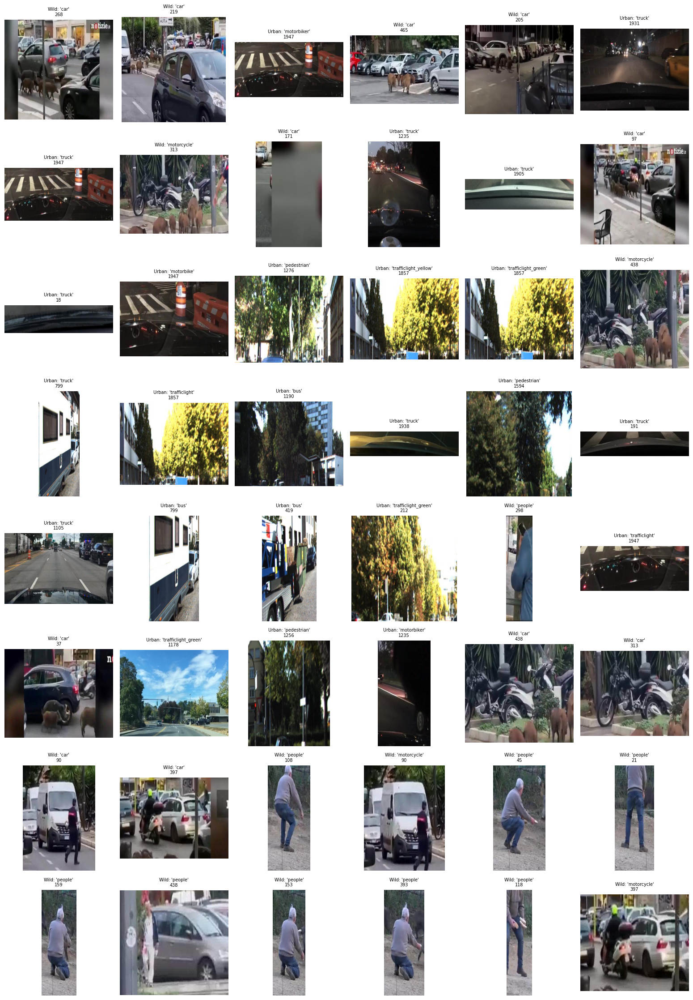

Review: is the named class actually visible (unannotated object) or a false region?


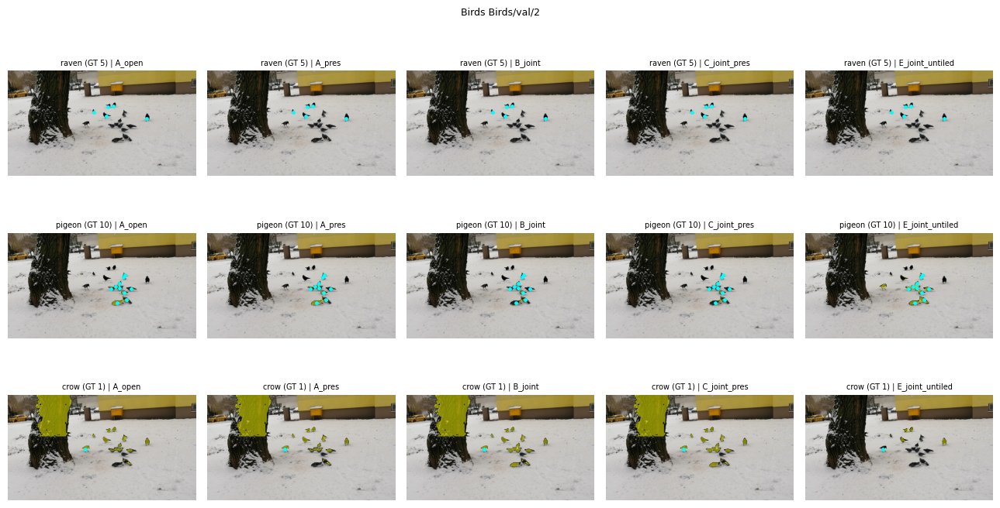

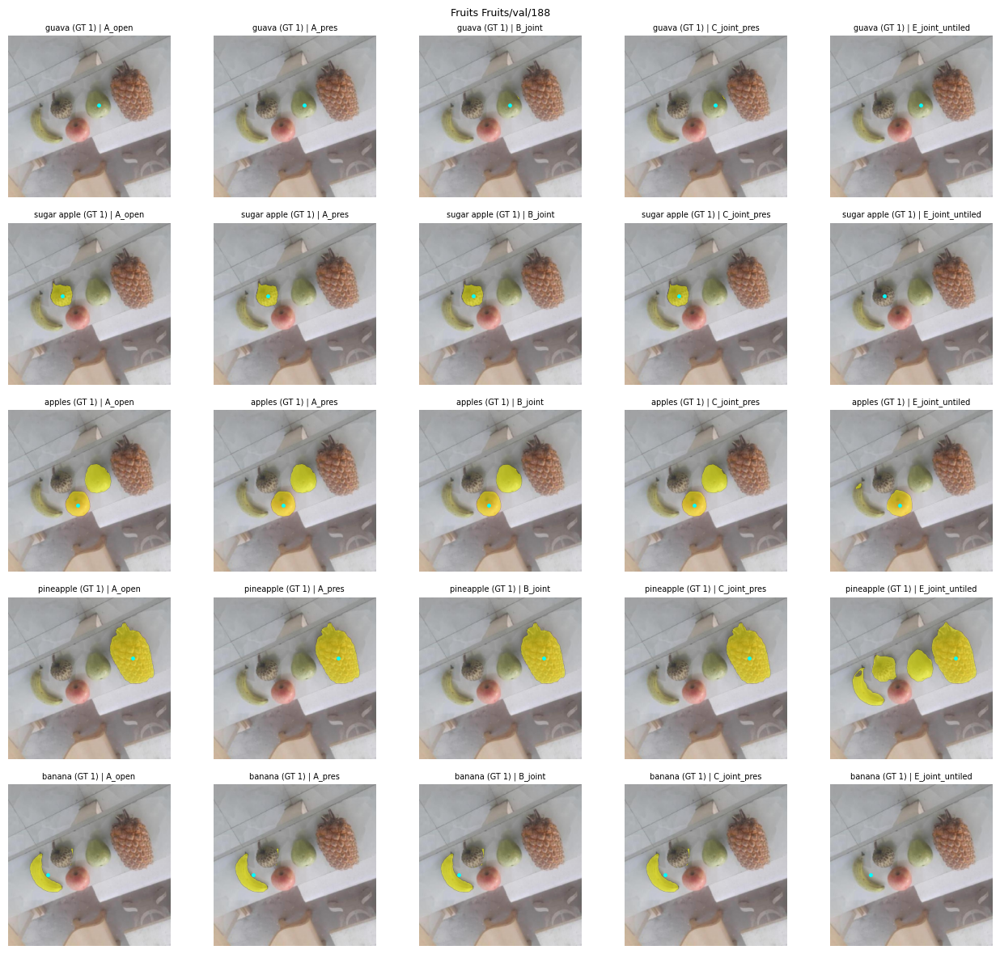

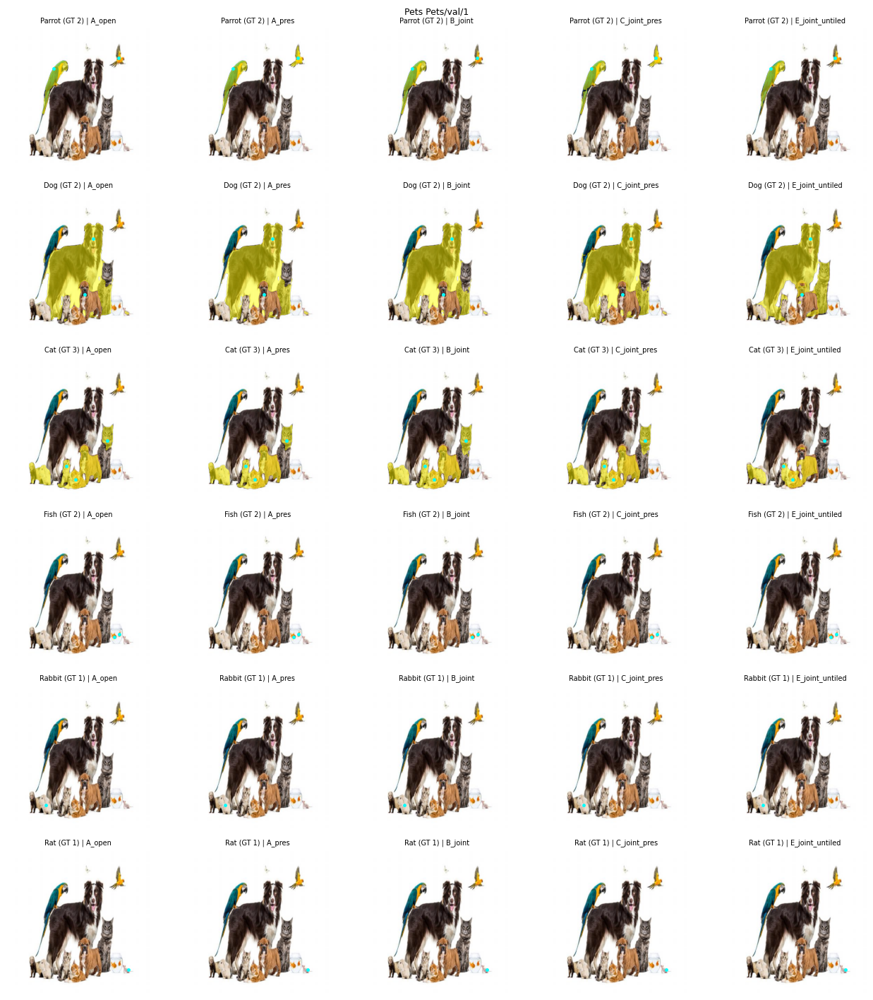

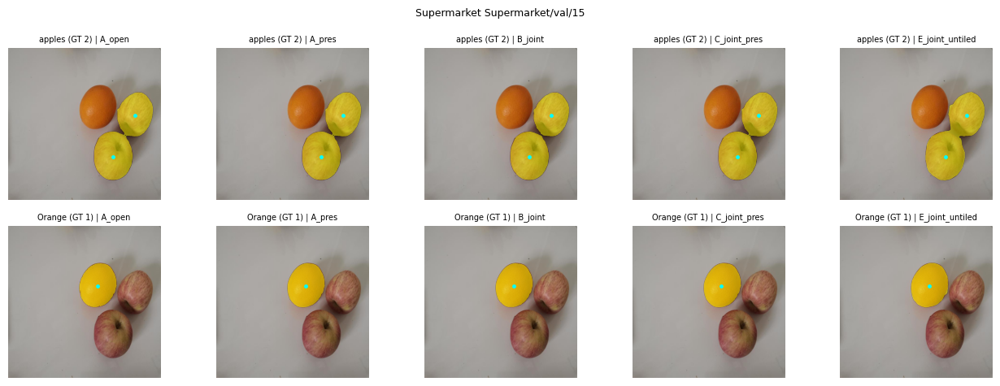

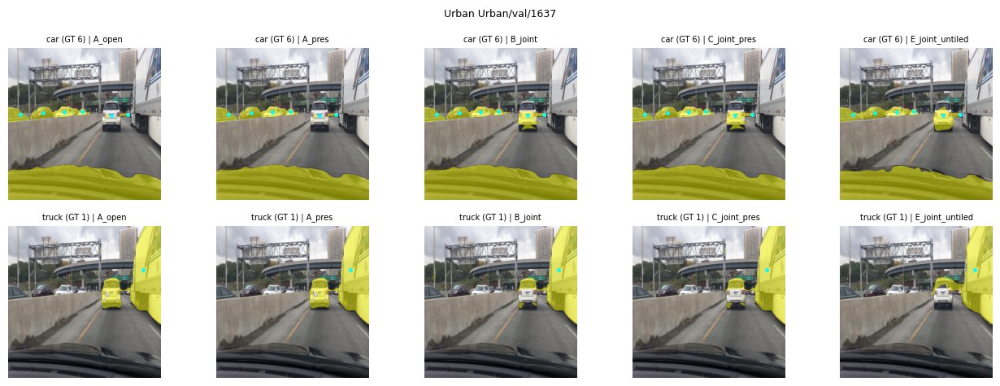

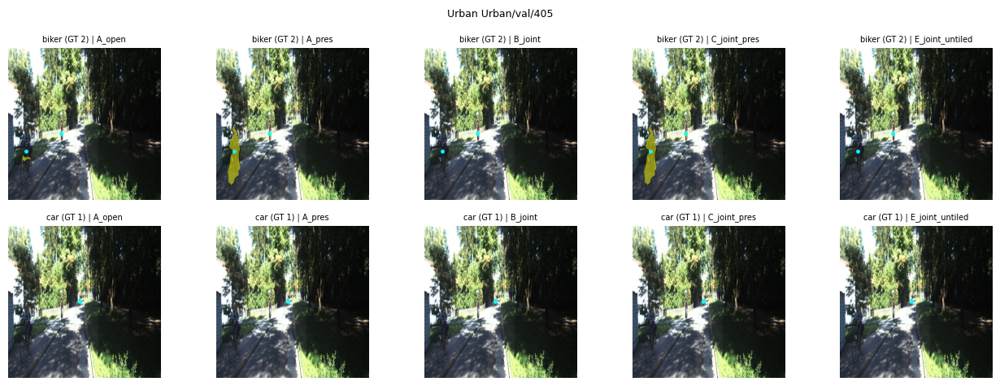

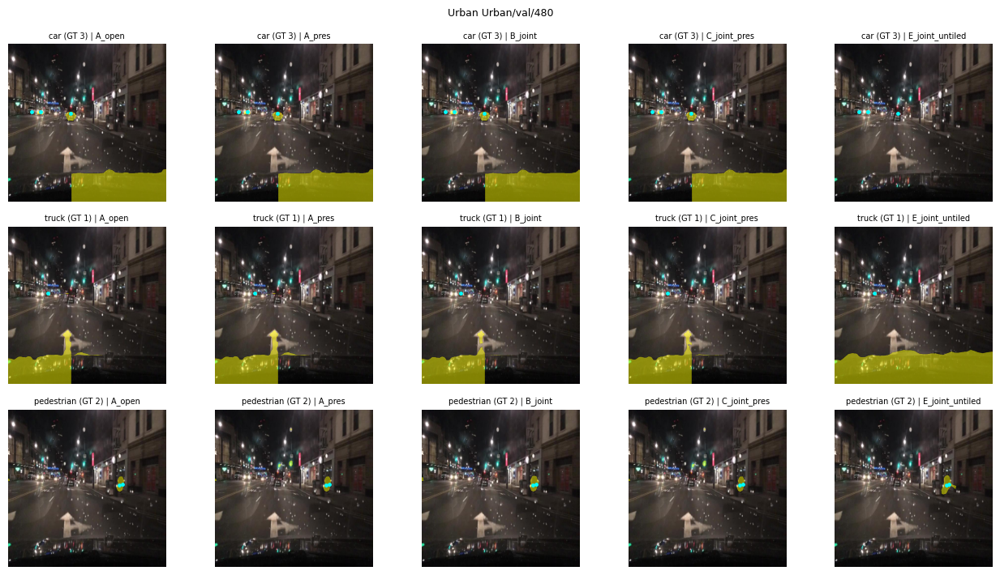

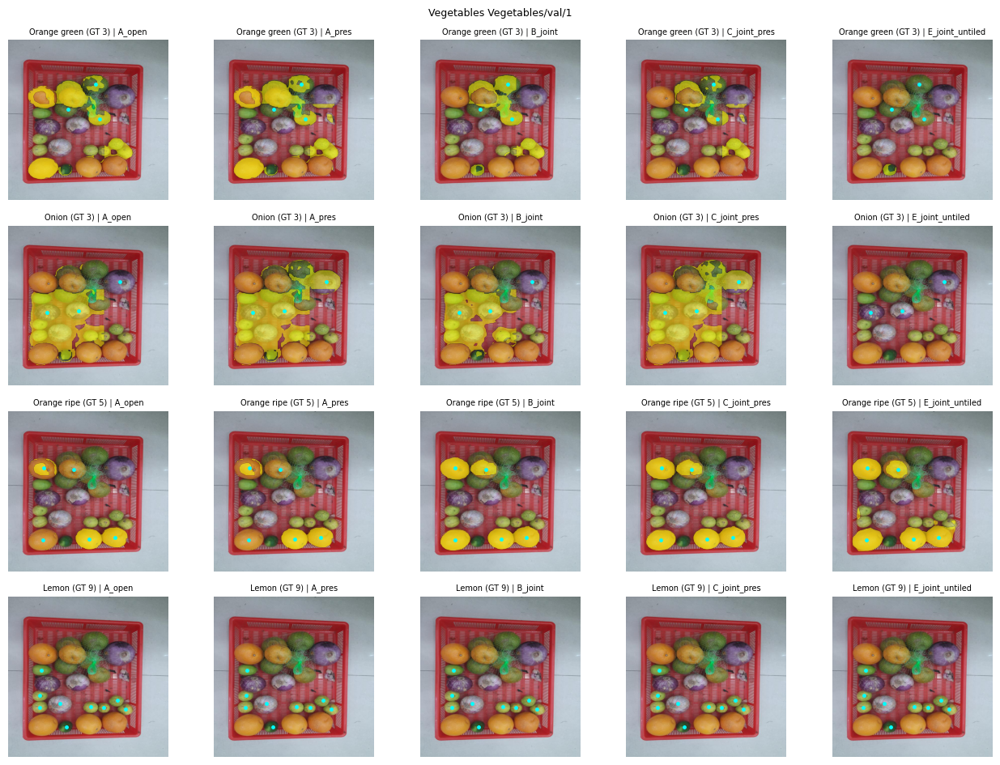

In [23]:
# ============================================================
# Step 2b.3 — Annotation audit gallery (Wild, Urban) + variant panels
# ============================================================
import matplotlib.pyplot as plt
aud = [{"image_id": rec["image_id"], "domain": rec["domain"], **a} for rec in recs2 for a in rec["audit"]]
aud = pd.DataFrame(aud)
print(f"Absent-class regions outside all GT boxes (> 0.2% of image), Wild/Urban: {len(aud)}")
if len(aud):
    display(aud.groupby(["domain", "class"]).size().sort_values(ascending=False).to_frame("regions").head(15))
    path_of = images.set_index("image_id")["image_path"].to_dict()
    show = aud.sort_values("area_frac", ascending=False).groupby("domain").head(24).reset_index(drop=True)
    ncol = 6; nrow = int(np.ceil(len(show) / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(2.6 * ncol, 2.8 * nrow))
    for ax, (_, r) in zip(np.ravel(axs), show.iterrows()):
        im = Image.open(path_of[r["image_id"]]).convert("RGB"); x1, y1, x2, y2 = r["bbox"]
        px, py = int(0.2 * (x2 - x1)) + 5, int(0.2 * (y2 - y1)) + 5
        ax.imshow(im.crop((max(0, x1 - px), max(0, y1 - py), min(im.width, x2 + px), min(im.height, y2 + py))))
        ax.set_title(f"{r['domain']}: '{r['class']}'\n{r['image_id'].split('/')[-1]}", fontsize=7)
    for ax in np.ravel(axs):
        ax.axis("off")
    plt.tight_layout(); plt.savefig(P2B_DIR / "panels" / "annotation_audit.png", dpi=90); plt.show()
    print("Review: is the named class actually visible (unannotated object) or a false region?")

def unpack(npz, key, H, W):
    return np.unpackbits(npz[key])[:H * W].reshape(H, W).astype(bool)
VSHOW = ["A_open", "A_pres", "B_joint", "C_joint_pres", "E_joint_untiled"]
for p in sorted((P2B_DIR / "maps").glob("*.npz")):
    npz = np.load(p); H, W = npz["shape"]; key = p.stem
    r = images[images["key"] == key].iloc[0]
    im = np.asarray(Image.open(r["image_path"]).convert("RGB")); present = list(r["gt"])
    cats = omni_ds[int(r["idx"])]["categories"]
    fig, axs = plt.subplots(len(present), len(VSHOW), figsize=(2.6 * len(VSHOW), 2.4 * len(present)), squeeze=False)
    for i, c in enumerate(present):
        pts = np.array(cats[c]["points"])
        for j, v in enumerate(VSHOW):
            ax = axs[i][j]; ax.imshow(im)
            k = f"{v}__{c}"
            if k in npz.files:
                ax.imshow(np.where(unpack(npz, k, H, W), 1.0, np.nan), alpha=0.5, cmap="autumn", vmin=0, vmax=1)
            if len(pts):
                ax.scatter(pts[:, 0] * W / r["width"], pts[:, 1] * H / r["height"], s=6, c="cyan")
            ax.set_title(f"{c} (GT {r['gt'][c]}) | {v}", fontsize=7); ax.axis("off")
    plt.suptitle(f"{r['domain']} {r['image_id']}", fontsize=9); plt.tight_layout()
    plt.savefig(P2B_DIR / "panels" / f"variants_{key}.png", dpi=80); plt.show()

In [24]:
# ============================================================
# Step 2b.4 — Save
# ============================================================
qb.to_csv(P2B_DIR / "B5_0_p2b_queries.csv", index=False)
var_df.to_csv(P2B_DIR / "B5_0_p2b_variants.csv", index=False)
dom_df.to_csv(P2B_DIR / "B5_0_p2b_variants_by_domain.csv", index=False)
pd.DataFrame(fg_rows).to_csv(P2B_DIR / "B5_0_p2b_fine_grained.csv", index=False)
pd.DataFrame(tr_rows).to_csv(P2B_DIR / "B5_0_p2b_presence_tradeoff.csv", index=False)
aud.to_csv(P2B_DIR / "B5_0_p2b_annotation_audit.csv", index=False)
with open(P2B_DIR / "B5_0_part2b_metadata.json", "w") as f:
    json.dump({"notebook": "B5_0_OmniCount_Region_Tests (Part 2b)", "repo_commit": REPO_COMMIT,
               "date_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
               "variants": OPEN + PRES, "images": len(images), "sam2_run": False,
               "test_split_used": False}, f, indent=2)
print("Saved to:", P2B_DIR)

Saved to: /content/drive/MyDrive/MSc_Project_ZeroShot_Counting/results/B5_0_OmniCount_Region_Tests/part2b_variants


# Part 3 — End-to-end on a small subset: primary system GPV_R4+P[MixA], per class

Settled region design (Part 2/2b): per-class single-pass SAN, tiled expanded vocabulary (v1 region), score-based overlap resolution.
Three configurations, same masks and counting rule (`candidates_v1`: Z-LM0 automatic + LM0 guided on the masked image, > 50%-outside discard, guided NMS 0.5, R4, P, count):

| Config | Classes queried | Region | Ladder |
|---|---|---|---|
| `open_raw` | whole domain vocabulary | R0 (per class, no resolution) | none (empty → 0) |
| `open_res` | whole domain vocabulary | R0 resolved among all prompted classes | none |
| `pres` | GT-present classes only | R0 resolved among present classes | L0 → L1 (S2 ∩ free space) → L2 (free space); fires when the mask set is empty |

Metrics: standard protocol (open configs) and OmniCount-code (all configs), overall / per domain / without Wild.
Development data only (sample subset of OmniCount val clean). Run order (GPU, L4 recommended): 0.1, 0.2b, 2.1, 2.2, 2.3 (PASS), then 3.0 → 3.5. Resumable; 3.4–3.5 can run later on CPU after 0.1, 0.2b, 2.1, 3.0.

In [25]:
# ============================================================
# Step 3.0 — Part 3 subset (first 10 images per domain from the Part 2 sample)
# ============================================================
P3_DIR = OUT_DIR / "part3_end_to_end"
for d in [P3_DIR, P3_DIR / "rows"]:
    d.mkdir(parents=True, exist_ok=True)
N_PER_DOMAIN = 10
sub = images[images["set"] == "sample"].groupby("domain").head(N_PER_DOMAIN).reset_index(drop=True)
q_open = sum(len(VOCAB[d]) for d in sub["domain"]); q_pres = int(sub["gt"].apply(len).sum())
print(f"Part 3 subset: {len(sub)} images | open queries {q_open} | present queries {q_pres}")
display(sub.groupby("domain").size().to_frame("images"))

Part 3 subset: 67 images | open queries 1211 | present queries 140


,images
domain,
Birds,5
Fruits,10
Pets,10
Satellite,10
Supermarket,10
Urban,10
Vegetables,2
Wild,10


In [26]:
# ============================================================
# Step 3.1 — SAM2.1-Large (frozen commit), as B4b
# ============================================================
import src.pipeline.b0 as b0
import src.pipeline.gpv as gpv
import src.pipeline.prompts as prompts
import src.pipeline.candidates as C
for m in (b0, gpv, prompts, C):
    importlib.reload(m)
%cd /content
if not Path("/content/sam2_repo/sam2/__init__.py").exists():
    !git clone -q https://github.com/facebookresearch/sam2.git /content/sam2_repo
    !git -C /content/sam2_repo checkout -q {b0.FROZEN_SAM2_COMMIT}
    %cd /content/sam2_repo
    !pip install -q -e .
    %cd /content
if "/content/sam2_repo" not in sys.path:
    sys.path.insert(0, "/content/sam2_repo")
importlib.invalidate_caches()
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor
from sam2.automatic_mask_generator import SAM2AutomaticMaskGenerator
SAM2_L = PROJECT_ROOT / "Checkpoints" / "SAM2" / "sam2.1_hiera_large.pt"
CFG_L = "configs/sam2.1/sam2.1_hiera_l.yaml"
assert SAM2_L.exists()
predictor_L = SAM2ImagePredictor(build_sam2(CFG_L, str(SAM2_L), device=DEVICE).eval())
model_LZ = build_sam2(CFG_L, str(SAM2_L), device=DEVICE, apply_postprocessing=False).eval()
amg_L_Z = SAM2AutomaticMaskGenerator(model_LZ, points_per_side=32, crop_n_layers=1)
print("SAM2.1-Large ready | GPU", torch.cuda.get_device_name(0))

def keep_inside(masks, region):
    if masks.shape[0] == 0:
        return np.zeros(0, bool)
    inside = (masks & region[None]).reshape(masks.shape[0], -1).sum(1)
    return inside > 0.5 * np.maximum(masks.reshape(masks.shape[0], -1).sum(1), 1)

def safe_amg(amg, image):
    try:
        return b0.run_amg(amg, image), False
    except IndexError:                                    # SAM2 empty-result case with crops
        h, w = image.shape[:2]
        return (np.zeros((0, h, w), bool), {"predicted_iou": np.zeros(0, np.float32)}), True

def san_capture_full(img, vocab):
    """san_capture + the side-adapter's low-resolution query mask logits (as run_san_d6)."""
    low = {}
    hook = san_model.side_adapter_network.register_forward_hook(
        lambda mod, inp, out: low.__setitem__("mp", out[0][-1].detach().float()))
    try:
        cls, sig = san_capture(img, vocab)
    finally:
        hook.remove()
    return cls, sig, low["mp"][0]                         # (Q, h, w)

def class_evidence(cls_u, sig_u, mp_low, U, p):
    """Two-class target score, A3c, D1 peaks and dense_recovery prompts for prompt p (single pass)."""
    m2 = subset_maps(cls_u, sig_u, [U.index(p), U.index("background")])
    target = m2[0].cpu().numpy(); s2 = (m2[0] > m2[1]).cpu().numpy()
    cols = torch.tensor([U.index(p), U.index("background"), cls_u.shape[-1] - 1], device=cls_u.device)
    tqp = F.softmax(cls_u[:, cols], dim=-1)[:, 0]
    a3c, _ = semantic.a3c_mask(target)
    pts, _ = prompts.dense_recovery_points(a3c, mp_low.cpu(), tqp.cpu())
    return target, s2, a3c, gpv.d1_peaks(target), np.asarray(pts, float).reshape(-1, 2)

/content
/content/sam2_repo
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for SAM-2 (pyproject.toml) ... done
/content
SAM2.1-Large ready | GPU NVIDIA L4


In [27]:
# ============================================================
# Step 3.2 — Equivalence: single-pass prompts vs per-class run_san_d6 / run_san (2 images x 2 classes)
# ============================================================
peq = []
for dom in ["Fruits", "Urban"]:
    r = sub[sub["domain"] == dom].iloc[0]
    img = Image.open(r["image_path"]).convert("RGB")
    U = union_vocabulary([datasets_mod.omnicount_prompt_name(c) for c in VOCAB[dom]])
    cls_u, sig_u, mp_low = san_capture_full(img, U)
    gt = r["gt"]
    for c in [list(gt)[0], next(c for c in VOCAB[dom] if c not in gt)]:
        p = datasets_mod.omnicount_prompt_name(c)
        _, _, a3c_new, _, pts_new = class_evidence(cls_u, sig_u, mp_low, U, p)
        t_ref, _ = semantic.run_san(san_model, img, p, DEVICE)
        a3c_ref, _ = semantic.a3c_mask(t_ref)
        mp_ref, tq_ref = semantic.run_san_d6(san_model, img, p, DEVICE)
        pts_ref, _ = prompts.dense_recovery_points(a3c_ref, mp_ref, tq_ref)
        pts_ref = np.asarray(pts_ref, float).reshape(-1, 2)
        same_n = len(pts_ref) == len(pts_new)
        peq.append({"domain": dom, "class": c, "a3c agree": float((a3c_new == a3c_ref).mean()),
                    "points ref": len(pts_ref), "points new": len(pts_new),
                    "max |dxy|": float(np.abs(np.sort(pts_ref, 0) - np.sort(pts_new, 0)).max()) if same_n and len(pts_ref) else 0.0})
peq = pd.DataFrame(peq); display(peq)
PROMPT_EQUIV = bool(((peq["points ref"] == peq["points new"]) & (peq["max |dxy|"] < 0.5)).all()
                    and (peq["a3c agree"] > 0.9999).all())
print("PROMPT EQUIVALENCE:", "PASS" if PROMPT_EQUIV else "FAIL — send this table")

,domain,class,a3c agree,points ref,points new,max |dxy|
0,Fruits,guava,1.0,11,11,6.693699e-08
1,Fruits,dragon fruit,1.0,6,6,0.000000e+00
2,Urban,biker,1.0,8,8,9.866699e-07
3,Urban,bike,1.0,9,9,4.538272e-07


PROMPT EQUIVALENCE: PASS


In [28]:
# ============================================================
# Step 3.3 — End-to-end counts per image, three configurations (resumable)
# ============================================================
assert EQUIV_PASS and PROMPT_EQUIV
ROWS3 = P3_DIR / "rows"

def masks_for_region(img_np, region, pts):
    """Z-LM0 automatic + LM0 guided on the masked image; > 50%-outside discard (as B4b)."""
    masked = (img_np * region[..., None]).astype(np.uint8)
    (bm, bmeta), empty = safe_amg(amg_L_Z, masked)
    kb = keep_inside(bm, region)
    h, w = region.shape
    gm, gs = [], []
    if len(pts):
        with torch.inference_mode():
            predictor_L.set_image(masked)
            for p in pts:
                m, sc, _ = predictor_L.predict(point_coords=np.asarray([p], np.float32),
                                               point_labels=np.asarray([1], np.int32), multimask_output=False)
                gm.append(np.asarray(m[0], bool)); gs.append(float(np.asarray(sc)[0]))
    gm = np.asarray(gm) if gm else np.zeros((0, h, w), bool); gs = np.asarray(gs, float)
    kg = keep_inside(gm, region)
    return {"b0": bm[kb], "b0_iou": np.asarray(bmeta["predicted_iou"])[kb], "g": gm[kg], "gs": gs[kg],
            "n_auto_raw": int(bm.shape[0]), "n_guided_raw": int(gm.shape[0]), "amg_empty": bool(empty)}

def count_primary(mk, amax, d1):
    """GPV_R4+P[MixA] count (candidates_v1 logic) from cached masks."""
    g, gs = mk["g"], mk["gs"]
    kg = gpv.nms_masks(g, gs, C.NMS_IOU) if g.shape[0] else np.zeros(0, int)
    m, s, _ = gpv.build_r4(g[kg], gs[kg], mk["b0"], mk["b0_iou"], C.NMS_IOU)
    if m.shape[0] == 0:
        return 0, {"n_r4": 0, "bottom_wide": 0}
    mp, sp, nd, _ = C.part_filter(m, np.asarray(s, float), amax, d1)
    H_, W_ = amax.shape
    band = mp[:, int(0.95 * H_):, :].any(1)                          # masks touching the bottom 5%
    bottom_wide = int((band.sum(1) > 0.4 * W_).sum())                 # ... and spanning > 40% of the width
    return int(mp.shape[0]), {"n_r4": int(m.shape[0]), "parts_dropped": int(nd), "bottom_wide": bottom_wide}

def resolve_np(R, T, members):
    out = dict(R)
    if len(members) >= 2:
        stack = np.stack([np.where(R[c], T[c], -1.0) for c in members])
        win = stack.argmax(0)
        for i, c in enumerate(members):
            out[c] = R[c] & (win == i)
    return out

todo = [r for r in sub.itertuples(index=False) if not (ROWS3 / f"{r.key}.json").exists()]
print(f"Done: {len(sub) - len(todo)} | to process: {len(todo)}")
t_start = time.time()
for r in tqdm(todo, desc="End-to-end"):
    t0 = time.time()
    pil = Image.open(r.image_path).convert("RGB"); img_np = b0.load_image_rgb_cv2(r.image_path)
    assert img_np.shape[:2] == (pil.size[1], pil.size[0])
    classes = VOCAB[r.domain]; present = [c for c in classes if c in r.gt]
    prompt = {c: datasets_mod.omnicount_prompt_name(c) for c in classes}
    U = union_vocabulary(prompt.values())
    caps, shape = tiled_capture(pil, U); cls_u, sig_u, mp_low = san_capture_full(pil, U)
    R0, T0, AM, S2, D1, PTS = {}, {}, {}, {}, {}, {}
    for c in classes:
        Tm = tiled_subset(caps, shape, [U.index(x) for x in semantic.expanded_vocabulary(prompt[c])])
        am = Tm.argmax(0)
        R0[c] = (am == 0).cpu().numpy(); T0[c] = Tm[0].cpu().numpy(); AM[c] = am.cpu().numpy().astype(np.int32)
        _, S2[c], _, D1[c], PTS[c] = class_evidence(cls_u, sig_u, mp_low, U, prompt[c])
        del Tm, am
    del caps, cls_u, sig_u, mp_low; torch.cuda.empty_cache()
    t_san = time.time() - t0
    ne = [c for c in classes if R0[c].any()]
    res_open = resolve_np(R0, T0, ne)
    res_pres = resolve_np(R0, T0, [c for c in ne if c in present])

    cache, t_sam = {}, 0.0
    def run(c, region, amax):
        global t_sam
        if not region.any():
            return 0, {"n_r4": 0, "skipped": True}
        key = (c, hash(np.packbits(region).tobytes()))
        if key not in cache:
            ts = time.time(); cache[key] = masks_for_region(img_np, region, PTS[c]); t_sam += time.time() - ts
        n, info = count_primary(cache[key], amax, D1[c])
        return n, {**info, "n_auto_raw": cache[key]["n_auto_raw"], "amg_empty": cache[key]["amg_empty"]}

    def resolved_amax(c, Rres):
        a = AM[c].copy(); a[R0[c] & ~Rres] = 1; return a

    rows = []
    for c in classes:
        row = {"image_id": r.image_id, "domain": r.domain, "class": c, "present": c in present,
               "gt_count": int(r.gt.get(c, 0)), "r0_frac": float(R0[c].mean())}
        n, info = run(c, R0[c], AM[c]); row.update({"open_raw": n, "open_raw_n_r4": info["n_r4"],
                                                    "open_raw_bottom_wide": info.get("bottom_wide", 0)})
        Rr = res_open[c]
        n, info = run(c, Rr, resolved_amax(c, Rr)); row.update({"open_res": n, "open_res_n_r4": info["n_r4"],
                                                                "open_res_bottom_wide": info.get("bottom_wide", 0)})
        if c in present:
            others = [res_pres[k] for k in present if k != c and k in ne]
            free = ~np.any(others, axis=0) if others else np.ones_like(R0[c])
            ladder = [(0, res_pres[c], resolved_amax(c, res_pres[c])),
                      (1, S2[c] & free, (~(S2[c] & free)).astype(np.int32)),
                      (2, free, (~free).astype(np.int32))]
            for lvl, reg, am in ladder:
                n, info = run(c, reg, am)
                if info["n_r4"] > 0 or lvl == 2:
                    break
            row.update({"pres": n, "pres_level": lvl, "pres_n_r4": info["n_r4"],
                        "pres_bottom_wide": info.get("bottom_wide", 0)})
        rows.append(row)
    with open(ROWS3 / f"{r.key}.json", "w") as f:
        json.dump({"image_id": r.image_id, "domain": r.domain, "idx": int(r.idx), "H": int(img_np.shape[0]),
                   "W": int(img_np.shape[1]), "t_san_s": t_san, "t_sam2_s": t_sam, "sam2_runs": len(cache),
                   "t_total_s": time.time() - t0, "rows": rows}, f)
    del cache, R0, T0, AM, S2
print(f"Elapsed: {(time.time() - t_start) / 60:.1f} min")

Done: 67 | to process: 0


End-to-end: 0it [00:00, ?it/s]

Elapsed: 0.0 min


In [29]:
# ============================================================
# Step 3.4 — Evaluation: both metrics, per domain, with / without Wild; diagnostics
# ============================================================
import src.evaluation as ev
importlib.reload(ev)
LOCAL = Path("/content/B5_0_rows3_local")
if LOCAL.exists():
    shutil.rmtree(LOCAL)
shutil.copytree(P3_DIR / "rows", LOCAL)
recs3 = [json.load(open(p)) for p in sorted(LOCAL.glob("*.json"))]
assert len(recs3) == len(sub), (len(recs3), len(sub))
e = pd.DataFrame([row for rec in recs3 for row in rec["rows"]])
cats_of = {rec["image_id"]: omni_ds[rec["idx"]]["categories"] for rec in recs3}

def results_for(cfg, domains=None):
    out = []
    for rec in recs3:
        if domains is not None and rec["domain"] not in domains:
            continue
        rows = [x for x in rec["rows"] if cfg in x]
        out.append({"image_id": rec["image_id"], "domain": rec["domain"], "categories": cats_of[rec["image_id"]],
                    "pred_counts": {x["class"]: x[cfg] for x in rows}, "query_classes": VOCAB[rec["domain"]]})
    return out

ALL_D = sorted(sub["domain"].unique()); NO_WILD = [d for d in ALL_D if d != "Wild"]
summ = []
for cfg in ["open_raw", "open_res", "pres"]:
    for label, doms in [("all domains", ALL_D), ("without Wild", NO_WILD)]:
        res = results_for(cfg, doms)
        _, _, m = ev.evaluate_multi_label_counts(ev.build_multi_label_pairs(res))
        _, om = ev.omnicount_reference_by_domain(res)
        row = {"config": cfg, "set": label, "MAE_nz": m["MAE_nz"], "RMSE_nz": m["RMSE_nz"], "NAE_nz": m["NAE_nz"],
               "OmniCount m_rmse": om["pooled_m_rmse"], "OmniCount m_rmse_nz": om["pooled_m_rmse_nz"]}
        if cfg != "pres":                                   # standard protocol needs absent-class predictions
            row.update({"std mRMSE": m["mRMSE"], "std mRMSE_nz": m["mRMSE_nz"], "FP units (absent)": m["false_positive_units"]})
        summ.append(row)
summ = pd.DataFrame(summ)
print("Part 3 — primary system, three configurations (pres: standard mRMSE not applicable, absent classes not queried)")
display(summ.round(3))

dom_rows = []
for d in ALL_D:
    for cfg in ["open_raw", "open_res", "pres"]:
        _, _, m = ev.evaluate_multi_label_counts(ev.build_multi_label_pairs(results_for(cfg, [d])))
        dom_rows.append({"domain": d, "config": cfg, "MAE_nz": m["MAE_nz"],
                         "std mRMSE": m["mRMSE"] if cfg != "pres" else np.nan,
                         "FP units": m["false_positive_units"] if cfg != "pres" else np.nan})
dom3 = pd.DataFrame(dom_rows).pivot(index="domain", columns="config")
print("\nPer domain:"); display(dom3.round(2))

P_ = e[e["present"]]
print("\nPresent classes — signed error (pred − GT) by config:")
display(pd.DataFrame({cfg: (P_[cfg] - P_["gt_count"]).describe() for cfg in ["open_raw", "open_res", "pres"]}).round(2))
print("Presence-asserted ladder level used:", P_["pres_level"].astype(int).value_counts().sort_index().to_dict())
A_ = e[~e["present"]]
print("Absent classes with count > 0:", {cfg: int((A_[cfg] > 0).sum()) for cfg in ["open_raw", "open_res"]},
      "of", len(A_))
bw = e.groupby("domain")[["open_raw_bottom_wide", "open_res_bottom_wide"]].sum()
print("\nMasks touching the bottom 5% and spanning > 40% width (ego-vehicle candidates), counted:"); display(bw)

tt = pd.DataFrame([{k: rec[k] for k in ["domain", "t_san_s", "t_sam2_s", "sam2_runs", "t_total_s"]} for rec in recs3])
tt["s_per_sam2_run"] = tt["t_sam2_s"] / tt["sam2_runs"].clip(lower=1)
print("\nTiming by domain (s):"); display(tt.groupby("domain").mean().round(2))
inv = pd.read_csv(P1_DIR / "B5_0_query_inventory_val_clean.csv").set_index("domain")
per_img = tt.groupby("domain")["t_total_s"].mean()
print(f"Estimated full val clean time (all three configs as here): {(inv['images'] * per_img.reindex(inv.index)).sum() / 3600:.1f} h")

Part 3 — primary system, three configurations (pres: standard mRMSE not applicable, absent classes not queried)


,config,set,MAE_nz,RMSE_nz,NAE_nz,OmniCount m_rmse,OmniCount m_rmse_nz,std mRMSE,std mRMSE_nz,FP units (absent)
0,open_raw,all domains,6.236,10.247,2.515,0.953,4.809,5.055,6.884,2170.0
1,open_raw,without Wild,6.585,10.616,2.666,1.198,5.614,5.085,6.985,2080.0
2,open_res,all domains,3.821,8.465,1.195,0.631,3.326,1.649,4.745,439.0
3,open_res,without Wild,3.962,8.759,1.241,0.787,3.868,1.612,4.796,386.0
4,pres,all domains,5.671,14.004,2.370,0.946,4.902,NaN,NaN,NaN
5,pres,without Wild,6.008,14.524,2.517,1.193,5.730,NaN,NaN,NaN



Per domain:


MAE_nz                 std mRMSE               FP units  \
config      open_raw open_res   pres  open_raw open_res pres open_raw   
domain                                                                  
Birds          10.93     6.40   8.60     11.08     7.36  NaN      0.0   
Fruits          2.72     0.89   1.00      3.57     1.17  NaN    142.0   
Pets            5.54     2.41   3.00      3.83     0.76  NaN    331.0   
Satellite       6.20     6.30  18.50      3.40     2.06  NaN    295.0   
Supermarket    13.45    13.55  22.00      3.31     1.15  NaN    668.0   
Urban           2.85     2.23   2.46      4.74     1.52  NaN    359.0   
Vegetables     17.75     7.12   5.75     16.77     2.89  NaN    285.0   
Wild            1.70     2.00   1.30      4.08     2.84  NaN     90.0   

                           
config      open_res pres  
domain                     
Birds            0.0  NaN  
Fruits          22.0  NaN  
Pets             4.0  NaN  
Satellite      160.0  NaN  
Supermarket    103.0  NaN  
Urban           85.0  NaN  
Vegetables      12.0  NaN  
Wild            53.0  NaN


Present classes — signed error (pred − GT) by config:


,open_raw,open_res,pres
count,140.00,140.00,140.00
mean,3.96,-0.06,5.17
std,9.48,8.49,13.06
min,-56.00,-56.00,-8.00
25%,0.75,-1.00,0.00
50%,3.00,0.00,2.00
75%,7.00,2.00,5.00
max,49.00,50.00,101.00


Presence-asserted ladder level used: {0: 102, 1: 24, 2: 14}
Absent classes with count > 0: {'open_raw': 382, 'open_res': 101} of 1071

Masks touching the bottom 5% and spanning > 40% width (ego-vehicle candidates), counted:


,open_raw_bottom_wide,open_res_bottom_wide
domain,,
Birds,0,0
Fruits,0,0
Pets,0,0
Satellite,3,2
Supermarket,0,0
Urban,10,7
Vegetables,0,0
Wild,0,0



Timing by domain (s):


,t_san_s,t_sam2_s,sam2_runs,t_total_s,s_per_sam2_run
domain,,,,,
Birds,1.33,117.09,6.0,119.96,19.52
Fruits,2.37,207.22,13.4,209.79,15.47
Pets,1.53,189.78,12.9,191.48,14.73
Satellite,1.05,75.82,5.2,76.93,14.50
Supermarket,2.63,290.34,18.9,293.46,15.26
Urban,1.23,218.47,14.5,219.94,15.06
Vegetables,0.93,327.20,20.5,329.10,15.95
Wild,0.73,62.17,4.1,63.01,15.30


Estimated full val clean time (all three configs as here): 191.4 h


In [30]:
# ============================================================
# Step 3.5 — Save
# ============================================================
e.to_csv(P3_DIR / "B5_0_p3_counts.csv", index=False)
summ.to_csv(P3_DIR / "B5_0_p3_summary.csv", index=False)
dom3.to_csv(P3_DIR / "B5_0_p3_by_domain.csv")
tt.to_csv(P3_DIR / "B5_0_p3_timing.csv", index=False)
with open(P3_DIR / "B5_0_part3_metadata.json", "w") as f:
    json.dump({"notebook": "B5_0_OmniCount_Region_Tests (Part 3)", "repo_commit": REPO_COMMIT,
               "date_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
               "system": "GPV_R4+P[MixA] (candidates_v1 logic), per class", "images": len(sub),
               "configs": ["open_raw", "open_res", "pres"], "prompt_equivalence": bool(globals().get("PROMPT_EQUIV", False)),
               "test_split_used": False}, f, indent=2)
print("Saved to:", P3_DIR)

Saved to: /content/drive/MyDrive/MSc_Project_ZeroShot_Counting/results/B5_0_OmniCount_Region_Tests/part3_end_to_end


In [31]:
# ============================================================
# Step 3.6 — Diagnostic: ladder vs resolution scope; worst classes (CPU, from saved counts)
# ============================================================
e = pd.read_csv(P3_DIR / "B5_0_p3_counts.csv")
P_ = e[e["present"]].copy()
P_["pres_L0only"] = np.where(P_["pres_level"] == 0, P_["pres"], 0)     # presence-asserted, ladder off
for c in ["open_raw", "open_res", "pres", "pres_L0only"]:
    P_[f"ae_{c}"] = (P_[c] - P_["gt_count"]).abs()
print("MAE on present classes:", {c: round(P_[f"ae_{c}"].mean(), 2) for c in ["open_raw", "open_res", "pres", "pres_L0only"]})
print("\nBy ladder level (pres):")
display(P_.groupby("pres_level").agg(n=("gt_count", "size"), gt_mean=("gt_count", "mean"), pred_mean=("pres", "mean"),
                                     mae=("ae_pres", "mean"), mae_open_res_same_rows=("ae_open_res", "mean")).round(2))
print("\nBy domain:")
display(P_.groupby("domain")[["ae_open_res", "ae_pres_L0only", "ae_pres"]].mean().round(2))
print("\nWorst present-class errors under open_res:")
display(P_.assign(err=P_["open_res"] - P_["gt_count"]).sort_values("ae_open_res", ascending=False)
        [["domain", "image_id", "class", "gt_count", "open_res", "pres", "pres_level", "err"]].head(15))

MAE on present classes: {'open_raw': np.float64(6.24), 'open_res': np.float64(3.82), 'pres': np.float64(5.67), 'pres_L0only': np.float64(3.76)}

By ladder level (pres):


,n,gt_mean,pred_mean,mae,mae_open_res_same_rows
pres_level,,,,,
0.0,102,3.09,5.61,3.13,3.21
1.0,24,2.46,10.62,8.50,2.46
2.0,14,10.64,30.00,19.36,10.64



By domain:


,ae_open_res,ae_pres_L0only,ae_pres
domain,,,
Birds,6.40,6.40,8.60
Fruits,0.89,0.89,1.00
Pets,2.41,2.32,3.00
Satellite,6.30,6.20,18.50
Supermarket,13.55,13.27,22.00
Urban,2.23,2.31,2.46
Vegetables,7.12,7.25,5.75
Wild,2.00,1.70,1.30



Worst present-class errors under open_res:


,domain,image_id,class,gt_count,open_res,pres,pres_level,err
625,Supermarket,Supermarket/val/194,Coffee,56,0,106.0,2.0,-56
495,Satellite,Satellite/val/83,building,8,58,57.0,0.0,50
812,Supermarket,Supermarket/val/316,eggs,31,0,52.0,2.0,-31
833,Supermarket,Supermarket/val/338,Coffee,24,0,125.0,2.0,-24
573,Supermarket,Supermarket/val/192,Coffee,24,0,83.0,2.0,-24
9,Birds,Birds/val/3,crow,2,20,20.0,0.0,18
3,Birds,Birds/val/1,crow,2,19,19.0,0.0,17
1149,Vegetables,Vegetables/val/0,Orange green,5,21,21.0,0.0,16
6,Birds,Birds/val/2,crow,1,14,14.0,0.0,13
1161,Vegetables,Vegetables/val/1,Onion,3,13,12.0,0.0,10


## Part 3b — Ladder fix test (guided-only fallback)
Run in the Part 3 session after Step 3.1 (needs SAN, SAM2 and the Part 3 functions).

In [32]:
# ============================================================
# Step 3b — Ladder fix test: guided-only fallback (V0–V3) on fallback cases
#           OmniCount (pres_level >= 1 in Part 3) + FSC train-pool empty cases (B4c D.3)
# ============================================================
assert EQUIV_PASS and PROMPT_EQUIV
FSC147_IMAGE_DIR = PROJECT_ROOT / "datasets" / "FSC147" / "raw" / "images_384_VarV2"
TD_ROOT = PROJECT_ROOT / "cache" / "FSC147_train_dev400"

def guided_only(img_np, region, pts):
    h, w = region.shape; gm, gs = [], []
    if len(pts) and region.any():
        masked = (img_np * region[..., None]).astype(np.uint8)
        with torch.inference_mode():
            predictor_L.set_image(masked)
            for p in pts:
                m, sc, _ = predictor_L.predict(point_coords=np.asarray([p], np.float32),
                                               point_labels=np.asarray([1], np.int32), multimask_output=False)
                gm.append(np.asarray(m[0], bool)); gs.append(float(np.asarray(sc)[0]))
    gm = np.asarray(gm) if gm else np.zeros((0, h, w), bool); gs = np.asarray(gs, float)
    k = keep_inside(gm, region)
    return gm[k], gs[k]

def count_guided(gm, gs, amax, d1):
    if gm.shape[0] == 0:
        return 0
    kg = gpv.nms_masks(gm, gs, C.NMS_IOU)
    m, s = gm[kg], gs[kg]
    if m.shape[0] < 2:
        return int(m.shape[0])
    mp, _, _, _ = C.part_filter(m, s, amax, d1)
    return int(mp.shape[0])

def ladder_variants(img_np, levels, pts, d1):
    """levels: [(name, region)] for L1, L2. Returns V0..V3 counts and the level used per variant."""
    out = {"V3": 0}
    v0 = None
    for name, reg in levels:                                   # V0: current (R4 on guided + automatic)
        if not reg.any():
            continue
        n, info = count_primary(masks_for_region(img_np, reg, pts), (~reg).astype(np.int32), d1)
        if info["n_r4"] > 0:
            v0 = (n, name); break
    out["V0"], out["V0_level"] = v0 if v0 else (0, "none")
    g = {}
    for name, reg in levels:
        gm, gs = guided_only(img_np, reg, pts)
        g[name] = count_guided(gm, gs, (~reg).astype(np.int32), d1)
    out["V1"] = g["L1"] if g["L1"] > 0 else g["L2"]; out["V1_level"] = "L1" if g["L1"] > 0 else ("L2" if g["L2"] > 0 else "none")
    out["V2"] = g["L1"]
    out["n_prompts"] = int(len(pts))
    return out

cases = []
# ---- OmniCount: present classes that needed L1/L2 in Part 3
e3 = pd.read_csv(P3_DIR / "B5_0_p3_counts.csv")
fb = e3[e3["present"] & (e3["pres_level"] >= 1)]
for image_id, g in tqdm(list(fb.groupby("image_id")), desc="OmniCount fallback images"):
    r = sub[sub["image_id"] == image_id].iloc[0]
    pil = Image.open(r["image_path"]).convert("RGB"); img_np = b0.load_image_rgb_cv2(r["image_path"])
    classes = VOCAB[r["domain"]]; present = [c for c in classes if c in r["gt"]]
    prompt = {c: datasets_mod.omnicount_prompt_name(c) for c in classes}
    U = union_vocabulary(prompt.values())
    caps, shape = tiled_capture(pil, U); cls_u, sig_u, mp_low = san_capture_full(pil, U)
    R0, T0, S2, D1, PTS = {}, {}, {}, {}, {}
    for c in present:
        Tm = tiled_subset(caps, shape, [U.index(x) for x in semantic.expanded_vocabulary(prompt[c])])
        R0[c] = (Tm.argmax(0) == 0).cpu().numpy(); T0[c] = Tm[0].cpu().numpy()
        _, S2[c], _, D1[c], PTS[c] = class_evidence(cls_u, sig_u, mp_low, U, prompt[c]); del Tm
    del caps, cls_u, sig_u, mp_low; torch.cuda.empty_cache()
    res = resolve_np(R0, T0, [c for c in present if R0[c].any()])
    for c in g["class"]:
        others = [res[k] for k in present if k != c and R0[k].any()]
        free = ~np.any(others, axis=0) if others else np.ones_like(R0[c])
        v = ladder_variants(img_np, [("L1", S2[c] & free), ("L2", free)], PTS[c], D1[c])
        cases.append({"dataset": "OmniCount", "domain": r["domain"], "image_id": image_id, "class": c,
                      "gt": int(r["gt"][c]), "part3_pres": float(g.loc[g["class"] == c, "pres"].iloc[0]), **v})

# ---- FSC-147 train pool: images whose MixA candidate mask set was empty (B4c D.3: 5 images)
td = pd.read_csv(TD_ROOT / "FSC147_train_dev400.csv")
pn = pd.read_csv(RESULTS_ROOT / "B3PN_Part_and_Normals_Merge" / "B3PN_per_image.csv")
assert "gt_count" in pn.columns, pn.columns.tolist()
trw = pd.DataFrame([json.load(open(p)) for p in sorted((RESULTS_ROOT / "B4c_HeldOut_Candidates" / "A_train_rows").glob("*.json"))])
emp_fsc = trw[trw["n_r4[MixA]"] == 0][["dataset_index"]].merge(td[["dataset_index", "image_id", "category"]], on="dataset_index") \
                                                    .merge(pn[["dataset_index", "gt_count"]], on="dataset_index")
for r in tqdm(list(emp_fsc.itertuples(index=False)), desc="FSC train empties"):
    pil = Image.open(FSC147_IMAGE_DIR / r.image_id).convert("RGB"); img_np = b0.load_image_rgb_cv2(FSC147_IMAGE_DIR / r.image_id)
    U = union_vocabulary([r.category])
    cls_u, sig_u, mp_low = san_capture_full(pil, U)
    _, s2, _, d1, pts = class_evidence(cls_u, sig_u, mp_low, U, r.category)
    del cls_u, sig_u, mp_low; torch.cuda.empty_cache()
    v = ladder_variants(img_np, [("L1", s2), ("L2", np.ones_like(s2))], pts, d1)
    cases.append({"dataset": "FSC-147 train", "domain": r.category, "image_id": r.image_id, "class": r.category,
                  "gt": int(r.gt_count), "part3_pres": np.nan, **v})

lad = pd.DataFrame(cases)
for v in ["V0", "V1", "V2", "V3"]:
    lad[f"ae_{v}"] = (lad[v] - lad["gt"]).abs()
print("Mean absolute error on fallback cases (lower is better):")
display(lad.groupby("dataset")[[f"ae_{v}" for v in ["V0", "V1", "V2", "V3"]]].mean().round(2))
print("\nOmniCount by domain:")
display(lad[lad["dataset"] == "OmniCount"].groupby("domain")[[f"ae_{v}" for v in ["V0", "V1", "V2", "V3"]]].agg(["mean", "size"]).round(2))
print("\nAll cases:")
display(lad[["dataset", "domain", "class", "gt", "part3_pres", "V0", "V0_level", "V1", "V1_level", "V2", "n_prompts"]])
P_ = e3[e3["present"]].copy()
for v in ["V0", "V1", "V2", "V3"]:
    m = dict(zip(zip(lad["image_id"], lad["class"]), lad[v]))
    P_[f"pres_{v}"] = [m.get((i, c), p if lvl == 0 else 0) for i, c, p, lvl in zip(P_["image_id"], P_["class"], P_["pres"], P_["pres_level"])]
print("\nImplied presence-asserted MAE on all 140 present classes:",
      {v: round((P_[f"pres_{v}"] - P_["gt_count"]).abs().mean(), 2) for v in ["V0", "V1", "V2", "V3"]}, "| open_res:",
      round((P_["open_res"] - P_["gt_count"]).abs().mean(), 2))
lad.to_csv(P3_DIR / "B5_0_p3b_ladder_variants.csv", index=False)

OmniCount fallback images:   0%|          | 0/30 [00:00<?, ?it/s]

FSC train empties:   0%|          | 0/5 [00:00<?, ?it/s]

Mean absolute error on fallback cases (lower is better):


,ae_V0,ae_V1,ae_V2,ae_V3
dataset,,,,
FSC-147 train,77.2,215.00,219.20,277.40
OmniCount,12.5,5.26,6.95,5.47



OmniCount by domain:


ae_V0       ae_V1       ae_V2       ae_V3     
              mean size   mean size   mean size   mean size
domain                                                     
Birds        10.20    5   5.40    5   5.40    5   3.60    5
Fruits        1.80    5   0.20    5   0.40    5   1.00    5
Pets          3.36   14   1.50   14   1.57   14   1.57   14
Satellite    21.50    6   9.33    6   9.33    6   1.00    6
Supermarket  57.75    4  18.25    4  33.75    4  33.75    4
Urban         3.00    1   2.00    1   2.00    1   1.00    1
Vegetables    2.50    2   8.50    2   8.50    2   8.50    2
Wild          0.00    1   3.00    1   3.00    1   4.00    1


All cases:


,dataset,domain,class,gt,part3_pres,V0,V0_level,V1,V1_level,V2,n_prompts
0,OmniCount,Birds,raven,4,19.0,19,L1,15,L1,15,36
1,OmniCount,Birds,raven,2,15.0,15,L1,8,L1,8,28
2,OmniCount,Birds,raven,5,9.0,9,L1,7,L1,7,31
3,OmniCount,Birds,raven,4,9.0,9,L1,8,L1,8,16
4,OmniCount,Birds,raven,3,17.0,17,L1,7,L1,7,26
5,OmniCount,Fruits,sugar apple,1,3.0,3,L1,1,L1,1,2
6,OmniCount,Fruits,sugar apple,1,5.0,5,L1,0,none,0,3
7,OmniCount,Fruits,guava,1,2.0,2,L1,1,L1,1,11
8,OmniCount,Fruits,pear,1,3.0,3,L1,1,L1,1,5
9,OmniCount,Fruits,sugar apple,1,1.0,1,L1,1,L2,0,11



Implied presence-asserted MAE on all 140 present classes: {'V0': np.float64(5.67), 'V1': np.float64(3.71), 'V2': np.float64(4.16), 'V3': np.float64(3.76)} | open_res: 3.82


# Part 3c — Object-level assignment: union-and-assign (U) vs segment-first (F_cov, F_pool)

Same 67 images as Part 3, open mode (whole domain vocabulary prompted), scored under both metrics; compared with Part 3's `open_raw` / `open_res`. One SAM2 run per image per generation type (instead of one per class).

| Variant | SAM2 input | Mask → class |
|---|---|---|
| `U` | image × union of all classes' raw regions R0 | classes whose R0 covers > 50% of the mask; ties → highest mean target score over the mask; none → discard |
| `F_cov` | unmasked image | same rule as U (isolates masked vs unmasked generation) |
| `F_pool` | unmasked image | classes whose mean (target − best competitor) score over the mask is > 0; largest margin wins; none → discard |

Shared: guided prompts of every class with non-empty R0; classless guided NMS 0.5 + R4; then P per class (its own argmax map) and count.
With one class, `U` is exactly v1 (union = R0; rule = the > 50%-inside discard) — checked in 3c.0 before anything else.

Run order (GPU, same session as Part 3 or fresh): 0.1, 0.2b, 2.1, 2.2, 2.3 (PASS), 3.0, 3.1, 3.2 (PASS), then 3c.0 → 3c.3. Resumable.

In [33]:
# ============================================================
# Step 3c.0 — Shared functions + regression: U with one class == v1 path (5 FSC train images)
# ============================================================
assert EQUIV_PASS and PROMPT_EQUIV
P3C_DIR = OUT_DIR / "part3c_object_level"
(P3C_DIR / "rows").mkdir(parents=True, exist_ok=True)
FSC147_IMAGE_DIR = PROJECT_ROOT / "datasets" / "FSC147" / "raw" / "images_384_VarV2"
TD_ROOT = PROJECT_ROOT / "cache" / "FSC147_train_dev400"

def generate(img_np, region, pts):
    """Z-LM0 automatic + LM0 guided on image x region (region None = unmasked); > 50%-outside discard if region."""
    h, w = img_np.shape[:2]
    inp = img_np if region is None else (img_np * region[..., None]).astype(np.uint8)
    (bm, bmeta), _ = safe_amg(amg_L_Z, inp)
    biou = np.asarray(bmeta["predicted_iou"])
    gm, gs = [], []
    if len(pts):
        with torch.inference_mode():
            predictor_L.set_image(inp)
            for p in pts:
                m, sc, _ = predictor_L.predict(point_coords=np.asarray([p], np.float32),
                                               point_labels=np.asarray([1], np.int32), multimask_output=False)
                gm.append(np.asarray(m[0], bool)); gs.append(float(np.asarray(sc)[0]))
    gm = np.asarray(gm) if gm else np.zeros((0, h, w), bool); gs = np.asarray(gs, float)
    if region is not None:
        kb, kg = keep_inside(bm, region), keep_inside(gm, region)
        bm, biou, gm, gs = bm[kb], biou[kb], gm[kg], gs[kg]
    return bm, biou, gm, gs

def classless_r4(bm, biou, gm, gs):
    kg = gpv.nms_masks(gm, gs, C.NMS_IOU) if gm.shape[0] else np.zeros(0, int)
    m, s, _ = gpv.build_r4(gm[kg], gs[kg], bm, biou, C.NMS_IOU)
    return np.asarray(m, bool), np.asarray(s, float)

def pooled(masks, maps):
    """Mean of each map over each mask -> (N masks, K maps)."""
    n = masks.shape[0]; flat = masks.reshape(n, -1)
    area = np.maximum(flat.sum(1), 1).astype(np.float32)
    out = np.zeros((n, len(maps)), np.float32)
    for k, mp in enumerate(maps):
        v = mp.reshape(-1).astype(np.float32)
        for i0 in range(0, n, 64):
            out[i0:i0 + 64, k] = flat[i0:i0 + 64].astype(np.float32) @ v
    return out / area[:, None]

def assign_cov(masks, classes, R0, T0):
    """> 50% of the mask inside a class's raw region; ties -> highest mean target score; else -1."""
    if masks.shape[0] == 0 or not classes:
        return np.full(masks.shape[0], -1)
    cov = pooled(masks, [R0[c].astype(np.float32) for c in classes])
    sc = pooled(masks, [T0[c] for c in classes])
    sc[cov <= 0.5] = -np.inf
    lab = sc.argmax(1); lab[~np.isfinite(sc.max(1))] = -1
    return lab

def assign_pool(masks, classes, MARGIN):
    if masks.shape[0] == 0 or not classes:
        return np.full(masks.shape[0], -1)
    mg = pooled(masks, [MARGIN[c] for c in classes])
    lab = mg.argmax(1); lab[mg.max(1) <= 0] = -1
    return lab

def counts_from(masks, scores, lab, classes, AM, D1):
    out = {}
    for k, c in enumerate(classes):
        sel = lab == k
        m, s = masks[sel], scores[sel]
        if m.shape[0] == 0:
            out[c] = 0; continue
        mp, _, _, _ = C.part_filter(m, s, AM[c], D1[c])
        out[c] = int(mp.shape[0])
    return out

# ---- Regression: U with a single class must equal the v1 path (same session, same GPU)
td = pd.read_csv(TD_ROOT / "FSC147_train_dev400.csv")
pn = pd.read_csv(RESULTS_ROOT / "B3PN_Part_and_Normals_Merge" / "B3PN_per_image.csv")
reg_rows = []
for r in td.sample(n=5, random_state=0).itertuples(index=False):
    pil = Image.open(FSC147_IMAGE_DIR / r.image_id).convert("RGB"); img_np = b0.load_image_rgb_cv2(FSC147_IMAGE_DIR / r.image_id)
    U_ = union_vocabulary([r.category])
    caps, shape = tiled_capture(pil, U_); cls_u, sig_u, mp_low = san_capture_full(pil, U_)
    Tm = tiled_subset(caps, shape, [U_.index(x) for x in semantic.expanded_vocabulary(r.category)])
    am = Tm.argmax(0).cpu().numpy().astype(np.int32); R0c = am == 0; T0c = Tm[0].cpu().numpy()
    _, _, _, d1, pts = class_evidence(cls_u, sig_u, mp_low, U_, r.category)
    del caps, cls_u, sig_u, mp_low, Tm; torch.cuda.empty_cache()
    n_v1, _ = count_primary(masks_for_region(img_np, R0c, pts), am, d1)              # v1 path
    m, s = classless_r4(*generate(img_np, R0c, pts))                                  # U path, one class
    lab = assign_cov(m, [r.category], {r.category: R0c}, {r.category: T0c})
    n_u = counts_from(m, s, lab, [r.category], {r.category: am}, {r.category: d1})[r.category]
    ref = pn.loc[pn["dataset_index"] == r.dataset_index, "GPV_R4+P[MixA]"]
    reg_rows.append({"image_id": r.image_id, "category": r.category, "v1_path": n_v1, "U_one_class": n_u,
                     "B3PN_cached (T4 masks)": int(ref.iloc[0]) if len(ref) else None})
reg_df = pd.DataFrame(reg_rows); display(reg_df)
U_EQUALS_V1 = bool((reg_df["v1_path"] == reg_df["U_one_class"]).all())
print("REGRESSION (U with one class == v1 path):", "PASS" if U_EQUALS_V1 else "FAIL — send this table")
print("(B3PN column is for information: cached T4 masks; small GPU differences are possible.)")

,image_id,category,v1_path,U_one_class,B3PN_cached (T4 masks)
0,3263.jpg,matches,5,5,5
1,6379.jpg,beads,82,82,83
2,6834.jpg,roof tiles,17,17,17
3,4235.jpg,cupcake tray,28,28,29
4,5243.jpg,cupcakes,22,22,20


REGRESSION (U with one class == v1 path): PASS
(B3PN column is for information: cached T4 masks; small GPU differences are possible.)


In [34]:
# ============================================================
# Step 3c.1 — U, F_cov, F_pool per image (resumable)
# ============================================================
assert U_EQUALS_V1
ROWS3C = P3C_DIR / "rows"
todo = [r for r in sub.itertuples(index=False) if not (ROWS3C / f"{r.key}.json").exists()]
print(f"Done: {len(sub) - len(todo)} | to process: {len(todo)}")
t_start = time.time()
for r in tqdm(todo, desc="Object-level"):
    t0 = time.time()
    pil = Image.open(r.image_path).convert("RGB"); img_np = b0.load_image_rgb_cv2(r.image_path)
    classes = VOCAB[r.domain]; prompt = {c: datasets_mod.omnicount_prompt_name(c) for c in classes}
    U_ = union_vocabulary(prompt.values())
    caps, shape = tiled_capture(pil, U_); cls_u, sig_u, mp_low = san_capture_full(pil, U_)
    R0, T0, AM, MARGIN, D1, PTS = {}, {}, {}, {}, {}, {}
    for c in classes:
        Tm = tiled_subset(caps, shape, [U_.index(x) for x in semantic.expanded_vocabulary(prompt[c])])
        am = Tm.argmax(0)
        R0[c] = (am == 0).cpu().numpy(); T0[c] = Tm[0].cpu().numpy(); AM[c] = am.cpu().numpy().astype(np.int32)
        MARGIN[c] = (Tm[0] - Tm[1:].max(0).values).cpu().numpy().astype(np.float16)
        _, _, _, D1[c], PTS[c] = class_evidence(cls_u, sig_u, mp_low, U_, prompt[c])
        del Tm, am
    del caps, cls_u, sig_u, mp_low; torch.cuda.empty_cache()
    t_san = time.time() - t0
    ne = [c for c in classes if R0[c].any()]
    pts_all = np.concatenate([PTS[c] for c in ne]) if ne and any(len(PTS[c]) for c in ne) else np.zeros((0, 2))
    out = {v: {c: 0 for c in classes} for v in ["U", "F_cov", "F_pool"]}
    diag = {}
    ts = time.time()
    if ne:
        union = np.any([R0[c] for c in ne], axis=0)
        m, s = classless_r4(*generate(img_np, union, pts_all))
        out["U"].update(counts_from(m, s, assign_cov(m, ne, R0, T0), ne, AM, D1))
        diag["U_masks"] = int(m.shape[0])
    t_u = time.time() - ts; ts = time.time()
    m, s = classless_r4(*generate(img_np, None, pts_all))
    diag["F_masks"] = int(m.shape[0])
    if ne:
        out["F_cov"].update(counts_from(m, s, assign_cov(m, ne, R0, T0), ne, AM, D1))
    lab = assign_pool(m, classes, MARGIN)
    out["F_pool"].update(counts_from(m, s, lab, classes, AM, D1))
    diag["F_pool_unassigned"] = int((lab == -1).sum())
    t_f = time.time() - ts
    rows = [{"image_id": r.image_id, "domain": r.domain, "class": c, "present": c in r.gt,
             "gt_count": int(r.gt.get(c, 0)), **{v: out[v][c] for v in out}} for c in classes]
    with open(ROWS3C / f"{r.key}.json", "w") as f:
        json.dump({"image_id": r.image_id, "domain": r.domain, "idx": int(r.idx), "t_san_s": t_san,
                   "t_U_s": t_u, "t_F_s": t_f, "n_prompts": int(len(pts_all)), **diag, "rows": rows}, f)
    del R0, T0, AM, MARGIN
print(f"Elapsed: {(time.time() - t_start) / 60:.1f} min")

Done: 67 | to process: 0


Object-level: 0it [00:00, ?it/s]

Elapsed: 0.0 min


In [35]:
# ============================================================
# Step 3c.2 — Evaluation vs Part 3 (open_raw, open_res): both metrics, per domain, timing
# ============================================================
import src.evaluation as ev
importlib.reload(ev)
LOCAL = Path("/content/B5_0_rows3c_local")
if LOCAL.exists():
    shutil.rmtree(LOCAL)
shutil.copytree(P3C_DIR / "rows", LOCAL)
recs = [json.load(open(p)) for p in sorted(LOCAL.glob("*.json"))]
assert len(recs) == len(sub)
e3 = pd.read_csv(P3_DIR / "B5_0_p3_counts.csv")[["image_id", "class", "open_raw", "open_res"]]
ec = pd.DataFrame([row for rec in recs for row in rec["rows"]]).merge(e3, on=["image_id", "class"], validate="one_to_one")
cats_of = {rec["image_id"]: omni_ds[rec["idx"]]["categories"] for rec in recs}
VARS = ["open_raw", "open_res", "U", "F_cov", "F_pool"]

def results_for(v, domains=None):
    out = []
    for rec in recs:
        if domains is not None and rec["domain"] not in domains:
            continue
        g = ec[ec["image_id"] == rec["image_id"]]
        out.append({"image_id": rec["image_id"], "domain": rec["domain"], "categories": cats_of[rec["image_id"]],
                    "pred_counts": dict(zip(g["class"], g[v])), "query_classes": VOCAB[rec["domain"]]})
    return out

ALL_D = sorted(sub["domain"].unique()); NO_WILD = [d for d in ALL_D if d != "Wild"]
rows = []
for v in VARS:
    for label, doms in [("all domains", ALL_D), ("without Wild", NO_WILD)]:
        res = results_for(v, doms)
        _, _, m = ev.evaluate_multi_label_counts(ev.build_multi_label_pairs(res))
        _, om = ev.omnicount_reference_by_domain(res)
        rows.append({"variant": v, "set": label, "MAE_nz": m["MAE_nz"], "RMSE_nz": m["RMSE_nz"], "NAE_nz": m["NAE_nz"],
                     "std mRMSE": m["mRMSE"], "std mRMSE_nz": m["mRMSE_nz"], "FP units": m["false_positive_units"],
                     "OmniCount m_rmse": om["pooled_m_rmse"], "OmniCount m_rmse_nz": om["pooled_m_rmse_nz"]})
summ3c = pd.DataFrame(rows)
print("Part 3c vs Part 3 (same 67 images, open mode, both metrics):"); display(summ3c.round(3))

dom = []
for d in ALL_D:
    for v in VARS:
        _, _, m = ev.evaluate_multi_label_counts(ev.build_multi_label_pairs(results_for(v, [d])))
        dom.append({"domain": d, "variant": v, "MAE_nz": m["MAE_nz"], "std mRMSE": m["mRMSE"], "FP": m["false_positive_units"]})
dom3c = pd.DataFrame(dom).pivot(index="domain", columns="variant")
print("\nPer domain:"); display(dom3c.round(2))

P_ = ec[ec["present"]]; A_ = ec[~ec["present"]]
print("\nPresent classes, signed error (pred − GT):")
display(pd.DataFrame({v: (P_[v] - P_["gt_count"]).describe() for v in VARS}).round(2))
print("Present classes counted 0:", {v: int((P_[v] == 0).sum()) for v in VARS}, "of", len(P_))
print("Absent classes counted > 0:", {v: int((A_[v] > 0).sum()) for v in VARS}, "of", len(A_))
tt = pd.DataFrame([{k: rec.get(k) for k in ["domain", "t_san_s", "t_U_s", "t_F_s", "n_prompts", "U_masks", "F_masks", "F_pool_unassigned"]}
                   for rec in recs])
print("\nTiming and mask counts by domain (mean per image):"); display(tt.groupby("domain").mean().round(1))
print(f"Total per image: U {tt['t_U_s'].mean():.1f} s, F {tt['t_F_s'].mean():.1f} s (Part 3 per-class runs: see Part 3 timing)")

Part 3c vs Part 3 (same 67 images, open mode, both metrics):


,variant,set,MAE_nz,RMSE_nz,NAE_nz,std mRMSE,std mRMSE_nz,FP units,OmniCount m_rmse,OmniCount m_rmse_nz
0,open_raw,all domains,6.236,10.247,2.515,5.055,6.884,2170.0,0.953,4.809
1,open_raw,without Wild,6.585,10.616,2.666,5.085,6.985,2080.0,1.198,5.614
2,open_res,all domains,3.821,8.465,1.195,1.649,4.745,439.0,0.631,3.326
3,open_res,without Wild,3.962,8.759,1.241,1.612,4.796,386.0,0.787,3.868
4,U,all domains,4.036,9.511,1.197,1.638,5.134,393.0,0.665,3.587
5,U,without Wild,4.200,9.850,1.244,1.599,5.196,342.0,0.831,4.176
6,F_cov,all domains,4.036,9.393,1.154,1.590,5.139,359.0,0.670,3.604
7,F_cov,without Wild,4.200,9.718,1.212,1.547,5.192,309.0,0.833,4.188
8,F_pool,all domains,4.050,9.492,1.155,1.594,5.181,361.0,0.673,3.633
9,F_pool,without Wild,4.208,9.820,1.210,1.545,5.233,308.0,0.837,4.221



Per domain:


MAE_nz                                 std mRMSE               \
variant      F_cov F_pool      U open_raw open_res     F_cov F_pool     U   
domain                                                                      
Birds         6.33   6.20   5.73    10.93     6.40      7.06   6.89  6.64   
Fruits        0.69   0.72   0.64     2.72     0.89      0.82   0.83  0.74   
Pets          2.65   2.62   2.57     5.54     2.41      0.83   0.82  0.82   
Satellite     8.50   8.70   8.50     6.20     6.30      2.31   2.27  2.33   
Supermarket  13.45  13.45  13.45    13.45    13.55      1.12   1.14  1.18   
Urban         3.15   3.15   4.00     2.85     2.23      1.23   1.17  1.48   
Vegetables    6.75   6.88   7.12    17.75     7.12      2.38   2.43  2.53   
Wild          1.90   2.00   1.90     1.70     2.00      2.99   3.17  2.90   

                                  FP                                  
variant     open_raw open_res  F_cov F_pool      U open_raw open_res  
domain                                                                
Birds          11.08     7.36    0.0    0.0    0.0      0.0      0.0  
Fruits          3.57     1.17   12.0   11.0   13.0    142.0     22.0  
Pets            3.83     0.76    4.0    4.0    4.0    331.0      4.0  
Satellite       3.40     2.06  155.0  154.0  157.0    295.0    160.0  
Supermarket     3.31     1.15   85.0   88.0  101.0    668.0    103.0  
Urban           4.74     1.52   48.0   46.0   62.0    359.0     85.0  
Vegetables     16.77     2.89    5.0    5.0    5.0    285.0     12.0  
Wild            4.08     2.84   50.0   53.0   51.0     90.0     53.0


Present classes, signed error (pred − GT):


,open_raw,open_res,U,F_cov,F_pool
count,140.00,140.00,140.00,140.00,140.00
mean,3.96,-0.06,0.08,-0.11,-0.09
std,9.48,8.49,9.55,9.43,9.53
min,-56.00,-56.00,-56.00,-56.00,-56.00
25%,0.75,-1.00,-2.00,-2.00,-2.00
50%,3.00,0.00,0.00,-0.50,-0.50
75%,7.00,2.00,1.00,1.00,1.00
max,49.00,50.00,71.00,69.00,71.00


Present classes counted 0: {'open_raw': 17, 'open_res': 47, 'U': 50, 'F_cov': 54, 'F_pool': 54} of 140
Absent classes counted > 0: {'open_raw': 382, 'open_res': 101, 'U': 81, 'F_cov': 73, 'F_pool': 70} of 1071

Timing and mask counts by domain (mean per image):


,t_san_s,t_U_s,t_F_s,n_prompts,U_masks,F_masks,F_pool_unassigned
domain,,,,,,,
Birds,0.8,20.9,20.3,83.8,18.2,50.2,32.4
Fruits,0.8,16.7,15.9,72.7,6.9,12.3,5.5
Pets,0.8,15.5,15.5,120.7,15.4,17.1,1.3
Satellite,0.6,12.2,14.9,85.8,32.8,35.0,9.5
Supermarket,2.4,16.9,17.1,162.7,11.5,51.3,40.9
Urban,1.1,15.9,15.9,114.0,15.8,43.6,30.2
Vegetables,0.9,17.7,17.0,170.0,27.0,30.0,4.0
Wild,0.7,15.7,15.0,27.5,9.4,23.8,14.4


Total per image: U 16.0 s, F 16.1 s (Part 3 per-class runs: see Part 3 timing)


In [36]:
# ============================================================
# Step 3c.3 — Save
# ============================================================
ec.to_csv(P3C_DIR / "B5_0_p3c_counts.csv", index=False)
summ3c.to_csv(P3C_DIR / "B5_0_p3c_summary.csv", index=False)
dom3c.to_csv(P3C_DIR / "B5_0_p3c_by_domain.csv")
reg_df.to_csv(P3C_DIR / "B5_0_p3c_regression_one_class.csv", index=False)
tt.to_csv(P3C_DIR / "B5_0_p3c_timing.csv", index=False)
with open(P3C_DIR / "B5_0_part3c_metadata.json", "w") as f:
    json.dump({"notebook": "B5_0_OmniCount_Region_Tests (Part 3c)", "repo_commit": REPO_COMMIT,
               "date_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
               "variants": ["U", "F_cov", "F_pool"], "u_equals_v1_one_class": bool(globals().get("U_EQUALS_V1", False)),
               "images": len(sub), "test_split_used": False}, f, indent=2)
print("Saved to:", P3C_DIR)

Saved to: /content/drive/MyDrive/MSc_Project_ZeroShot_Counting/results/B5_0_OmniCount_Region_Tests/part3c_object_level


In [37]:
# ============================================================
# Step 3c.4 — Diagnostic (CPU): where U loses to open_res (Urban, Satellite)
# ============================================================
P3C_DIR = OUT_DIR / "part3c_object_level"
ec = pd.read_csv(P3C_DIR / "B5_0_p3c_counts.csv")
d = ec[ec["domain"].isin(["Urban", "Satellite"]) & ec["present"]].copy()
d["ae_U"] = (d["U"] - d["gt_count"]).abs(); d["ae_res"] = (d["open_res"] - d["gt_count"]).abs()
d["U_minus_res"] = d["ae_U"] - d["ae_res"]
display(d.sort_values("U_minus_res", ascending=False)[["domain", "image_id", "class", "gt_count", "open_res", "U", "F_cov", "U_minus_res"]].head(15))
print(d.groupby("domain")[["ae_res", "ae_U"]].mean().round(2))

,domain,image_id,class,gt_count,open_res,U,F_cov,U_minus_res
495,Satellite,Satellite/val/83,building,8,58,79,77,21
1028,Urban,Urban/val/1132,car,6,5,14,11,7
1112,Urban,Urban/val/1857,car,4,4,11,12,7
1100,Urban,Urban/val/18,car,6,10,16,6,6
1076,Urban,Urban/val/1533,car,7,11,14,16,3
1088,Urban,Urban/val/1754,car,6,5,8,9,1
343,Satellite,Satellite/val/135,triangular building,1,1,2,0,1
1069,Urban,Urban/val/1303,trafficlight_green,1,1,0,0,1
410,Satellite,Satellite/val/170,tank,7,7,7,5,0
430,Satellite,Satellite/val/200,playground,1,0,0,0,0


           ae_res  ae_U
domain                 
Satellite    6.30   8.5
Urban        2.23   4.0


# Part 3d — Refining union-and-assign: resolved-region coverage and prompt-consistent guided masks

Same 67 images, open mode, both metrics. One U-type SAM2 run per image (union of raw regions); four assignment rules on the **same masks**:

| Variant | Automatic masks → class | Guided masks → class |
|---|---|---|
| `U` (as 3c) | raw-region coverage > 50%; ties → highest mean target score | same as automatic |
| `U_res` | **resolved**-region coverage > 50% | same as automatic |
| `U_prompt` | raw-region coverage (as U) | **only the class whose prompt produced it**, if that class's raw region covers > 50% |
| `U_both` | resolved-region coverage | prompt class, if its **resolved** region covers > 50% |

All four reduce exactly to v1 with one class (checked in 3d.0). `U` must reproduce Part 3c's U counts (consistency check in 3d.2).

Run order (GPU, L4): 0.1, 0.2b, 2.1, 2.2, 2.3 (PASS), 3.0, 3.1, 3.2 (PASS), 3.3 (skips; defines helpers), 3c.0 (defines shared functions; PASS), then 3d.0 → 3d.3.

In [38]:
# ============================================================
# Step 3d.0 — Origin-tracking generation + assignment rules; one-class regression (5 FSC train images)
# ============================================================
assert EQUIV_PASS and PROMPT_EQUIV and U_EQUALS_V1
P3D_DIR = OUT_DIR / "part3d_union_refined"
(P3D_DIR / "rows").mkdir(parents=True, exist_ok=True)

def generate_tracked(img_np, region, pts_by_class):
    """As 3c generate() on image x region, but records the prompt class of every guided mask."""
    h, w = img_np.shape[:2]
    inp = (img_np * region[..., None]).astype(np.uint8)
    (bm, bmeta), _ = safe_amg(amg_L_Z, inp)
    biou = np.asarray(bmeta["predicted_iou"])
    gm, gs, go = [], [], []
    with torch.inference_mode():
        if any(len(p) for _, p in pts_by_class):
            predictor_L.set_image(inp)
        for c, pts in pts_by_class:
            for p in pts:
                m, sc, _ = predictor_L.predict(point_coords=np.asarray([p], np.float32),
                                               point_labels=np.asarray([1], np.int32), multimask_output=False)
                gm.append(np.asarray(m[0], bool)); gs.append(float(np.asarray(sc)[0])); go.append(c)
    gm = np.asarray(gm) if gm else np.zeros((0, h, w), bool); gs = np.asarray(gs, float); go = np.asarray(go, object)
    kb, kg = keep_inside(bm, region), keep_inside(gm, region)
    return bm[kb], biou[kb], gm[kg], gs[kg], go[kg]

def r4_tracked(bm, biou, gm, gs, go):
    """classless_r4 with origin: guided NMS, then R4 pool (guided first, automatic second), NMS 0.5.
    Returns masks, scores, origin (class name for guided masks, None for automatic). Asserts == build_r4."""
    kg = gpv.nms_masks(gm, gs, C.NMS_IOU) if gm.shape[0] else np.zeros(0, int)
    g2, s2, o2 = gm[kg], gs[kg], go[kg]
    m_ref, s_ref, _ = gpv.build_r4(g2, s2, bm, biou, C.NMS_IOU)
    pool = np.concatenate([x for x in (g2, bm) if x.shape[0]]) if (g2.shape[0] or bm.shape[0]) else np.zeros((0,) + gm.shape[1:], bool)
    if pool.shape[0] == 0:
        return pool, np.zeros(0), np.zeros(0, object)
    sc = np.concatenate([np.asarray(s2, float), np.asarray(biou, float)])
    org = np.concatenate([o2, np.full(bm.shape[0], None, object)])
    keep = gpv.nms_masks(pool, sc, C.NMS_IOU)
    assert np.array_equal(pool[keep], np.asarray(m_ref, bool)), "origin tracking diverged from build_r4"
    return pool[keep], sc[keep], org[keep]

def assign_rule(masks, origin, classes, REG, T0, prompt_consistent):
    """Coverage > 50% of REG[c]; ties -> highest mean T0. If prompt_consistent, guided masks may go only to their prompt class."""
    n = masks.shape[0]
    if n == 0 or not classes:
        return np.full(n, -1)
    cov = pooled(masks, [REG[c].astype(np.float32) for c in classes])
    sc = pooled(masks, [T0[c] for c in classes])
    sc[cov <= 0.5] = -np.inf
    if prompt_consistent:
        for i, o in enumerate(origin):
            if o is not None:
                keep = np.array([c == o for c in classes])
                sc[i, ~keep] = -np.inf
    lab = sc.argmax(1); lab[~np.isfinite(sc.max(1))] = -1
    return lab

def variant_counts(m, s, org, ne, R0, R0res, T0, AM, AMres, D1):
    out = {}
    for v, REG, pc, am in [("U", R0, False, AM), ("U_res", R0res, False, AMres),
                           ("U_prompt", R0, True, AM), ("U_both", R0res, True, AMres)]:
        out[v] = counts_from(m, s, assign_rule(m, org, ne, REG, T0, pc), ne, am, D1)
    return out

# ---- One-class regression: all four variants must equal the v1 path
reg_rows = []
for r in td.sample(n=5, random_state=0).itertuples(index=False):
    pil = Image.open(FSC147_IMAGE_DIR / r.image_id).convert("RGB"); img_np = b0.load_image_rgb_cv2(FSC147_IMAGE_DIR / r.image_id)
    U_ = union_vocabulary([r.category]); c = r.category
    caps, shape = tiled_capture(pil, U_); cls_u, sig_u, mp_low = san_capture_full(pil, U_)
    Tm = tiled_subset(caps, shape, [U_.index(x) for x in semantic.expanded_vocabulary(c)])
    am = Tm.argmax(0).cpu().numpy().astype(np.int32); R0c = am == 0; T0c = Tm[0].cpu().numpy()
    _, _, _, d1, pts = class_evidence(cls_u, sig_u, mp_low, U_, c)
    del caps, cls_u, sig_u, mp_low, Tm; torch.cuda.empty_cache()
    n_v1, _ = count_primary(masks_for_region(img_np, R0c, pts), am, d1)
    m, s, org = r4_tracked(*generate_tracked(img_np, R0c, [(c, pts)]))
    vc = variant_counts(m, s, org, [c], {c: R0c}, {c: R0c}, {c: T0c}, {c: am}, {c: am}, {c: d1})
    reg_rows.append({"image_id": r.image_id, "category": c, "v1_path": n_v1, **{v: vc[v][c] for v in vc}})
reg3d = pd.DataFrame(reg_rows); display(reg3d)
ONE_CLASS_OK = bool(all((reg3d[v] == reg3d["v1_path"]).all() for v in ["U", "U_res", "U_prompt", "U_both"]))
print("REGRESSION (all variants with one class == v1 path):", "PASS" if ONE_CLASS_OK else "FAIL — send this table")

,image_id,category,v1_path,U,U_res,U_prompt,U_both
0,3263.jpg,matches,5,5,5,5,5
1,6379.jpg,beads,82,82,82,82,82
2,6834.jpg,roof tiles,17,17,17,17,17
3,4235.jpg,cupcake tray,28,28,28,28,28
4,5243.jpg,cupcakes,22,22,22,22,22


REGRESSION (all variants with one class == v1 path): PASS


In [39]:
# ============================================================
# Step 3d.1 — Four assignment rules on one U-type SAM2 run per image (resumable)
# ============================================================
assert ONE_CLASS_OK
ROWS3D = P3D_DIR / "rows"
todo = [r for r in sub.itertuples(index=False) if not (ROWS3D / f"{r.key}.json").exists()]
print(f"Done: {len(sub) - len(todo)} | to process: {len(todo)}")
t_start = time.time()
for r in tqdm(todo, desc="Union refined"):
    t0 = time.time()
    pil = Image.open(r.image_path).convert("RGB"); img_np = b0.load_image_rgb_cv2(r.image_path)
    classes = VOCAB[r.domain]; prompt = {c: datasets_mod.omnicount_prompt_name(c) for c in classes}
    U_ = union_vocabulary(prompt.values())
    caps, shape = tiled_capture(pil, U_); cls_u, sig_u, mp_low = san_capture_full(pil, U_)
    R0, T0, AM, D1, PTS = {}, {}, {}, {}, {}
    for c in classes:
        Tm = tiled_subset(caps, shape, [U_.index(x) for x in semantic.expanded_vocabulary(prompt[c])])
        am = Tm.argmax(0)
        R0[c] = (am == 0).cpu().numpy(); T0[c] = Tm[0].cpu().numpy(); AM[c] = am.cpu().numpy().astype(np.int32)
        _, _, _, D1[c], PTS[c] = class_evidence(cls_u, sig_u, mp_low, U_, prompt[c])
        del Tm, am
    del caps, cls_u, sig_u, mp_low; torch.cuda.empty_cache()
    ne = [c for c in classes if R0[c].any()]
    R0res = resolve_np(R0, T0, ne)
    AMres = {}
    for c in classes:
        a = AM[c].copy(); a[R0[c] & ~R0res[c]] = 1; AMres[c] = a
    out = {v: {c: 0 for c in classes} for v in ["U", "U_res", "U_prompt", "U_both"]}
    n_masks = n_guided = 0
    if ne:
        union = np.any([R0[c] for c in ne], axis=0)
        m, s, org = r4_tracked(*generate_tracked(img_np, union, [(c, PTS[c]) for c in ne]))
        n_masks, n_guided = int(m.shape[0]), int(sum(o is not None for o in org))
        for v, cnt in variant_counts(m, s, org, ne, R0, R0res, T0, AM, AMres, D1).items():
            out[v].update(cnt)
    rows = [{"image_id": r.image_id, "domain": r.domain, "class": c, "present": c in r.gt,
             "gt_count": int(r.gt.get(c, 0)), **{v: out[v][c] for v in out}} for c in classes]
    with open(ROWS3D / f"{r.key}.json", "w") as f:
        json.dump({"image_id": r.image_id, "domain": r.domain, "idx": int(r.idx), "n_masks": n_masks,
                   "n_guided_kept": n_guided, "t_total_s": time.time() - t0, "rows": rows}, f)
    del R0, T0, AM, AMres, R0res
print(f"Elapsed: {(time.time() - t_start) / 60:.1f} min")

Done: 67 | to process: 0


Union refined: 0it [00:00, ?it/s]

Elapsed: 0.0 min


In [40]:
# ============================================================
# Step 3d.2 — Evaluation vs open_res (Part 3) and U (Part 3c)
# ============================================================
import src.evaluation as ev
importlib.reload(ev)
LOCAL = Path("/content/B5_0_rows3d_local")
if LOCAL.exists():
    shutil.rmtree(LOCAL)
shutil.copytree(P3D_DIR / "rows", LOCAL)
recs = [json.load(open(p)) for p in sorted(LOCAL.glob("*.json"))]
assert len(recs) == len(sub)
e3 = pd.read_csv(P3_DIR / "B5_0_p3_counts.csv")[["image_id", "class", "open_res"]]
e3c = pd.read_csv(OUT_DIR / "part3c_object_level" / "B5_0_p3c_counts.csv")[["image_id", "class", "U"]].rename(columns={"U": "U_3c"})
ed = (pd.DataFrame([row for rec in recs for row in rec["rows"]])
      .merge(e3, on=["image_id", "class"], validate="one_to_one").merge(e3c, on=["image_id", "class"], validate="one_to_one"))
same = (ed["U"] == ed["U_3c"]).mean()
print(f"Consistency: U here vs Part 3c U — identical on {same:.1%} of queries (expect 100%)")
cats_of = {rec["image_id"]: omni_ds[rec["idx"]]["categories"] for rec in recs}
VARS = ["open_res", "U", "U_res", "U_prompt", "U_both"]

def results_for(v, domains=None):
    out = []
    for rec in recs:
        if domains is not None and rec["domain"] not in domains:
            continue
        g = ed[ed["image_id"] == rec["image_id"]]
        out.append({"image_id": rec["image_id"], "domain": rec["domain"], "categories": cats_of[rec["image_id"]],
                    "pred_counts": dict(zip(g["class"], g[v])), "query_classes": VOCAB[rec["domain"]]})
    return out

ALL_D = sorted(sub["domain"].unique()); NO_WILD = [d for d in ALL_D if d != "Wild"]
rows = []
for v in VARS:
    for label, doms in [("all domains", ALL_D), ("without Wild", NO_WILD)]:
        res = results_for(v, doms)
        _, _, m = ev.evaluate_multi_label_counts(ev.build_multi_label_pairs(res))
        _, om = ev.omnicount_reference_by_domain(res)
        rows.append({"variant": v, "set": label, "MAE_nz": m["MAE_nz"], "RMSE_nz": m["RMSE_nz"], "NAE_nz": m["NAE_nz"],
                     "std mRMSE": m["mRMSE"], "std mRMSE_nz": m["mRMSE_nz"], "FP units": m["false_positive_units"],
                     "OmniCount m_rmse": om["pooled_m_rmse"], "OmniCount m_rmse_nz": om["pooled_m_rmse_nz"]})
summ3d = pd.DataFrame(rows)
print("Part 3d (same 67 images, open mode, both metrics):"); display(summ3d.round(3))

P_ = ed[ed["present"]].copy(); A_ = ed[~ed["present"]]
for v in VARS:
    P_[f"ae_{v}"] = (P_[v] - P_["gt_count"]).abs()
print("\nPresent-class MAE by domain:")
display(P_.groupby("domain")[[f"ae_{v}" for v in VARS]].mean().round(2))
print("\nPresent-class MAE excluding Satellite/val/83 'building' (ill-posed outlier):",
      {v: round(P_.loc[~((P_["image_id"] == "Satellite/val/83") & (P_["class"] == "building")), f"ae_{v}"].mean(), 2) for v in VARS})
print("\nUrban 'car' rows:")
display(P_[(P_["domain"] == "Urban") & (P_["class"] == "car")][["image_id", "gt_count"] + VARS])
print("Present classes counted 0:", {v: int((P_[v] == 0).sum()) for v in VARS}, "of", len(P_))
print("Absent classes counted > 0:", {v: int((A_[v] > 0).sum()) for v in VARS}, "of", len(A_))
print("\nSigned error on present classes:")
display(pd.DataFrame({v: (P_[v] - P_["gt_count"]).describe() for v in VARS}).round(2))

Consistency: U here vs Part 3c U — identical on 100.0% of queries (expect 100%)
Part 3d (same 67 images, open mode, both metrics):


,variant,set,MAE_nz,RMSE_nz,NAE_nz,std mRMSE,std mRMSE_nz,FP units,OmniCount m_rmse,OmniCount m_rmse_nz
0,open_res,all domains,3.821,8.465,1.195,1.649,4.745,439.0,0.631,3.326
1,open_res,without Wild,3.962,8.759,1.241,1.612,4.796,386.0,0.787,3.868
2,U,all domains,4.036,9.511,1.197,1.638,5.134,393.0,0.665,3.587
3,U,without Wild,4.200,9.850,1.244,1.599,5.196,342.0,0.831,4.176
4,U_res,all domains,4.043,9.516,1.199,1.633,5.156,390.0,0.667,3.603
5,U_res,without Wild,4.208,9.855,1.246,1.593,5.218,339.0,0.833,4.195
6,U_prompt,all domains,3.364,8.144,0.957,1.406,4.402,341.0,0.568,3.087
7,U_prompt,without Wild,3.477,8.427,0.985,1.373,4.448,300.0,0.707,3.588
8,U_both,all domains,3.421,8.160,0.965,1.328,4.444,284.0,0.573,3.117
9,U_both,without Wild,3.538,8.443,0.994,1.295,4.491,245.0,0.714,3.623



Present-class MAE by domain:


,ae_open_res,ae_U,ae_U_res,ae_U_prompt,ae_U_both
domain,,,,,
Birds,6.40,5.73,5.80,5.33,5.53
Fruits,0.89,0.64,0.64,0.53,0.53
Pets,2.41,2.57,2.57,1.65,1.68
Satellite,6.30,8.50,8.50,6.40,6.40
Supermarket,13.55,13.45,13.45,13.55,13.55
Urban,2.23,4.00,4.00,2.38,2.54
Vegetables,7.12,7.12,7.12,6.00,6.25
Wild,2.00,1.90,1.90,1.90,1.90



Present-class MAE excluding Satellite/val/83 'building' (ill-posed outlier): {'open_res': np.float64(3.49), 'U': np.float64(3.55), 'U_res': np.float64(3.56), 'U_prompt': np.float64(3.03), 'U_both': np.float64(3.09)}

Urban 'car' rows:


,image_id,gt_count,open_res,U,U_res,U_prompt,U_both
1028,Urban/val/1132,6,5,14,13,7,8
1040,Urban/val/1178,4,11,11,11,8,8
1052,Urban/val/1190,6,2,3,3,2,2
1076,Urban/val/1533,7,11,14,14,13,13
1088,Urban/val/1754,6,5,8,8,4,4
1100,Urban/val/18,6,10,16,16,11,11
1112,Urban/val/1857,4,4,11,11,2,2
1124,Urban/val/405,1,0,0,0,0,0
1136,Urban/val/731,6,3,3,3,3,3


Present classes counted 0: {'open_res': 47, 'U': 50, 'U_res': 50, 'U_prompt': 49, 'U_both': 52} of 140
Absent classes counted > 0: {'open_res': 101, 'U': 81, 'U_res': 82, 'U_prompt': 99, 'U_both': 76} of 1071

Signed error on present classes:


,open_res,U,U_res,U_prompt,U_both
count,140.00,140.00,140.00,140.00,140.00
mean,-0.06,0.08,0.07,-0.69,-0.78
std,8.49,9.55,9.55,8.14,8.15
min,-56.00,-56.00,-56.00,-56.00,-56.00
25%,-1.00,-2.00,-2.00,-2.00,-2.00
50%,0.00,0.00,0.00,-1.00,-1.00
75%,2.00,1.00,1.00,1.00,1.00
max,50.00,71.00,71.00,50.00,50.00


In [41]:
# ============================================================
# Step 3d.3 — Save
# ============================================================
ed.to_csv(P3D_DIR / "B5_0_p3d_counts.csv", index=False)
summ3d.to_csv(P3D_DIR / "B5_0_p3d_summary.csv", index=False)
reg3d.to_csv(P3D_DIR / "B5_0_p3d_regression_one_class.csv", index=False)
with open(P3D_DIR / "B5_0_part3d_metadata.json", "w") as f:
    json.dump({"notebook": "B5_0_OmniCount_Region_Tests (Part 3d)", "repo_commit": REPO_COMMIT,
               "date_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
               "variants": ["U", "U_res", "U_prompt", "U_both"], "one_class_ok": bool(globals().get("ONE_CLASS_OK", False)),
               "images": len(sub), "test_split_used": False}, f, indent=2)
print("Saved to:", P3D_DIR)

Saved to: /content/drive/MyDrive/MSc_Project_ZeroShot_Counting/results/B5_0_OmniCount_Region_Tests/part3d_union_refined


# Part 4 — Confirmation on OmniCount-191 **train** (fresh, pre-declared): 2 systems × 3 multi-label modes

Purpose: choose, for each system, the multi-label mode, on images never used in any B5.0 decision.
Design data = OmniCount val (B5.0 sample); confirmation = OmniCount train (this part); evaluation = OmniCount test (B6).

| System | Mask generation | Count |
|---|---|---|
| GPV_R4+P[MixA] (primary) | Z-LM0 automatic (crop_n_layers 1) + LM0 guided | R4 → P → number of masks |
| GPV_K-n+P[LM0] (secondary) | LM0 automatic (no crops) + LM0 guided | R4 → P → GPV_K-n (rule A, Gate 1, K3n on Marigold normal edges) |

| Mode | Masks | Assignment |
|---|---|---|
| `open_res` | per class, image × resolved region | the class itself |
| `U_prompt` | once, image × union of raw regions | guided → its prompt class if that class's raw region covers > 50%; automatic → raw-region coverage > 50% (ties: highest mean target score) |
| `U_both` | same masks as U_prompt | as U_prompt with **resolved** regions |

Pool: OmniCount train minus images sharing a Roboflow source stem with **test** or with any **B5.0 design image**; 50 per domain (seed 0).
The decision rule is written to Drive (4.1) **before** any OmniCount train count is computed.

Run order (GPU, L4 or faster): 0.1, 0.2b, 2.1, 2.2, **4.0** (installs diffusers; CPU part builds the pool), 2.3 (PASS), 3.0, 3.1, 3.2 (PASS), then 4.1 → 4.5. Resumable (4.3).

In [46]:
# ============================================================
# Step 4.0 — Install diffusers (Marigold) + build the confirmation pool (train, fresh)
# ============================================================
!pip install -q "accelerate==1.14.0" "diffusers==0.40.0" "transformers==5.16.1"
!pip install -q "protobuf==3.20.3"
P4_DIR = OUT_DIR / "part4_train_confirmation"
(P4_DIR / "rows").mkdir(parents=True, exist_ok=True)

def source_stem(file_name):
    return re.split(r"\.rf\.", file_name)[0]

train_ds = datasets_mod.OmniCount191Dataset(OMNICOUNT_ROOT, split="train", load_images=False)
test_ds = datasets_mod.OmniCount191Dataset(OMNICOUNT_ROOT, split="test", load_images=False)
test_stems = defaultdict(set)
for rec in test_ds.index:
    test_stems[rec["domain"]].add(source_stem(rec["image_info"]["file_name"]))
design_stems = defaultdict(set)
for d_, st in zip(images["domain"], images["stem"]):
    design_stems[d_].add(st)

rows = []
for i, rec in enumerate(train_ds.index):
    s = train_ds[i]; fn = rec["image_info"]["file_name"]; st = source_stem(fn); d_ = s["domain"]
    rows.append({"idx": i, "image_id": s["image_id"], "domain": d_, "file_name": fn, "image_path": s["image_path"],
                 "width": s["width"], "height": s["height"], "stem": st,
                 "test_overlap": st in test_stems[d_], "design_overlap": st in design_stems[d_],
                 "gt": {c: v["count"] for c, v in s["categories"].items()}})
tr_all = pd.DataFrame(rows)
pool = tr_all[~tr_all["test_overlap"] & ~tr_all["design_overlap"]]

pool = pool[pool["domain"].isin(VOCAB.keys())]   # OmniCount val/test domains only; drops train-only "Household"
print("Excluded train-only domains:", sorted(set(tr_all["domain"]) - set(VOCAB)))

N4 = 50
p4 = pd.concat([g.sample(n=min(N4, len(g)), random_state=0) for _, g in pool.groupby("domain")], ignore_index=True)
p4["key"] = p4["image_id"].str.replace("/", "__")
assert p4["image_id"].is_unique
VOCAB_TR = train_ds.domain_vocabulary
inv4 = tr_all.groupby("domain").agg(train_images=("idx", "size"), test_overlap=("test_overlap", "sum"),
                                    design_overlap=("design_overlap", "sum"))
inv4["pool"] = pool.groupby("domain").size(); inv4["sampled"] = p4.groupby("domain").size()
inv4["present_queries"] = p4.groupby("domain")["gt"].apply(lambda g: sum(len(x) for x in g))
inv4["vocab_train"] = [len(VOCAB_TR[d_]) for d_ in inv4.index]
inv4["vocab_val"] = [len(VOCAB.get(d_, [])) for d_ in inv4.index]
display(inv4)
print("Vocabulary differences train vs val:",
      {d_: sorted(set(VOCAB_TR[d_]) ^ set(VOCAB.get(d_, []))) for d_ in VOCAB_TR if set(VOCAB_TR[d_]) != set(VOCAB.get(d_, []))} or "none")
print(f"Confirmation subset: {len(p4)} images | present queries {int(inv4['present_queries'].sum())} | "
      f"standard queries {sum(len(VOCAB_TR[d_]) for d_ in p4['domain'])}")
p4.assign(gt=p4["gt"].apply(json.dumps)).to_csv(P4_DIR / "B5_0_p4_subset.csv", index=False)

Excluded train-only domains: ['Household']


,train_images,test_overlap,design_overlap,pool,sampled,present_queries,vocab_train,vocab_val
domain,,,,,,,,
Birds,25,0,0,25.0,25.0,72.0,3,3
Fruits,2424,384,50,1990.0,50.0,195.0,8,8
Household,361,0,0,NaN,NaN,NaN,71,0
Pets,33,0,0,33.0,33.0,121.0,18,18
Satellite,2607,0,0,2607.0,50.0,50.0,23,23
Supermarket,5250,207,18,5025.0,50.0,60.0,52,52
Urban,7000,0,0,7000.0,50.0,93.0,12,12
Vegetables,329,0,0,329.0,50.0,108.0,13,13
Wild,6675,73,5,6597.0,50.0,50.0,4,4


Vocabulary differences train vs val: {'Household': ['alcohol bottles', 'apples', 'baguette rolls', 'balls', 'basket', 'beads', 'birthday candles', 'biscuits', 'books', 'bottle caps', 'bowls', 'boxes', 'bread rolls', 'buckets', 'calamari rings', 'candy pieces', 'carrom board pieces', 'cashew nuts', 'cassettes', 'cement bags', 'cereals', 'chairs', 'chewing gum pieces', 'chicken wings', 'chopstick', 'clams', 'coins', 'comic books', 'cotton balls', 'crab cakes', 'crayons', 'croissants', 'cupcake tray', 'cups', 'deers', 'eggs', 'finger foods', 'flower pots', 'flowers', 'forks', 'fresh cut', 'gemstones', 'go game', 'goldfish snack', 'green peas', 'instant noodles', 'jars', 'jeans', 'keyboard keys', 'kidney beans', 'kiwis', 'marbles', 'milk cartons', 'people', 'peppers', 'plates', 'potato chips', 'potatoes', 'roof tiles', 'sauce bottles', 'scissors', 'shirts', 'shoes', 'skis', 'spoons', 'stamps', 'stapler pins', 'strawberries', 'sunglasses', 'supermarket shelf', 'watches']}
Confirmation subse

In [47]:
# ============================================================
# Step 4.1 — Pre-declared decision rule (written before any OmniCount train count)
# ============================================================
RULE4 = {
    "data": "OmniCount-191 train; pool excludes test-overlapping and B5.0-design-overlapping source stems; 50 per domain, seed 0",
    "systems": ["GPV_R4+P[MixA]", "GPV_K-n+P[LM0]"],
    "modes": ["open_res", "U_prompt", "U_both"],
    "protocol": "open (whole train-split domain vocabulary queried); scored under standard protocol and OmniCount-code",
    "bootstrap": {"n": 10000, "seed": 0, "unit": "image (paired across modes)"},
    "rule_per_system": [
        "eligible union modes = U_prompt / U_both whose MAE_nz is NOT significantly worse than open_res "
        "(95% CI of MAE_nz(union) - MAE_nz(open_res) has lower bound <= 0)",
        "if any eligible: choose the eligible union mode with the lowest standard mRMSE (primary metric)",
        "if none: the system keeps open_res for multi-label",
    ],
    "roles": "GPV_R4+P[MixA] primary (headline), GPV_K-n+P[LM0] secondary — unchanged by this part",
}
RULE4_PATH = P4_DIR / "B5_0_p4_predeclared_rule.json"
if RULE4_PATH.exists():
    saved = json.load(open(RULE4_PATH))
    assert {k: v for k, v in saved.items() if k != "recorded_utc"} == RULE4, "Rule changed after recording — stop."
    print("Rule already recorded at", saved["recorded_utc"], "— unchanged")
else:
    with open(RULE4_PATH, "w") as f:
        json.dump({**RULE4, "recorded_utc": datetime.now(timezone.utc).isoformat(timespec="seconds")}, f, indent=2)
    print("Rule recorded:", RULE4_PATH)

Rule already recorded at 2026-10-17T09:43:03+00:00 — unchanged


In [48]:
# ============================================================
# Step 4.2 — Helpers (self-contained), Marigold, LM0 generator; one-class regression for BOTH systems
# ============================================================
assert EQUIV_PASS and PROMPT_EQUIV
import src.pipeline.candidates as C
import src.pipeline.io_cache as io_cache
importlib.reload(C)
FSC147_IMAGE_DIR = PROJECT_ROOT / "datasets" / "FSC147" / "raw" / "images_384_VarV2"
TD_ROOT = PROJECT_ROOT / "cache" / "FSC147_train_dev400"
td = pd.read_csv(TD_ROOT / "FSC147_train_dev400.csv")
from diffusers import MarigoldNormalsPipeline
pipe_n = MarigoldNormalsPipeline.from_pretrained("prs-eth/marigold-normals-v1-1", dtype=torch.float16).to("cuda")
pipe_n.set_progress_bar_config(disable=True)
amg_L = b0.build_amg(SAM2_L, device=DEVICE, model_cfg=CFG_L, verify_sha256=False)     # LM0 automatic (no crops)
AMG = {"MixA": amg_L_Z, "LM0": amg_L}

def normals_edge(pil):
    g = torch.Generator(device="cuda").manual_seed(0)
    with torch.inference_mode():
        out = pipe_n(pil, num_inference_steps=4, ensemble_size=1, processing_resolution=768, generator=g)
    nrm = np.squeeze(np.asarray(out.prediction)).astype(np.float32)
    assert nrm.shape[:2] == (pil.size[1], pil.size[0]) and nrm.shape[2] == 3, nrm.shape
    return C.normal_edge_map(nrm.astype(np.float16))            # as cached (float16) in B3MN/B4b

def gen_tracked(img_np, region, pts_by_class, amg):
    h, w = img_np.shape[:2]
    inp = (img_np * region[..., None]).astype(np.uint8)
    (bm, bmeta), _ = safe_amg(amg, inp)
    biou = np.asarray(bmeta["predicted_iou"])
    gm, gs, go = [], [], []
    with torch.inference_mode():
        if any(len(p) for _, p in pts_by_class):
            predictor_L.set_image(inp)
        for c, pts in pts_by_class:
            for p in pts:
                m, sc, _ = predictor_L.predict(point_coords=np.asarray([p], np.float32),
                                               point_labels=np.asarray([1], np.int32), multimask_output=False)
                gm.append(np.asarray(m[0], bool)); gs.append(float(np.asarray(sc)[0])); go.append(c)
    gm = np.asarray(gm) if gm else np.zeros((0, h, w), bool); gs = np.asarray(gs, float); go = np.asarray(go, object)
    kb, kg = keep_inside(bm, region), keep_inside(gm, region)
    return bm[kb], biou[kb], gm[kg], gs[kg], go[kg]

def r4_tracked(bm, biou, gm, gs, go):
    kg = gpv.nms_masks(gm, gs, C.NMS_IOU) if gm.shape[0] else np.zeros(0, int)
    g2, s2, o2 = gm[kg], gs[kg], go[kg]
    m_ref, _, _ = gpv.build_r4(g2, s2, bm, biou, C.NMS_IOU)
    if g2.shape[0] + bm.shape[0] == 0:
        return np.zeros((0,) + gm.shape[1:], bool), np.zeros(0), np.zeros(0, object)
    pool_ = np.concatenate([x for x in (g2, bm) if x.shape[0]])
    sc = np.concatenate([np.asarray(s2, float), np.asarray(biou, float)])
    org = np.concatenate([o2, np.full(bm.shape[0], None, object)])
    keep = gpv.nms_masks(pool_, sc, C.NMS_IOU)
    assert np.array_equal(pool_[keep], np.asarray(m_ref, bool)), "origin tracking diverged from build_r4"
    return pool_[keep], sc[keep], org[keep]

def resolve_np(R, T, members):
    out = dict(R)
    if len(members) >= 2:
        stack = np.stack([np.where(R[c], T[c], -1.0) for c in members]); win = stack.argmax(0)
        for i, c in enumerate(members):
            out[c] = R[c] & (win == i)
    return out

def pooled(masks, maps):
    n = masks.shape[0]; flat = masks.reshape(n, -1)
    area = np.maximum(flat.sum(1), 1).astype(np.float32)
    out = np.zeros((n, len(maps)), np.float32)
    for k, mp in enumerate(maps):
        v = mp.reshape(-1).astype(np.float32)
        for i0 in range(0, n, 64):
            out[i0:i0 + 64, k] = flat[i0:i0 + 64].astype(np.float32) @ v
    return out / area[:, None]

def assign_rule(masks, origin, classes, REG, T0, prompt_consistent=True):
    n = masks.shape[0]
    if n == 0 or not classes:
        return np.full(n, -1)
    cov = pooled(masks, [REG[c].astype(np.float32) for c in classes])
    sc = pooled(masks, [T0[c] for c in classes]); sc[cov <= 0.5] = -np.inf
    if prompt_consistent:
        for i, o in enumerate(origin):
            if o is not None:
                sc[i, np.array([c != o for c in classes])] = -np.inf
    lab = sc.argmax(1); lab[~np.isfinite(sc.max(1))] = -1
    return lab

def count_system(system, m, s, amax, d1, edge):
    if m.shape[0] == 0:
        return 0
    mp, sp, _, _ = C.part_filter(m, np.asarray(s, float), amax, d1)
    if system == "R4":
        return int(mp.shape[0])
    return int(C.gpv_k_n_count(mp, sp, d1=d1, edge=edge))

SYSTEMS = {"GPV_R4+P[MixA]": ("MixA", "R4"), "GPV_K-n+P[LM0]": ("LM0", "Kn")}

# ---- One-class regression on 5 FSC train images: per-class (v1) path == U_prompt == U_both, both systems
pnk = pd.read_csv(RESULTS_ROOT / "B3PN_Part_and_Normals_Merge" / "B3PN_per_image.csv")
reg4 = []
for r in td.sample(n=5, random_state=0).itertuples(index=False):
    pil = Image.open(FSC147_IMAGE_DIR / r.image_id).convert("RGB"); img_np = b0.load_image_rgb_cv2(FSC147_IMAGE_DIR / r.image_id)
    c = r.category; U_ = union_vocabulary([c])
    caps, shape = tiled_capture(pil, U_); cls_u, sig_u, mp_low = san_capture_full(pil, U_)
    Tm = tiled_subset(caps, shape, [U_.index(x) for x in semantic.expanded_vocabulary(c)])
    am = Tm.argmax(0).cpu().numpy().astype(np.int32); R0c = am == 0; T0c = Tm[0].cpu().numpy()
    _, _, _, d1, pts = class_evidence(cls_u, sig_u, mp_low, U_, c)
    del caps, cls_u, sig_u, mp_low, Tm; torch.cuda.empty_cache()
    with np.load(TD_ROOT / "normals" / f"{io_cache.image_stem(r.image_id)}.npz") as v:
        edge = C.normal_edge_map(v["normals"])
    row = {"image_id": r.image_id, "category": c}
    for sname, (base, ctr) in SYSTEMS.items():
        m, s, org = r4_tracked(*gen_tracked(img_np, R0c, [(c, pts)], AMG[base]))
        row[f"{sname} v1"] = count_system(ctr, m, s, am, d1, edge)
        for v_, pc in [("U_prompt", True), ("U_both", True)]:
            lab = assign_rule(m, org, [c], {c: R0c}, {c: T0c}, pc)
            row[f"{sname} {v_}"] = count_system(ctr, m[lab == 0], s[lab == 0], am, d1, edge)
        ref = pnk.loc[pnk["dataset_index"] == r.dataset_index, sname] if sname in pnk.columns else []
        row[f"{sname} B3PN cached"] = int(ref.iloc[0]) if len(ref) else None
    reg4.append(row)
reg4 = pd.DataFrame(reg4); display(reg4)
P4_ONE_CLASS_OK = all((reg4[f"{s} {v}"] == reg4[f"{s} v1"]).all() for s in SYSTEMS for v in ["U_prompt", "U_both"])
print("REGRESSION (one class: union modes == v1 path, both systems):", "PASS" if P4_ONE_CLASS_OK else "FAIL — send this table")
print("(B3PN cached columns: T4 masks, for information; small GPU differences possible.)")

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

,image_id,category,GPV_R4+P[MixA] v1,GPV_R4+P[MixA] U_prompt,GPV_R4+P[MixA] U_both,GPV_R4+P[MixA] B3PN cached,GPV_K-n+P[LM0] v1,GPV_K-n+P[LM0] U_prompt,GPV_K-n+P[LM0] U_both,GPV_K-n+P[LM0] B3PN cached
0,3263.jpg,matches,5,5,5,5,4,4,4,4
1,6379.jpg,beads,82,82,82,83,33,33,33,36
2,6834.jpg,roof tiles,17,17,17,17,18,18,18,18
3,4235.jpg,cupcake tray,28,28,28,29,24,24,24,24
4,5243.jpg,cupcakes,22,22,22,20,21,21,21,20


REGRESSION (one class: union modes == v1 path, both systems): PASS
(B3PN cached columns: T4 masks, for information; small GPU differences possible.)


In [49]:
# ============================================================
# Step 4.3 — 2 systems x 3 modes per image (resumable)
# ============================================================
assert P4_ONE_CLASS_OK and RULE4_PATH.exists()
ROWS4 = P4_DIR / "rows"
todo = [r for r in p4.itertuples(index=False) if not (ROWS4 / f"{r.key}.json").exists()]
print(f"Done: {len(p4) - len(todo)} | to process: {len(todo)}")
t_start = time.time()
for r in tqdm(todo, desc="Part 4"):
    t0 = time.time(); tim = {}
    pil = Image.open(r.image_path).convert("RGB"); img_np = b0.load_image_rgb_cv2(r.image_path)
    assert img_np.shape[:2] == (pil.size[1], pil.size[0])
    classes = VOCAB_TR[r.domain]; prompt = {c: datasets_mod.omnicount_prompt_name(c) for c in classes}
    U_ = union_vocabulary(prompt.values())
    caps, shape = tiled_capture(pil, U_); cls_u, sig_u, mp_low = san_capture_full(pil, U_)
    R0, T0, AM, D1, PTS = {}, {}, {}, {}, {}
    for c in classes:
        Tm = tiled_subset(caps, shape, [U_.index(x) for x in semantic.expanded_vocabulary(prompt[c])])
        am = Tm.argmax(0)
        R0[c] = (am == 0).cpu().numpy(); T0[c] = Tm[0].cpu().numpy(); AM[c] = am.cpu().numpy().astype(np.int32)
        _, _, _, D1[c], PTS[c] = class_evidence(cls_u, sig_u, mp_low, U_, prompt[c])
        del Tm, am
    del caps, cls_u, sig_u, mp_low; torch.cuda.empty_cache()
    tim["san"] = time.time() - t0
    ne = [c for c in classes if R0[c].any()]
    R0res = resolve_np(R0, T0, ne)
    AMres = {}
    for c in classes:
        a = AM[c].copy(); a[R0[c] & ~R0res[c]] = 1; AMres[c] = a
    ts = time.time(); edge = normals_edge(pil); tim["normals"] = time.time() - ts
    out = {}
    for sname, (base, ctr) in SYSTEMS.items():
        res_ = {"open_res": {c: 0 for c in classes}, "U_prompt": {c: 0 for c in classes}, "U_both": {c: 0 for c in classes}}
        ts = time.time()
        for c in ne:                                                    # open_res: per class, resolved region
            if R0res[c].any():
                m, s, _ = r4_tracked(*gen_tracked(img_np, R0res[c], [(c, PTS[c])], AMG[base]))
                res_["open_res"][c] = count_system(ctr, m, s, AMres[c], D1[c], edge)
        tim[f"{sname}|open_res"] = time.time() - ts; ts = time.time()
        if ne:                                                          # union: one run, two assignments
            union = np.any([R0[c] for c in ne], axis=0)
            m, s, org = r4_tracked(*gen_tracked(img_np, union, [(c, PTS[c]) for c in ne], AMG[base]))
            for v_, REG, AMv in [("U_prompt", R0, AM), ("U_both", R0res, AMres)]:
                lab = assign_rule(m, org, ne, REG, T0, True)
                for k, c in enumerate(ne):
                    res_[v_][c] = count_system(ctr, m[lab == k], s[lab == k], AMv[c], D1[c], edge)
        tim[f"{sname}|union"] = time.time() - ts
        out[sname] = res_
    rows = [{"image_id": r.image_id, "domain": r.domain, "class": c, "present": c in r.gt, "gt_count": int(r.gt.get(c, 0)),
             **{f"{s}|{v}": out[s][v][c] for s in SYSTEMS for v in out[s]}} for c in classes]
    with open(ROWS4 / f"{r.key}.json", "w") as f:
        json.dump({"image_id": r.image_id, "domain": r.domain, "idx": int(r.idx), "n_nonempty": len(ne),
                   "timing": tim, "t_total_s": time.time() - t0, "rows": rows}, f)
    del R0, T0, AM, AMres, R0res, edge
print(f"Elapsed: {(time.time() - t_start) / 60:.1f} min")

Done: 4 | to process: 354


Part 4:   0%|          | 0/354 [00:00<?, ?it/s]

Elapsed: 500.7 min


In [50]:
# ============================================================
# Step 4.4 — Evaluation and pre-declared decision per system
# ============================================================
import src.evaluation as ev
importlib.reload(ev)
LOCAL = Path("/content/B5_0_rows4_local")
if LOCAL.exists():
    shutil.rmtree(LOCAL)
shutil.copytree(P4_DIR / "rows", LOCAL)

recs4 = [json.load(open(LOCAL / f"{k}.json")) for k in p4["key"]]

assert len(recs4) == len(p4), (len(recs4), len(p4))
e4 = pd.DataFrame([row for rec in recs4 for row in rec["rows"]])
cats_of = {rec["image_id"]: train_ds[rec["idx"]]["categories"] for rec in recs4}
MODES = ["open_res", "U_prompt", "U_both"]
COLS = [f"{s}|{m}" for s in SYSTEMS for m in MODES]

def results_for(col, domains=None):
    out = []
    for rec in recs4:
        if domains is not None and rec["domain"] not in domains:
            continue
        g = e4[e4["image_id"] == rec["image_id"]]
        out.append({"image_id": rec["image_id"], "domain": rec["domain"], "categories": cats_of[rec["image_id"]],
                    "pred_counts": dict(zip(g["class"], g[col])), "query_classes": VOCAB_TR[rec["domain"]]})
    return out

ALL_D = sorted(p4["domain"].unique()); NO_WILD = [d_ for d_ in ALL_D if d_ != "Wild"]
rows = []
for col in COLS:
    for label, doms in [("all domains", ALL_D), ("without Wild", NO_WILD)]:
        res = results_for(col, doms)
        _, _, m = ev.evaluate_multi_label_counts(ev.build_multi_label_pairs(res))
        _, om = ev.omnicount_reference_by_domain(res)
        s_, md_ = col.split("|")
        rows.append({"system": s_, "mode": md_, "set": label, "MAE_nz": m["MAE_nz"], "RMSE_nz": m["RMSE_nz"],
                     "NAE_nz": m["NAE_nz"], "std mRMSE": m["mRMSE"], "std mRMSE_nz": m["mRMSE_nz"],
                     "FP units": m["false_positive_units"], "OmniCount m_rmse": om["pooled_m_rmse"],
                     "OmniCount m_rmse_nz": om["pooled_m_rmse_nz"]})
summ4 = pd.DataFrame(rows)
print("Part 4 — OmniCount train confirmation (both metrics):"); display(summ4.round(3))

# ---- Paired image-level bootstrap of MAE_nz differences (union - open_res), per system
P_ = e4[e4["present"]].copy()
imgs = sorted(P_["image_id"].unique()); ix = {k: i for i, k in enumerate(imgs)}
n_q = P_.groupby("image_id").size().reindex(imgs).to_numpy(float)
rng = np.random.default_rng(0); B = rng.integers(0, len(imgs), size=(10000, len(imgs)))
decision, boot_rows = {}, []
for s_ in SYSTEMS:
    err = {md_: (P_[f"{s_}|{md_}"] - P_["gt_count"]).abs().groupby(P_["image_id"]).sum().reindex(imgs).to_numpy(float)
           for md_ in MODES}
    mae = lambda e_, b: e_[b].sum(1) / n_q[b].sum(1)
    eligible = []
    for md_ in ["U_prompt", "U_both"]:
        d_ = mae(err[md_], B) - mae(err["open_res"], B)
        lo, hi = np.percentile(d_, [2.5, 97.5])
        point = err[md_].sum() / n_q.sum() - err["open_res"].sum() / n_q.sum()
        boot_rows.append({"system": s_, "mode": md_, "MAE_nz diff vs open_res": point, "CI_low": lo, "CI_high": hi,
                          "not significantly worse": lo <= 0})
        if lo <= 0:
            eligible.append(md_)
    S = summ4[(summ4["system"] == s_) & (summ4["set"] == "all domains")].set_index("mode")
    decision[s_] = min(eligible, key=lambda md_: S.loc[md_, "std mRMSE"]) if eligible else "open_res"
boot4 = pd.DataFrame(boot_rows)
print("\nPaired bootstrap (images, 10,000, seed 0): union − open_res on MAE_nz"); display(boot4.round(3))
print("\nPRE-DECLARED DECISION:", decision)

for s_ in SYSTEMS:
    print(f"\n{s_} — present-class MAE by domain:")
    display(P_.assign(**{f"ae_{md_}": (P_[f"{s_}|{md_}"] - P_["gt_count"]).abs() for md_ in MODES})
            .groupby("domain")[[f"ae_{md_}" for md_ in MODES]].mean().round(2))
A_ = e4[~e4["present"]]
print("\nPresent counted 0:", {col: int((P_[col] == 0).sum()) for col in COLS}, "of", len(P_))
print("Absent counted > 0:", {col: int((A_[col] > 0).sum()) for col in COLS}, "of", len(A_))
tt4 = pd.DataFrame([{"domain": rec["domain"], **rec["timing"], "total": rec["t_total_s"]} for rec in recs4])
print("\nMean time per image (s):"); display(tt4.groupby("domain").mean().round(1))

Part 4 — OmniCount train confirmation (both metrics):


,system,mode,set,MAE_nz,RMSE_nz,NAE_nz,std mRMSE,std mRMSE_nz,FP units,OmniCount m_rmse,OmniCount m_rmse_nz
0,GPV_R4+P[MixA],open_res,all domains,3.438,7.400,1.593,1.850,4.540,2145.0,0.148,1.100
1,GPV_R4+P[MixA],open_res,without Wild,3.577,7.642,1.669,1.809,4.569,1860.0,0.183,1.272
2,GPV_R4+P[MixA],U_prompt,all domains,3.075,6.979,1.341,1.643,4.017,1852.0,0.133,0.976
3,GPV_R4+P[MixA],U_prompt,without Wild,3.176,7.203,1.396,1.597,4.039,1586.0,0.164,1.128
4,GPV_R4+P[MixA],U_both,all domains,3.033,6.940,1.302,1.554,3.992,1503.0,0.132,0.970
5,GPV_R4+P[MixA],U_both,without Wild,3.136,7.163,1.355,1.511,4.014,1267.0,0.163,1.121
6,GPV_K-n+P[LM0],open_res,all domains,4.056,9.587,2.034,2.302,5.409,2386.0,0.185,1.315
7,GPV_K-n+P[LM0],open_res,without Wild,4.140,9.778,2.090,2.201,5.398,2035.0,0.224,1.508
8,GPV_K-n+P[LM0],U_prompt,all domains,3.681,9.192,1.794,2.112,5.175,2017.0,0.177,1.263
9,GPV_K-n+P[LM0],U_prompt,without Wild,3.734,9.361,1.833,2.019,5.161,1684.0,0.213,1.447



Paired bootstrap (images, 10,000, seed 0): union − open_res on MAE_nz


,system,mode,MAE_nz diff vs open_res,CI_low,CI_high,not significantly worse
0,GPV_R4+P[MixA],U_prompt,-0.363,-0.483,-0.243,True
1,GPV_R4+P[MixA],U_both,-0.405,-0.527,-0.283,True
2,GPV_K-n+P[LM0],U_prompt,-0.375,-0.701,-0.049,True
3,GPV_K-n+P[LM0],U_both,-0.454,-0.761,-0.148,True



PRE-DECLARED DECISION: {'GPV_R4+P[MixA]': 'U_both', 'GPV_K-n+P[LM0]': 'U_both'}

GPV_R4+P[MixA] — present-class MAE by domain:


,ae_open_res,ae_U_prompt,ae_U_both
domain,,,
Birds,5.85,5.71,5.46
Fruits,1.06,0.70,0.66
Pets,2.63,2.05,2.07
Satellite,5.46,4.90,4.76
Supermarket,10.55,9.80,9.90
Urban,2.59,2.43,2.40
Vegetables,3.78,3.38,3.37
Wild,1.50,1.66,1.60



GPV_K-n+P[LM0] — present-class MAE by domain:


,ae_open_res,ae_U_prompt,ae_U_both
domain,,,
Birds,5.44,5.78,5.21
Fruits,1.10,0.82,0.76
Pets,2.81,2.76,2.53
Satellite,8.54,8.18,7.02
Supermarket,10.15,9.30,9.45
Urban,4.43,3.28,4.15
Vegetables,4.63,3.97,3.86
Wild,2.88,2.94,2.94



Present counted 0: {'GPV_R4+P[MixA]|open_res': 181, 'GPV_R4+P[MixA]|U_prompt': 200, 'GPV_R4+P[MixA]|U_both': 226, 'GPV_K-n+P[LM0]|open_res': 183, 'GPV_K-n+P[LM0]|U_prompt': 203, 'GPV_K-n+P[LM0]|U_both': 230} of 749
Absent counted > 0: {'GPV_R4+P[MixA]|open_res': 499, 'GPV_R4+P[MixA]|U_prompt': 534, 'GPV_R4+P[MixA]|U_both': 371, 'GPV_K-n+P[LM0]|open_res': 467, 'GPV_K-n+P[LM0]|U_prompt': 512, 'GPV_K-n+P[LM0]|U_both': 338} of 5520

Mean time per image (s):


,san,normals,GPV_R4+P[MixA]|open_res,GPV_R4+P[MixA]|union,GPV_K-n+P[LM0]|open_res,GPV_K-n+P[LM0]|union,total
domain,,,,,,,
Birds,1.5,0.6,38.2,21.2,14.4,9.1,85.1
Fruits,1.4,0.7,69.6,16.5,18.0,5.1,111.5
Pets,1.3,0.7,43.3,15.6,10.9,4.4,76.2
Satellite,1.2,0.7,31.1,10.5,7.4,2.7,53.5
Supermarket,2.8,0.7,46.2,16.3,11.7,5.0,82.8
Urban,1.7,0.7,79.6,15.8,20.7,4.7,123.2
Vegetables,1.5,0.7,45.2,16.9,12.4,5.5,82.2
Wild,1.2,0.7,31.9,15.1,8.3,4.2,61.5


In [51]:
# ============================================================
# Step 4.5 — Save
# ============================================================
e4.to_csv(P4_DIR / "B5_0_p4_counts.csv", index=False)
summ4.to_csv(P4_DIR / "B5_0_p4_summary.csv", index=False)
boot4.to_csv(P4_DIR / "B5_0_p4_bootstrap.csv", index=False)
reg4.to_csv(P4_DIR / "B5_0_p4_regression_one_class.csv", index=False)
inv4.to_csv(P4_DIR / "B5_0_p4_pool_inventory.csv")
tt4.to_csv(P4_DIR / "B5_0_p4_timing.csv", index=False)
with open(P4_DIR / "B5_0_p4_decision.json", "w") as f:
    json.dump({"date_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"), "repo_commit": REPO_COMMIT,
               "rule_file": RULE4_PATH.name, "decision": decision, "images": len(p4),
               "one_class_regression": bool(P4_ONE_CLASS_OK), "test_split_used": False}, f, indent=2)
print("Saved to:", P4_DIR)
print("DECISION:", decision)

Saved to: /content/drive/MyDrive/MSc_Project_ZeroShot_Counting/results/B5_0_OmniCount_Region_Tests/part4_train_confirmation
DECISION: {'GPV_R4+P[MixA]': 'U_both', 'GPV_K-n+P[LM0]': 'U_both'}


# B5.0 — Conclusion (14–18 Oct 2026)

**Purpose.** Adapt the two FSC-selected systems — **GPV_R4+P[MixA]** (primary) and **GPV_K-n+P[LM0]** (secondary, geometric) — to multi-label counting on OmniCount-191, without changing their single-class (FSC-147) behaviour. Work proceeded step by step: design and diagnosis on OmniCount **val** (Parts 1–3d), confirmation on fresh, pre-declared OmniCount **train** data (Part 4); OmniCount **test** is untouched until B6.

---

## Final design (frozen for B5.1)

**Multi-label mode (both systems): `U_both`**
1. SAN, one forward pass per image (union vocabulary; per-class subset softmax — exact), tiled expanded vocabulary → each class's raw region R0; score-based overlap resolution among the prompted classes → resolved regions.
2. Image × **union** of raw regions → **one** SAM2 run per image (primary: Z-LM0 automatic + LM0 guided; secondary: LM0 automatic + LM0 guided), guided prompts of every class with a non-empty region; classless guided NMS + R4.
3. **Object-level assignment:** a guided mask → the class whose prompt produced it, if that class's resolved region covers > 50% of it; an automatic mask → the class whose resolved region covers > 50% of it (ties: highest mean target score).
4. P per class, then the system's counter (mask count / GPV_K-n with Marigold normal edges). **No fallback ladder.**

**Single-class mode (FSC-147, CARPK):** exactly v1, plus the ladder (two-class region → whole image) when the mask set is empty.

**Regression guarantee:** with one class, every multi-label mode reproduces the v1 path exactly (verified for both systems: 3c.0, 3d.0, 4.2). FSC-147 results and the B4c selection are therefore unchanged by the multi-label adaptation.

---

## What each part established

**Part 1 — Inventory (val clean: 3,514 images; 62 source stems / 64 files overlapping test excluded).** Standard protocol = 59,025 class-queries, **90% for absent classes** (Supermarket 98%) → false-positive control matters as much as counting. OmniCount is **sparse** (2–15 objects/image in most domains, FSC S1–S2 regime). 22 of 133 classes never occur in val clean. The v1 substring rule makes false matches (e.g. "bus" drops "building" because of `rstrip("s")`).

**Part 2 — Semantic evidence (SAN only, 262 images).**
- **Single-pass subset SAN is exact** (tiled max |diff| 0.0; two-class ~1e-6; 100% argmax agreement) and makes SAN cost per image, not per class (0.65 s/image).
- Presence: peak target score AUC 0.89; R0 non-empty for 89% of present vs 29% of absent classes. The two-class region is **not presence-safe** (non-empty for 50% of absent classes).
- Gate failure: R0 empty for **11% of present classes** (FSC: 1.7%) — Satellite (aerial, out of domain), Supermarket packaging prompts ("Coffee", "eggs"), small objects.
- Per-class regions are **not class-discriminative** among similar classes (overlapping regions nest almost completely; median overlap 1.0).
- A word-level name rule would change 6 FSC classes → **v1 rule kept** (frozen); false matches recorded as a limitation.

**Part 2b — Region variants.** Per-class + resolution ≈ joint vocabulary (open: 0.75 vs 0.74 present found, recall 0.54 vs 0.54); tiled > untiled overall (recall 0.74 vs 0.72; after resolution 0.54 vs 0.48); presence thresholds give no better trade-off than "region non-empty". **Annotation audit:** in Wild, most "absent-class" regions are real but unannotated cars/people/scooters; in Urban they are genuine false regions (ego-vehicle hood, colour-attribute classes matched to foliage, trees as "pedestrian").

**Part 3 — End-to-end, per-class (67 images, primary).** Resolution is essential (MAE_nz: open_raw 6.24 → open_res 3.82; FP units 2,170 → 439). The presence-asserted ladder **hurts** (5.67): ladder off = 3.76; L1 cases MAE 8.50 (vs 2.46 if counted 0), L2 19.36 (vs 10.64).

**Part 3b — Ladder fix test.** Guided-only fallback removes the overcounting on OmniCount (12.5 → 5.26) but is no better than answering 0 (5.47), and it destroys the FSC rescue in dense scenes (FSC train empties: current 77 vs guided-only 215 vs 0-count 277). → The ladder encodes a **target-dominance assumption** that holds for single-class benchmarks but not in multi-object scenes: kept for single-class mode only.

**Step back — the design flaw.** The region-first pipeline decides class membership **per pixel** and counts every class-agnostic mask inside the region; it never decides per object. Sufficient for target-vs-background (FSC), insufficient for class-vs-class (multi-label).

**Part 3c — Object-level assignment.** Union-and-assign (U), segment-first (F_cov) and segment-first with pooled-score classification (F_pool) all reach MAE_nz ≈ 4.04 (open_res 3.82) with fewer false positives, at **one SAM2 run per image** (16 s vs 60–90 s). Three different architectures converging → the accuracy ceiling is **SAN's discrimination**, not the counting architecture. U's losses were concentrated in Urban "car" (extra partial masks) and one ill-posed Satellite "building" image.

**Part 3d — Refined assignment.** Restricting guided masks to their **prompt class** removes the Urban overcounting: U_prompt 3.36 / U_both 3.42 vs open_res 3.82; standard mRMSE 1.41 / 1.33 vs 1.65. Resolved-region coverage alone (U_res) adds nothing; the gain comes from prompt consistency.

**Part 4 — Pre-declared confirmation on OmniCount train (358 images; 50 per domain, Birds 25 and Pets 33 = all available; excluding test- and design-overlapping source stems and the train-only Household domain).** Rule recorded before any count (09:43 UTC, 17 Oct).

| | GPV_R4+P[MixA] | | | GPV_K-n+P[LM0] | | |
|---|---|---|---|---|---|---|
| | open_res | U_prompt | **U_both** | open_res | U_prompt | **U_both** |
| MAE_nz | 3.44 | 3.08 | **3.03** | 4.06 | 3.68 | **3.60** |
| Standard mRMSE | 1.85 | 1.64 | **1.55** | 2.30 | 2.11 | **1.93** |
| FP units | 2,145 | 1,852 | **1,503** | 2,386 | 2,017 | **1,561** |
| OmniCount m_rmse_nz | 1.10 | 0.98 | **0.97** | 1.32 | 1.26 | **1.19** |

Paired image-level bootstrap (10,000, seed 0), MAE_nz union − open_res: primary U_both −0.41 [−0.53, −0.28]; secondary U_both −0.45 [−0.76, −0.15] — **significantly better**, not only non-inferior. **Decision: U_both for both systems.** The design-subset gain (≈ 0.4) replicated on fresh data. The primary is better than the secondary on OmniCount (3.03 vs 3.60; K3n splitting hurts in Urban and Satellite). U_both is more conservative: present classes counted 0 rise from 24% to 30%, absent classes counted fall from 499 to 371.

---

## Limitations (to report)
- Accuracy is capped by SAN's open-vocabulary discrimination: fine-grained classes (bird species, citrus states, vehicle subtypes), concept/prompt mismatch (packaged products), small objects, aerial imagery, stuff-like targets ("building", "bareland").
- Missed present classes (≈ 30% counted 0 under U_both) are the main error source in multi-label mode.
- Ego-vehicle regions in dashcam images produce occasional false counts (Urban).
- Unprompted look-alike objects can be absorbed into a class region (no thing-class competitors in the stuff vocabulary).
- A small but non-empty region can undercount without triggering any fallback.

## Dataset notes (for the thesis data section)
- Our OmniCount-191 copy is an **early-access** version (readme). Its folders are Roboflow per-domain train/valid/test splits (24,704 / 3,578 / 1,957 = 30,239 images), not the paper's class-disjoint split (118 / 73 categories; 26,978 / 3,252 images). Published OmniCount-191 numbers are therefore not directly comparable (also: the released metric divides by the number of images).
- **Household** (361 images, 71 classes with FSC-147's class names) exists only in train → excluded; the evaluated vocabulary is the test split's.
- Near-duplicate images across splits (augmented copies of the same source; noted in a 2025 class-agnostic counting survey) → handled by source-stem exclusion.
- Annotation incompleteness (Wild) is corroborated by CountGD++, which evaluated only the Fruits subset for this reason.
- Vegetables has no test split; Birds, Pets and Vegetables are fully used by the val design sample.
- GPU variation: regenerated masks on L4 vs cached T4 masks differ by 0–3 counts on some FSC images.

## Outputs (`results/B5_0_OmniCount_Region_Tests/`)
`part1_inventory/`, `part2_semantic/`, `part2b_variants/`, `part3_end_to_end/`, `part3c_object_level/`, `part3d_union_refined/`, `part4_train_confirmation/` (incl. `B5_0_p4_predeclared_rule.json`, `B5_0_p4_decision.json`).

## Next
1. **B5.1:** freeze `candidates_v2` (single-class mode = v1 + ladder; multi-label mode = U_both; both systems), with regression checks (single-class = v1 exactly; multi-label reproduces Part 4 counts on sample images).
2. **Pre-test validation** with the frozen module: OmniCount val held-out subset (untouched images) and FSC-147 held-out ladder images (descriptive).
3. **B6:** FSC-147 test, CARPK test, OmniCount-191 test (both metrics; Fruits subset as the cleanest), with OmniCount and TFOC re-run by us; published figures as reproduction checks.